# El Niño analysis_Final version: TAO buoys 1980–2026, NOAA's ONI, and Los Angeles winter rain
**BANA 212 – Team 6 project notebook.** We answer three research questions with the UCI El Niño buoy file (1980–1998), test the Q1 and Q2
answers on the same buoy array from 1998 to 2026 (NOAA PMEL), tune the models with time-based cross-validation, and save the final
models for our Streamlit app. The results in our report were frozen on 22 Nov 2026.

Streamlit app: [bana212-elnino-la-rain.streamlit.app](https://bana212-elnino-la-rain.streamlit.app) · Code and saved models:
[github.com/wddcd/bana212-elnino-la-rain](https://github.com/wddcd/bana212-elnino-la-rain)

* **Q1** How do ocean and air conditions in the equatorial Pacific differ between El Niño, La Niña and neutral months?
* **Q2** Which buoy measurements best signal El Niño and La Niña, and can any of them warn of a change earlier than NOAA's index does?
* **Q3** When El Niño is present in the fall, how much more likely is a wet, stormy winter in Los Angeles, and what does that mean
  for winter 2026–27?

Everything is rebuilt from the raw files; "Runtime → Run all" in a fresh Colab session downloads them (about <mark style="background-color:#FFC891">8</mark> minutes in total).

1. **Acquire** the UCI El Niño dataset (id 122, TAO buoy array, 1980–1998) and NOAA CPC's Oceanic Niño Index (ONI).
2. **Clean** with pandas: dtypes, missing marker `.` → `NaN`, real dates, missing-value report, buoy-location consistency, duplicates.
3. **Label** every month as El Niño / La Niña / Neutral from ONI and merge the label onto the daily rows; build a monthly table.
4. **EDA**: coverage, missingness, map, time series vs ONI, distributions by phase, correlation, lead/lag, the 1997–98 case study,
   autocorrelation (why we must split by time), and a time-based train/test split.
5. **Los Angeles rain** (NOAA GHCN-Daily, Downtown USC): season totals and ≥ 1-inch days by fall (Aug–Oct) ONI phase, with a time split.
6. **Q1 summary**: phase differences with bootstrap intervals, and where along the equator they occur.
7. **Q2 model**: logistic regression and a random forest against a persistence baseline, from nowcast to 6 months ahead;
   time split plus a walk-forward check.
8. **Q3 results**: odds of a wet winter with confidence intervals and tests, strong El Niño under ONI and RONI, and winter 2026–27 so far.
9. **Extension to 2026** (NOAA PMEL GTMBA): agreement with UCI on the shared year, Q1 on the new years, Q2 tested year by year
   on 1999–2026, and what the buoys say about winter 2026–27.
10. **Save** every quoted number to `summary.json`.
11. **Hyperparameter tuning**: time-based cross-validation on training years only, and tuned vs fixed settings on the
    held-out tests; the final models keep the fixed settings.
12. **Export**: the final models, their metadata and small data tables for the Streamlit app.
13. <mark style="background-color:#FFC891">**Flood risk**: heavy-rain thresholds and risk tiers by the fall ONI, NWS flood warnings for Los Angeles
    County, hourly storm intensity at Downtown LA, and what they mean for winter 2026–27.</mark>

Sections 1–6 use pandas, numpy, matplotlib, seaborn and plotly; sections 7–9 add scikit-learn and scipy (all preinstalled in Colab).
Every chart is saved to `charts/` as a PNG.

In [ ]:
import json
import os
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

RAW = Path("data/raw")
CHARTS = Path("charts")
RAW.mkdir(parents=True, exist_ok=True)
CHARTS.mkdir(exist_ok=True)

# Consistent, readable chart style: white background, ~1100 px wide (figsize 11 in x dpi 100)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
})
DPI = 100
PHASES = ["La Niña", "Neutral", "El Niño"]
PHASE_COLORS = {"La Niña": "#2c7bb6", "Neutral": "#9e9e9e", "El Niño": "#d7191c"}

summary = {}  # every number quoted on the project page goes in here


def save(fig, name):
    """Save a matplotlib figure into charts/ at ~1100 px width on white."""
    fig.savefig(CHARTS / name, dpi=DPI, facecolor="white")
    print("saved", CHARTS / name)

## 1. Acquire the data
* **UCI El Niño (id 122)** – zip with `tao-all2.dat.gz` (one row per buoy per day), `tao-all2.col` (column names) and
  `el_nino.data.html` (description: *"Spaces separate fields and periods (.) denote missing values"*).
* **ONI** – NOAA CPC text file with 3-month running-mean Niño 3.4 SST anomalies (seasons `DJF`, `JFM`, …, `NDJ`).

The cell below checks `data/raw/` first (`os.path.exists`) and downloads from the source URLs only when a file is missing,
so the notebook runs offline on our machine **and** with "Runtime → Run all" in a fresh Google Colab session.
`data/raw/` and `charts/` are created automatically. Packages used: pandas, numpy, matplotlib, seaborn, plotly
(all preinstalled in Colab); the PNG export of the plotly map uses `kaleido` and falls back to matplotlib if it is missing.

In [ ]:
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/122/el+nino.zip"
ONI_URL = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"

# Colab / fresh machine: download the raw files from their source URLs if they are not on disk yet
if not os.path.exists(RAW / "el_nino.zip"):
    print("downloading", UCI_ZIP_URL)
    urllib.request.urlretrieve(UCI_ZIP_URL, RAW / "el_nino.zip")
with zipfile.ZipFile(RAW / "el_nino.zip") as z:
    print(z.namelist())
    z.extractall(RAW)
if not os.path.exists(RAW / "oni.ascii.txt"):
    print("downloading", ONI_URL)
    urllib.request.urlretrieve(ONI_URL, RAW / "oni.ascii.txt")

cols = [c.strip() for c in (RAW / "tao-all2.col").read_text().splitlines() if c.strip()]
print("columns from tao-all2.col:", cols)

downloading https://archive.ics.uci.edu/static/public/122/el+nino.zip
['el_nino.data.html', 'el_nino.html', 'elnino.col', 'elnino.gz', 'tao-all2.col', 'tao-all2.dat.gz', 'tao-all2.missing.gz']
downloading https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt
columns from tao-all2.col: ['obs', 'year', 'month', 'day', 'date', 'latitude', 'longitude', 'zon.winds', 'mer.winds', 'humidity', 'air temp.', 's.s.temp.']


### Read the raw buoy file
We first read it *without* telling pandas about the `.` marker, to see what happens to the dtypes.

In [ ]:
raw = pd.read_csv(RAW / "tao-all2.dat.gz", sep=r"\s+", header=None, names=cols)
print(raw.shape)
print(raw.dtypes)
raw.head()

(178080, 12)
obs            int64
year           int64
month          int64
day            int64
date           int64
latitude     float64
longitude    float64
zon.winds     object
mer.winds     object
humidity      object
air temp.     object
s.s.temp.     object
dtype: object


,obs,year,month,day,date,latitude,longitude,zon.winds,mer.winds,humidity,air temp.,s.s.temp.
0,1,80,3,7,800307,-0.02,-109.46,-6.8,0.7,.,26.14,26.24
1,2,80,3,8,800308,-0.02,-109.46,-4.9,1.1,.,25.66,25.97
2,3,80,3,9,800309,-0.02,-109.46,-4.5,2.2,.,25.69,25.28
3,4,80,3,10,800310,-0.02,-109.46,-3.8,1.9,.,25.57,24.31
4,5,80,3,11,800311,-0.02,-109.46,-4.2,1.5,.,25.3,23.19


Columns that contain `.` are read as text, not numbers. We count the markers per column, then convert with
`pd.to_numeric(errors="coerce")`, which turns every `.` into `NaN`.

In [ ]:
measure_cols = ["zon.winds", "mer.winds", "humidity", "air temp.", "s.s.temp."]
dot_counts = (raw[measure_cols].astype(str) == ".").sum()
print("'.' markers per column:\n", dot_counts)

df = raw.copy()
for c in measure_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Friendlier column names
df = df.rename(columns={"zon.winds": "zon_wind", "mer.winds": "mer_wind", "humidity": "humidity",
                        "air temp.": "air_temp", "s.s.temp.": "sst"})
VARS = ["sst", "air_temp", "zon_wind", "mer_wind", "humidity"]
VAR_LABELS = {"sst": "Sea surface temp (°C)", "air_temp": "Air temp (°C)", "zon_wind": "Zonal wind (m/s, +=westerly)",
              "mer_wind": "Meridional wind (m/s, +=southerly)", "humidity": "Relative humidity (%)"}
renamed = ["zon_wind", "mer_wind", "humidity", "air_temp", "sst"]  # same order as measure_cols
assert (df[renamed].isna().sum().values == dot_counts.values).all()  # every '.' became NaN, nothing else did
df[VARS].describe().round(2)

'.' markers per column:
 zon.winds    25163
mer.winds    25162
humidity     65761
air temp.    18237
s.s.temp.    17007
dtype: int64


,sst,air_temp,zon_wind,mer_wind,humidity
count,161073.00,159843.00,152917.00,152918.00,112319.00
mean,27.72,26.89,-3.30,0.25,81.24
std,2.06,1.82,3.37,3.00,5.31
min,17.35,17.05,-12.40,-11.60,45.40
25%,26.77,26.06,-5.80,-1.70,77.70
50%,28.29,27.34,-4.00,0.30,81.20
75%,29.23,28.18,-1.40,2.30,84.80
max,31.26,31.66,14.30,13.00,99.90


## 2. Clean
### 2.1 Real date column
`year` is two-digit (80–98). We build the date from year/month/day and check it agrees with the `yymmdd` field.

In [ ]:
df["date"] = pd.to_datetime(dict(year=1900 + df["year"], month=df["month"], day=df["day"]))
yymmdd = pd.to_datetime(raw["date"].astype(str).str.zfill(6), format="%y%m%d")
print("date column agrees with yymmdd field:", (yymmdd == df["date"]).all())
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
print(df["date"].min().date(), "to", df["date"].max().date())

date column agrees with yymmdd field: True
1980-03-07 to 1998-06-23


### 2.2 Plausibility checks and duplicates
`obs` is just a running row number, so duplicates are checked on all other columns.

In [ ]:
checks = {
    "humidity outside 0-100 %": int(((df["humidity"] < 0) | (df["humidity"] > 100)).sum()),
    "sst outside 15-35 °C": int(((df["sst"] < 15) | (df["sst"] > 35)).sum()),
    "air_temp outside 15-35 °C": int(((df["air_temp"] < 15) | (df["air_temp"] > 35)).sum()),
    "|wind| > 30 m/s": int(((df["zon_wind"].abs() > 30) | (df["mer_wind"].abs() > 30)).sum()),
}
print(checks)
n_before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "obs"])
n_exact_dups = n_before - len(df)
print("exact duplicate rows dropped:", n_exact_dups)

{'humidity outside 0-100 %': 0, 'sst outside 15-35 °C': 0, 'air_temp outside 15-35 °C': 0, '|wind| > 30 m/s': 0}
exact duplicate rows dropped: 0


### 2.3 Buoy identity and location consistency
The file has **no buoy ID column** – only the latitude/longitude recorded each day, and buoys drift
(the UCI description notes longitude can be ~5° away from the nominal site).

**Rule used (documented):**
1. Rows are stored buoy-by-buoy in date order. A new *deployment record* starts whenever the date does not move forward
   or the position jumps by more than 1° from the previous row.
2. Each deployment gets the **median** latitude/longitude of its rows (its typical location), rounded to the nearest whole degree.
   That rounded point is the **site** (our "buoy"). Every daily row inherits its deployment's site.
3. Check: no site may have two rows on the same day.

In [ ]:
df = df.reset_index(drop=True)
df["lon360"] = np.where(df["longitude"] < 0, df["longitude"] + 360, df["longitude"])  # 0–360 so the dateline is continuous

day_step = df["date"].diff().dt.days
jump = (df["latitude"].diff().abs() > 1) | (df["lon360"].diff().abs() > 1)
df["deployment"] = ((day_step <= 0) | day_step.isna() | jump).cumsum()

dep = df.groupby("deployment").agg(dep_lat=("latitude", "median"), dep_lon=("lon360", "median"),
                                    start=("date", "min"), end=("date", "max"), n_days=("date", "size"))
dep["site_lat"] = dep["dep_lat"].round().astype(int)
dep["site_lon"] = dep["dep_lon"].round().astype(int)


def site_name(lat, lon360):
    ns = "N" if lat > 0 else ("S" if lat < 0 else "")
    if lon360 == 180:
        ew = "180"
    elif lon360 < 180:
        ew = f"{lon360}E"
    else:
        ew = f"{360 - lon360}W"
    return f"{abs(lat)}{ns}_{ew}"


dep["site"] = [site_name(a, b) for a, b in zip(dep["site_lat"], dep["site_lon"])]
df = df.merge(dep[["site", "site_lat", "site_lon"]], left_on="deployment", right_index=True,
              how="left", validate="many_to_one")

n_site_day_dups = int(df.duplicated(["site", "date"]).sum())
lat_off = (df["latitude"] - df["site_lat"]).abs()
lon_off = (df["lon360"] - df["site_lon"]).abs()
far = (lat_off > 1) | (lon_off > 1)
print("deployment records:", len(dep), "| sites (buoys):", df["site"].nunique())
print("site-day conflicts:", n_site_day_dups)
print(f"max offset from site: lat {lat_off.max():.2f}°, lon {lon_off.max():.2f}°; rows >1° away: {far.mean():.2%}")
dep.sort_values("n_days", ascending=False).head()

deployment records: 127 | sites (buoys): 84
site-day conflicts: 0
max offset from site: lat 1.42°, lon 5.05°; rows >1° away: 0.84%


,dep_lat,dep_lon,start,end,n_days,site_lat,site_lon,site
deployment,,,,,,,,
6,0.01,220.01,1983-04-16,1998-06-09,4820,0,220,0_140W
5,-0.19,235.60,1983-10-30,1998-06-12,4483,0,236,0_124W
1,0.00,250.02,1980-03-07,1994-05-13,4429,0,250,0_110W
75,-1.97,164.43,1985-07-05,1998-05-31,4159,-2,164,2S_164E
81,5.01,250.01,1985-11-09,1997-11-03,4041,5,250,5N_110W


### 2.4 Missing values per variable and per year

In [ ]:
missing_by_var = (df[VARS].isna().mean() * 100).round(1)
missing_by_year = (df.groupby("year")[VARS].apply(lambda g: g.isna().mean() * 100)).round(1)
print(missing_by_var)
missing_by_year

sst          9.6
air_temp    10.2
zon_wind    14.1
mer_wind    14.1
humidity    36.9
dtype: float64


,sst,air_temp,zon_wind,mer_wind,humidity
year,,,,,
1980,4.8,0.0,0.0,0.0,100.0
1981,40.7,0.0,0.0,0.0,100.0
1982,14.7,0.0,2.4,2.4,100.0
1983,15.5,0.5,27.6,27.6,100.0
1984,26.7,4.6,6.5,6.5,100.0
1985,29.5,15.7,44.2,44.2,100.0
1986,38.5,16.5,29.4,29.4,100.0
1987,32.7,14.9,5.5,5.5,100.0
1988,19.9,13.2,12.1,12.1,100.0


## 3. Label with ONI
CPC's ONI file lists overlapping 3-month seasons. Each season is assigned to its **centre month**
(DJF → Jan, JFM → Feb, …, NDJ → Dec; `YR` is already the year of the centre month).
Phase rule from the proposal: El Niño if ONI ≥ +0.5, La Niña if ONI ≤ −0.5, otherwise Neutral (`np.select`).
Note: NOAA's official episode definition additionally needs 5 consecutive seasons over the threshold; we use the simple monthly rule.

In [ ]:
oni = pd.read_csv(RAW / "oni.ascii.txt", sep=r"\s+")
season_center = {"DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4, "AMJ": 5, "MJJ": 6,
                 "JJA": 7, "JAS": 8, "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12}
oni["month"] = oni["SEAS"].map(season_center)
oni = oni.rename(columns={"YR": "year", "ANOM": "oni", "TOTAL": "nino34_sst"})
oni["phase"] = np.select([oni["oni"] >= 0.5, oni["oni"] <= -0.5], ["El Niño", "La Niña"], default="Neutral")
oni["ym"] = pd.to_datetime(dict(year=oni["year"], month=oni["month"], day=1))
print(oni[["SEAS", "year", "month", "oni", "phase"]].tail(3))
print("ONI file covers", oni["ym"].min().date(), "to", oni["ym"].max().date())
latest = oni.iloc[-1]
summary["oni_file"] = {"first_month": str(oni["ym"].min().date()), "last_month": str(oni["ym"].max().date()),
                       "latest_season": f"{latest['SEAS']} {latest['year']}", "latest_oni": float(latest["oni"]),
                       "note": "CPC updates this file monthly; values for recent seasons depend on the download date"}
print(summary["oni_file"])

    SEAS  year  month   oni    phase
918  JJA  2026      7  1.80  El Niño
919  JAS  2026      8  2.16  El Niño
920  ASO  2026      9  2.46  El Niño
ONI file covers 1950-01-01 to 2026-09-01
{'first_month': '1950-01-01', 'last_month': '2026-09-01', 'latest_season': 'ASO 2026', 'latest_oni': 2.46, 'note': 'CPC updates this file monthly; values for recent seasons depend on the download date'}


In [ ]:
daily = df.merge(oni[["year", "month", "oni", "phase"]], on=["year", "month"], how="left",
                 validate="many_to_one", indicator=True)
print(daily["_merge"].value_counts())
n_unmatched = int((daily["_merge"] != "both").sum())
daily = daily.drop(columns="_merge")
daily["phase"] = pd.Categorical(daily["phase"], categories=PHASES)
daily["ym"] = daily["date"].dt.to_period("M").dt.to_timestamp()

_merge
both          178080
left_only          0
right_only         0
Name: count, dtype: int64


### Anomalies
Raw values mix the ENSO signal with each site's own climate (west Pacific is warmer than east) and the seasonal cycle,
and the set of active buoys grows over time. So for each variable we subtract the **site × calendar-month mean**
(`groupby(...).transform("mean")`) to get an *anomaly*. This is the same idea as ONI itself (an SST anomaly).

In [ ]:
for v in VARS:
    daily[v + "_anom"] = daily[v] - daily.groupby(["site", "month"])[v].transform("mean")
ANOMS = [v + "_anom" for v in VARS]

# Niño 3.4-like box covered by buoys: 5°S–5°N, 170°W–120°W (lon 190–240 in 0–360)
daily["in_nino34"] = daily["site_lat"].between(-5, 5) & daily["site_lon"].between(190, 240)

out_cols = ["date", "year", "month", "site", "site_lat", "site_lon", "latitude", "longitude", "deployment",
            *VARS, *ANOMS, "in_nino34", "oni", "phase"]
daily[out_cols].to_csv("data/clean_daily.csv.gz", index=False, float_format="%.3f")
print(daily[out_cols].shape)

(178080, 22)


### Monthly table (array average per month) merged with ONI
`n_sites` = number of buoys reporting that month. Months with fewer than 5 reporting buoys (mostly 1980–84) are flagged
and excluded from the correlation and lead/lag analysis because an "array average" of 1–4 buoys is not representative.

In [ ]:
monthly = daily.groupby("ym").agg(
    n_rows=("date", "size"), n_sites=("site", "nunique"),
    sst=("sst", "mean"), air_temp=("air_temp", "mean"),
    **{a: (a, "mean") for a in ANOMS},
)
nino34_box = daily[daily["in_nino34"]].groupby("ym").agg(nino34_buoy_sst_anom=("sst_anom", "mean"),
                                                          nino34_sites=("site", "nunique"))
monthly = monthly.join(nino34_box)
# full monthly calendar so that shift() moves by calendar months
full = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS")
monthly = monthly.reindex(full).rename_axis("ym").reset_index()
monthly = monthly.merge(oni[["ym", "oni", "phase"]], on="ym", how="left", validate="one_to_one", indicator=True)
print(monthly["_merge"].value_counts()); monthly = monthly.drop(columns="_merge")
monthly["enough_buoys"] = monthly["n_sites"] >= 5
monthly.to_csv("data/monthly_array.csv", index=False, float_format="%.4f")
print("months:", len(monthly), "| with >=5 buoys:", int(monthly["enough_buoys"].sum()))
monthly.tail()

_merge
both          220
left_only       0
right_only      0
Name: count, dtype: int64
months: 220 | with >=5 buoys: 157


,ym,n_rows,n_sites,sst,air_temp,sst_anom,air_temp_anom,zon_wind_anom,mer_wind_anom,humidity_anom,nino34_buoy_sst_anom,nino34_sites,oni,phase,enough_buoys
215,1998-02-01,1686.0,62.0,28.633288,27.734042,0.854954,0.640363,1.503219,-1.761631,-0.119765,1.572572,20.0,1.91,El Niño,True
216,1998-03-01,1866.0,62.0,28.773568,27.868219,0.719269,0.568121,1.063632,-1.723460,-0.583387,1.126296,20.0,1.40,El Niño,True
217,1998-04-01,1826.0,61.0,28.814708,27.895766,0.463703,0.411644,0.659107,-1.515306,-0.322063,0.511053,20.0,1.03,El Niño,True
218,1998-05-01,1840.0,61.0,28.674074,27.931499,0.309781,0.418008,-0.560803,-1.011382,1.342830,0.293273,20.0,0.40,Neutral,True
219,1998-06-01,977.0,56.0,28.083077,27.293246,-0.084995,-0.021592,-0.564400,-0.980503,2.297020,-0.497801,20.0,-0.08,Neutral,True


In [ ]:
summary["dataset"] = {
    "rows": int(len(daily)), "raw_columns": int(raw.shape[1]), "variables": VARS,
    "date_start": str(daily["date"].min().date()), "date_end": str(daily["date"].max().date()),
    "years_covered": int(daily["year"].nunique()),
    "buoy_sites": int(daily["site"].nunique()), "deployment_records": int(len(dep)),
    "exact_duplicates_dropped": n_exact_dups, "site_day_conflicts": n_site_day_dups,
    "plausibility_violations": checks,
    "rows_more_than_1deg_from_site_pct": round(float(far.mean() * 100), 2),
    "max_lon_offset_deg": round(float(lon_off.max()), 2), "max_lat_offset_deg": round(float(lat_off.max()), 2),
    "oni_unmatched_daily_rows": n_unmatched,
    "months_total": int(len(monthly)), "months_with_5plus_buoys": int(monthly["enough_buoys"].sum()),
    "first_month_with_5plus_buoys": str(monthly.loc[monthly["enough_buoys"], "ym"].min().date()),
}
summary["missing_pct_by_variable"] = missing_by_var.to_dict()
summary["missing_pct_humidity_before_1990"] = round(float(daily.loc[daily["year"] < 1990, "humidity"].isna().mean() * 100), 1)
summary["missing_pct_humidity_1993_on"] = round(float(daily.loc[daily["year"] >= 1993, "humidity"].isna().mean() * 100), 1)
summary["dataset"]

{'rows': 178080,
 'raw_columns': 12,
 'variables': ['sst', 'air_temp', 'zon_wind', 'mer_wind', 'humidity'],
 'date_start': '1980-03-07',
 'date_end': '1998-06-23',
 'years_covered': 19,
 'buoy_sites': 84,
 'deployment_records': 127,
 'exact_duplicates_dropped': 0,
 'site_day_conflicts': 0,
 'plausibility_violations': {'humidity outside 0-100 %': 0,
  'sst outside 15-35 °C': 0,
  'air_temp outside 15-35 °C': 0,
  '|wind| > 30 m/s': 0},
 'rows_more_than_1deg_from_site_pct': 0.84,
 'max_lon_offset_deg': 5.05,
 'max_lat_offset_deg': 1.42,
 'oni_unmatched_daily_rows': 0,
 'months_total': 220,
 'months_with_5plus_buoys': 157,
 'first_month_with_5plus_buoys': '1985-06-01'}

## 4. Exploratory analysis
### 4.1 Coverage: rows and active buoys per year

saved charts/01_coverage.png


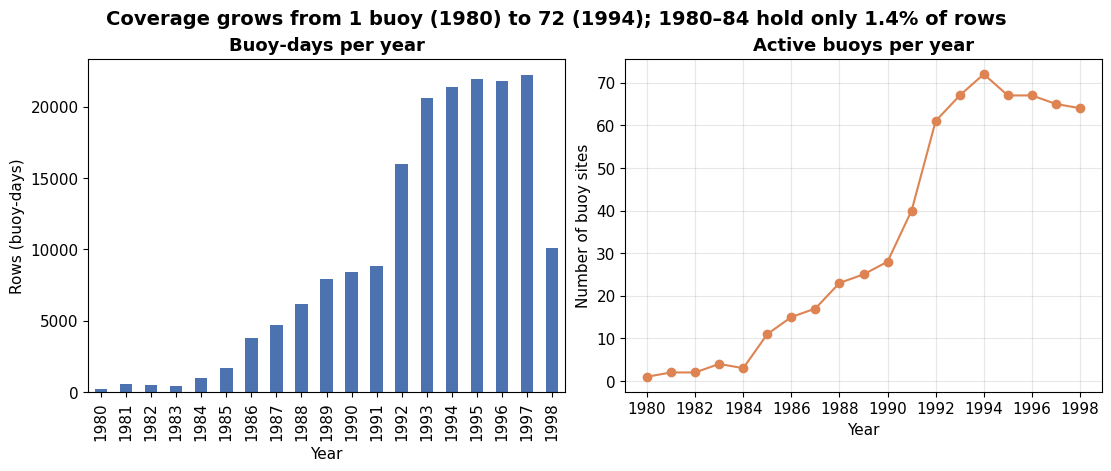

In [ ]:
coverage = daily.groupby("year").agg(rows=("date", "size"), active_buoys=("site", "nunique"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
coverage["rows"].plot(kind="bar", ax=axes[0], color="#4c72b0")
axes[0].set(title="Buoy-days per year", xlabel="Year", ylabel="Rows (buoy-days)")
coverage["active_buoys"].plot(kind="line", marker="o", ax=axes[1], color="#dd8452")
axes[1].set(title="Active buoys per year", xlabel="Year", ylabel="Number of buoy sites")
axes[1].set_xticks(coverage.index[::2])
axes[1].grid(alpha=.3)
early = coverage.loc[:1984, "rows"].sum() / coverage["rows"].sum()
fig.suptitle(f"Coverage grows from {coverage['active_buoys'].iloc[0]} buoy ({coverage.index[0]}) to "
             f"{coverage['active_buoys'].max()} ({coverage['active_buoys'].idxmax()}); "
             f"1980–84 hold only {early:.1%} of rows", fontsize=14, fontweight="bold")
save(fig, "01_coverage.png")
summary["coverage"] = {"rows_1980_84_pct": round(float(early * 100), 1),
                       "max_active_buoys": int(coverage["active_buoys"].max()),
                       "max_active_buoys_year": int(coverage["active_buoys"].idxmax()),
                       "active_buoys_by_year": coverage["active_buoys"].to_dict(),
                       "rows_by_year": coverage["rows"].to_dict()}

### 4.2 Missingness by variable × year

saved charts/02_missingness.png


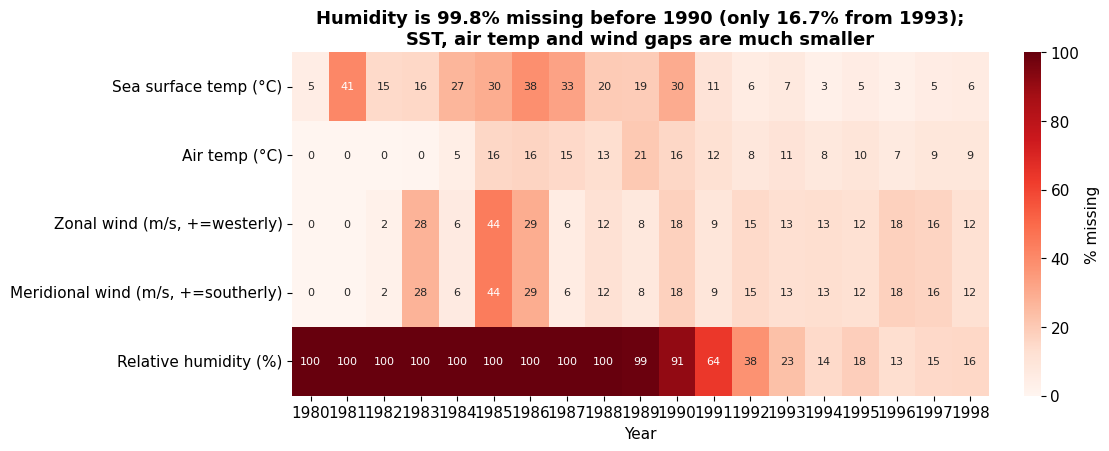

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.4), layout="constrained")
sns.heatmap(missing_by_year.T.rename(index=VAR_LABELS), annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% missing"}, ax=ax, annot_kws={"size": 8})
ax.set(xlabel="Year", ylabel="")
ax.set_title(f"Humidity is {summary['missing_pct_humidity_before_1990']:.1f}% missing before 1990 "
             f"(only {summary['missing_pct_humidity_1993_on']:.1f}% from 1993);\nSST, air temp and wind gaps are much smaller")
save(fig, "02_missingness.png")

### 4.3 Where the buoys are (plotly `scatter_geo`)

plotly static export unavailable: ValueError -> matplotlib fallback map
saved charts/03_buoy_map.png


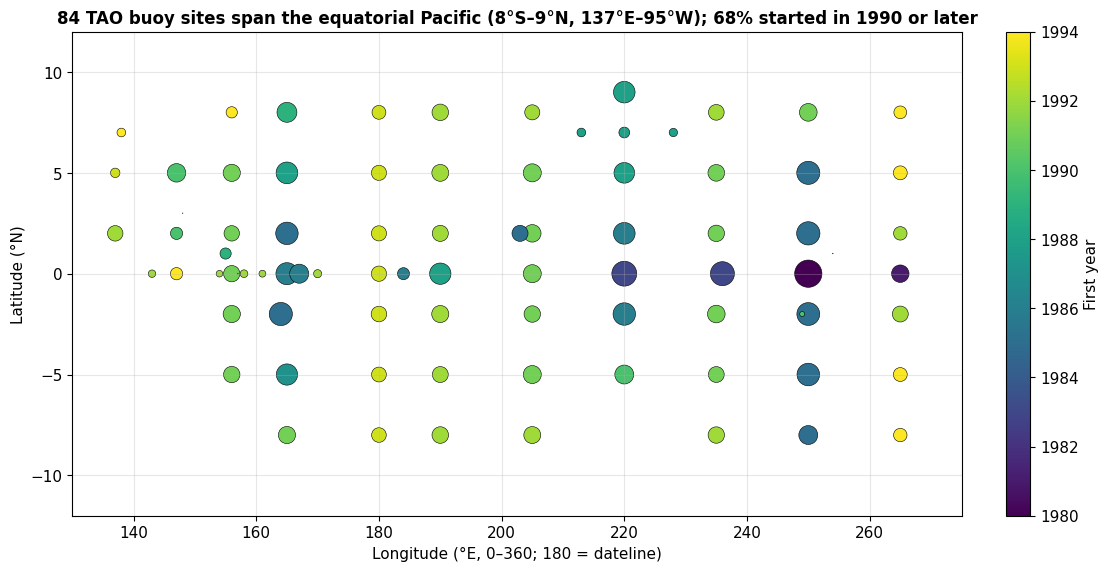

In [ ]:
site_tbl = daily.groupby("site").agg(lat=("site_lat", "first"), lon360=("site_lon", "first"),
                                     days=("date", "size"), first_year=("year", "min")).reset_index()
site_tbl["lon"] = np.where(site_tbl["lon360"] > 180, site_tbl["lon360"] - 360, site_tbl["lon360"])
geo = px.scatter_geo(site_tbl, lat="lat", lon="lon", size="days", color="first_year", hover_name="site",
                     color_continuous_scale="Viridis", size_max=18, projection="natural earth",
                     title=f"{len(site_tbl)} TAO buoy sites span the equatorial Pacific "
                           f"({abs(site_tbl['lat'].min())}°S–{site_tbl['lat'].max()}°N, {site_tbl['lon360'].min()}°E–"
                           f"{360 - site_tbl['lon360'].max()}°W); {(site_tbl['first_year'] >= 1990).mean():.0%} started in 1990 or later")
geo.update_geos(lonaxis_range=[110, 290], lataxis_range=[-25, 25], center=dict(lon=200, lat=0),
                showcountries=True, showland=True, landcolor="#eeeeee")
geo.update_layout(paper_bgcolor="white", margin=dict(l=10, r=10, t=60, b=10),
                  coloraxis_colorbar=dict(title="First year"))
try:  # static export needs kaleido (+ Chrome); in Colab run `!pip install -q kaleido` first or use the fallback
    geo.write_image(CHARTS / "03_buoy_map.png", width=1100, height=560)
except Exception as e:
    print("plotly static export unavailable:", type(e).__name__, "-> matplotlib fallback map")
    fig, ax = plt.subplots(figsize=(11, 5.6), layout="constrained")
    sc = ax.scatter(site_tbl["lon360"], site_tbl["lat"], s=site_tbl["days"] / 15, c=site_tbl["first_year"],
                    cmap="viridis", edgecolor="black", linewidth=.4)
    fig.colorbar(sc, ax=ax, label="First year")
    ax.set(xlim=(130, 275), ylim=(-12, 12), xlabel="Longitude (°E, 0–360; 180 = dateline)", ylabel="Latitude (°N)",
           title=geo.layout.title.text)
    ax.title.set_fontsize(12)
    ax.grid(alpha=.3)
    fig.savefig(CHARTS / "03_buoy_map.png", dpi=DPI, facecolor="white")
print("saved", CHARTS / "03_buoy_map.png")
geo

### 4.4 Monthly SST and air temperature vs ONI
Top: raw monthly array-mean temperatures (left axis) with ONI (right axis).
Bottom: buoy anomalies, which are in °C just like ONI, so they share one axis.

saved charts/04_sst_airtemp_vs_oni.png


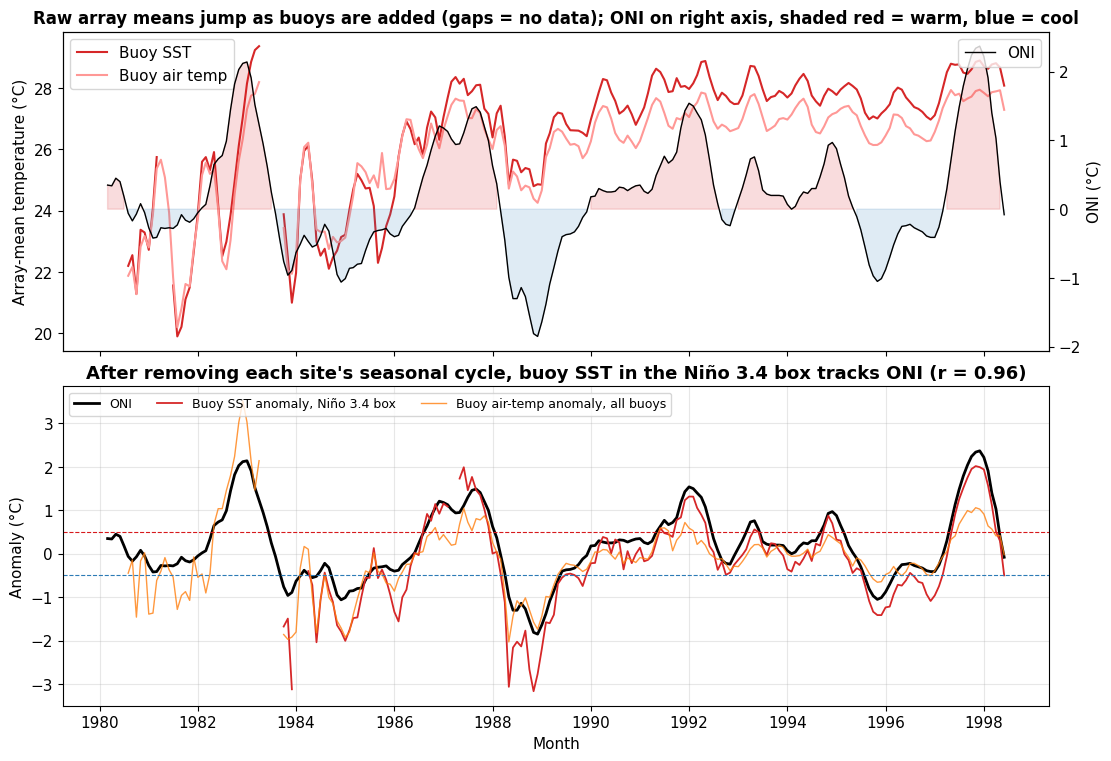

In [ ]:
m_ok = monthly[monthly["enough_buoys"]]
r_box = m_ok["nino34_buoy_sst_anom"].corr(m_ok["oni"])
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, layout="constrained")
ax = axes[0]
ax.plot(monthly["ym"], monthly["sst"], color="#d62728", label="Buoy SST")
ax.plot(monthly["ym"], monthly["air_temp"], color="#ff9896", label="Buoy air temp")
ax.set(ylabel="Array-mean temperature (°C)", xlabel="")
ax2 = ax.twinx()
ax2.fill_between(monthly["ym"], monthly["oni"], 0, where=monthly["oni"] >= 0, color="#d7191c", alpha=.15)
ax2.fill_between(monthly["ym"], monthly["oni"], 0, where=monthly["oni"] < 0, color="#2c7bb6", alpha=.15)
ax2.plot(monthly["ym"], monthly["oni"], color="black", lw=1, label="ONI")
ax2.set_ylabel("ONI (°C)")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.set_title("Raw array means jump as buoys are added (gaps = no data); ONI on right axis, shaded red = warm, blue = cool")
ax.title.set_fontsize(12)
ax = axes[1]
ax.plot(monthly["ym"], monthly["oni"], color="black", lw=2, label="ONI")
ax.plot(monthly["ym"], monthly["nino34_buoy_sst_anom"], color="#d62728", lw=1.3, label="Buoy SST anomaly, Niño 3.4 box")
ax.plot(monthly["ym"], monthly["air_temp_anom"], color="#ff7f0e", lw=1, alpha=.8, label="Buoy air-temp anomaly, all buoys")
ax.axhline(0.5, ls="--", color="#d7191c", lw=.8); ax.axhline(-0.5, ls="--", color="#2c7bb6", lw=.8)
ax.set(ylabel="Anomaly (°C)", xlabel="Month")
ax.legend(loc="upper left", ncol=3, fontsize=9); ax.grid(alpha=.3)
ax.set_title(f"After removing each site's seasonal cycle, buoy SST in the Niño 3.4 box tracks ONI (r = {r_box:.2f})")
save(fig, "04_sst_airtemp_vs_oni.png")

### 4.5 Distribution of each variable by ENSO phase (daily anomalies)
We use daily anomalies so that differences reflect ENSO, not where/when a buoy happened to be.
A standardized difference `(mean El Niño − mean La Niña) / std` ranks which variables separate the phases best (proposal Q2).

phase          La Niña  Neutral  El Niño    std  std_diff
sst_anom        -0.828   -0.159    0.578  0.993     1.417
air_temp_anom   -0.747   -0.139    0.508  0.946     1.327
zon_wind_anom   -0.907   -0.257    0.759  2.479     0.672
humidity_anom    0.407    0.021   -0.159  4.359    -0.130
mer_wind_anom   -0.045    0.079   -0.108  2.106    -0.030
saved charts/05_by_phase_boxplots.png


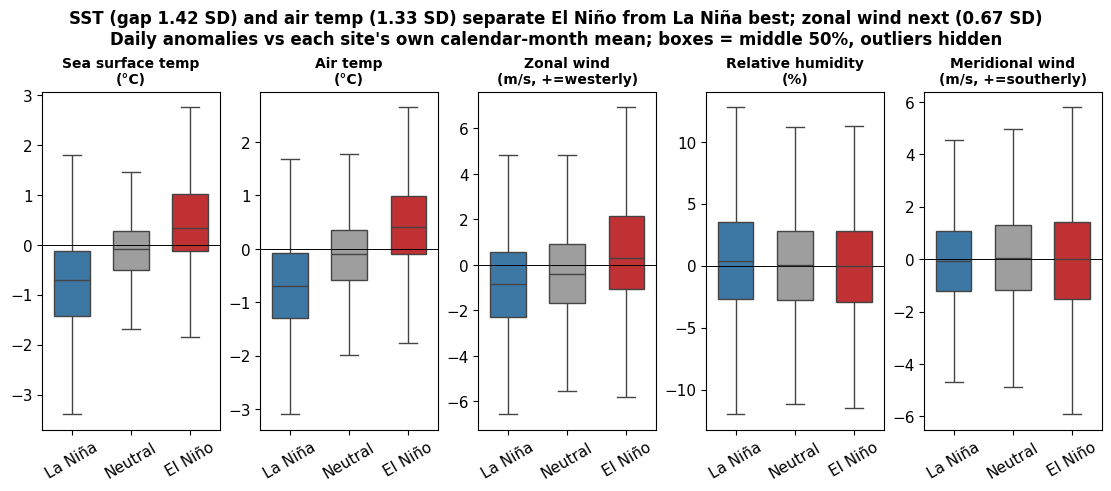

In [ ]:
phase_stats = daily.groupby("phase", observed=True)[ANOMS].mean().T
phase_stats["std"] = daily[ANOMS].std()
phase_stats["std_diff"] = (phase_stats["El Niño"] - phase_stats["La Niña"]) / phase_stats["std"]
phase_stats = phase_stats.sort_values("std_diff", key=abs, ascending=False)
print(phase_stats.round(3))

fig, axes = plt.subplots(1, 5, figsize=(11, 4.8), layout="constrained")
for ax, a in zip(axes, phase_stats.index):
    sns.boxplot(data=daily, x="phase", y=a, hue="phase", order=PHASES, palette=PHASE_COLORS, showfliers=False,
                legend=False, ax=ax, width=.6)
    ax.axhline(0, color="black", lw=.7)
    ax.set(xlabel="", ylabel="", title=VAR_LABELS[a.replace("_anom", "")].replace(" (", "\n("))
    ax.tick_params(axis="x", rotation=30)
    ax.title.set_fontsize(10)
top = phase_stats.index[0].replace("_anom", "")
fig.suptitle(f"SST (gap {phase_stats.loc['sst_anom', 'std_diff']:.2f} SD) and air temp ({phase_stats.loc['air_temp_anom', 'std_diff']:.2f} SD) "
             f"separate El Niño from La Niña best; zonal wind next ({phase_stats.loc['zon_wind_anom', 'std_diff']:.2f} SD)\n"
             "Daily anomalies vs each site's own calendar-month mean; boxes = middle 50%, outliers hidden",
             fontsize=12, fontweight="bold")
save(fig, "05_by_phase_boxplots.png")
summary["phase_daily"] = {
    "daily_rows_per_phase": daily["phase"].value_counts().reindex(PHASES).to_dict(),
    "mean_anomaly_by_phase": phase_stats[PHASES].round(3).to_dict(orient="index"),
    "standardized_gap_elnino_minus_lanina": phase_stats["std_diff"].round(2).to_dict(),
    "ranking_by_abs_gap": [a.replace("_anom", "") for a in phase_stats.index],
}

### 4.6 Correlation of monthly variables with ONI

saved charts/06_corr_heatmap.png


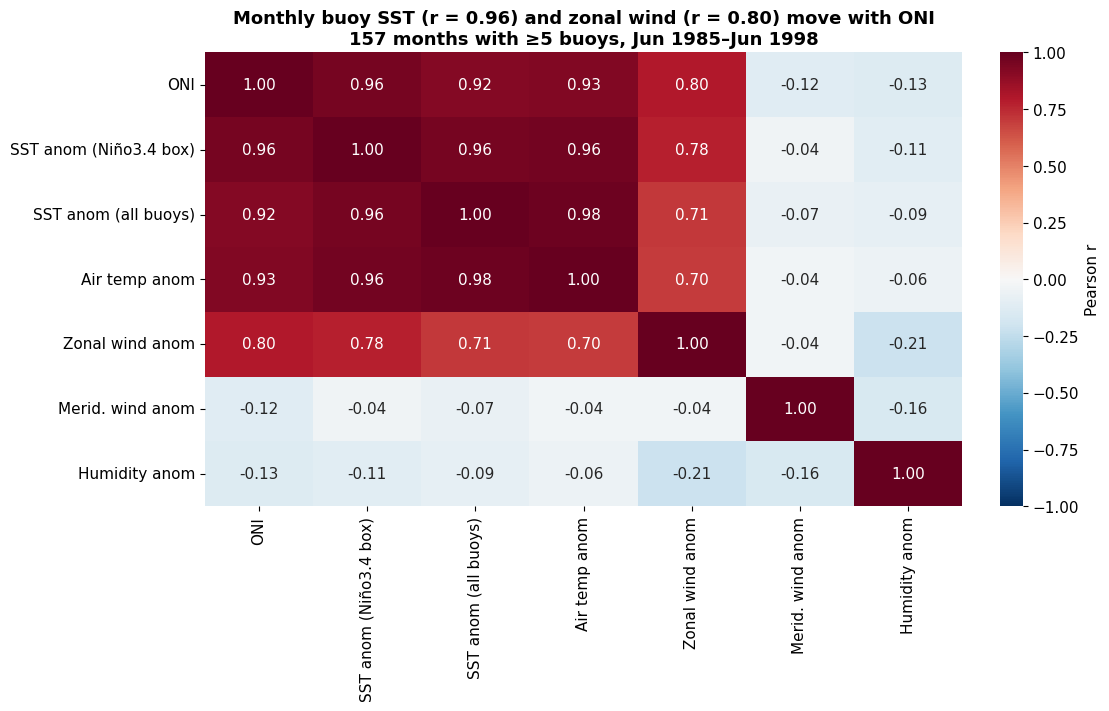

In [ ]:
corr_cols = {"oni": "ONI", "nino34_buoy_sst_anom": "SST anom (Niño3.4 box)", "sst_anom": "SST anom (all buoys)",
             "air_temp_anom": "Air temp anom", "zon_wind_anom": "Zonal wind anom", "mer_wind_anom": "Merid. wind anom",
             "humidity_anom": "Humidity anom"}
corr = m_ok[list(corr_cols)].rename(columns=corr_cols).corr()
fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
sns.heatmap(corr, vmin=-1, vmax=1, annot=True, fmt=".2f", cmap="RdBu_r", ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_title(f"Monthly buoy SST (r = {corr.loc['ONI', 'SST anom (Niño3.4 box)']:.2f}) and zonal wind "
             f"(r = {corr.loc['ONI', 'Zonal wind anom']:.2f}) move with ONI\n"
             f"{len(m_ok)} months with ≥5 buoys, {m_ok['ym'].min():%b %Y}–{m_ok['ym'].max():%b %Y}")
save(fig, "06_corr_heatmap.png")
summary["corr_with_oni_monthly"] = corr["ONI"].drop("ONI").round(2).to_dict()
summary["corr_n_months"] = int(len(m_ok))

### 4.7 Lead/lag: does the buoy signal lead ONI?
`r(k) = corr(buoy variable in month t, ONI in month t+k)`. Positive *k* = the buoy variable **leads** ONI by *k* months.
Caveat: ONI is a centred 3-month mean, so ONI at month *t* already contains month *t+1*.

            SST anom (Niño3.4 box)  SST anom (all buoys)  \
lag_months                                                 
-6                           0.396                 0.431   
-5                           0.508                 0.529   
-4                           0.620                 0.626   
-3                           0.728                 0.720   
-2                           0.830                 0.808   
-1                           0.912                 0.880   
0                            0.957                 0.919   
1                            0.949                 0.912   
2                            0.892                 0.862   
3                            0.803                 0.783   
4                            0.699                 0.693   
5                            0.585                 0.595   
6                            0.465                 0.490   

            Zonal wind anom (all buoys)  
lag_months                               
-6             

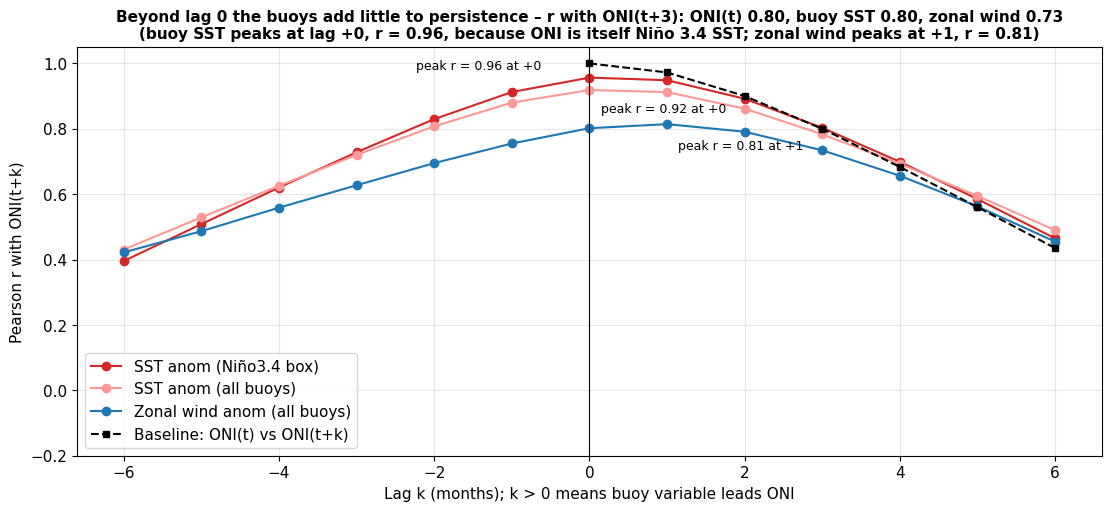

In [ ]:
lag_vars = {"nino34_buoy_sst_anom": "SST anom (Niño3.4 box)", "sst_anom": "SST anom (all buoys)",
            "zon_wind_anom": "Zonal wind anom (all buoys)"}
lags = range(-6, 7)
mm = monthly.copy()
mm.loc[~mm["enough_buoys"], list(lag_vars)] = np.nan  # use only representative months
leadlag = pd.DataFrame({lab: [mm[v].corr(mm["oni"].shift(-k)) for k in lags] for v, lab in lag_vars.items()},
                       index=pd.Index(lags, name="lag_months"))
print(leadlag.round(3))
best = {lab: (int(leadlag[lab].idxmax()), float(leadlag[lab].max())) for lab in leadlag}
# Persistence baseline: how well does ONI(t) itself predict ONI(t+k)? Same months for all series:
# >= 5 buoys and ONI, Niño 3.4-box SST and zonal wind all present.
common = mm["enough_buoys"] & mm[["oni", "nino34_buoy_sst_anom", "zon_wind_anom"]].notna().all(axis=1)
persist = pd.Series([mm.loc[common, "oni"].corr(mm["oni"].shift(-k)[common]) for k in range(0, 7)],
                    index=range(0, 7), name="ONI persistence")
r3 = {v: mm.loc[common, v].corr(mm["oni"].shift(-3)[common]) for v in ["nino34_buoy_sst_anom", "zon_wind_anom"]}

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
leadlag.plot(ax=ax, marker="o", color=["#d62728", "#ff9896", "#1f77b4"])
ax.axvline(0, color="black", lw=.8)
offsets = {"SST anom (Niño3.4 box)": (-125, 6), "SST anom (all buoys)": (8, -16), "Zonal wind anom (all buoys)": (8, -18)}
for lab, (k, r) in best.items():
    ax.annotate(f"peak r = {r:.2f} at {k:+d}", (k, r), textcoords="offset points", xytext=offsets[lab], fontsize=9)
ax.plot(persist.index, persist.values, color="black", ls="--", marker="s", ms=4, label="Baseline: ONI(t) vs ONI(t+k)")
ax.legend(loc="lower left")
ax.set(xlabel="Lag k (months); k > 0 means buoy variable leads ONI", ylabel="Pearson r with ONI(t+k)", ylim=(-0.2, 1.05))
ax.grid(alpha=.3)
zk, zr = best["Zonal wind anom (all buoys)"]
sk, sr = best["SST anom (Niño3.4 box)"]
ax.set_title(f"Beyond lag 0 the buoys add little to persistence – r with ONI(t+3): ONI(t) {persist[3]:.2f}, "
             f"buoy SST {r3['nino34_buoy_sst_anom']:.2f}, zonal wind {r3['zon_wind_anom']:.2f}\n"
             f"(buoy SST peaks at lag {sk:+d}, r = {sr:.2f}, because ONI is itself Niño 3.4 SST; zonal wind peaks at {zk:+d}, r = {zr:.2f})")
ax.title.set_fontsize(11)
save(fig, "07_lead_lag.png")
summary["lead_lag"] = {lab: {"best_lag_months": k, "best_r": round(r, 2), "r_lag0": round(float(leadlag.loc[0, lab]), 2),
                             "r_lead3_minus_r_lag3": round(float(leadlag.loc[3, lab] - leadlag.loc[-3, lab]), 2),
                             "r_by_lag": leadlag[lab].round(2).to_dict()} for lab, (k, r) in best.items()}

### 4.7b Circularity check: buoy variables vs a persistence baseline
ONI *is* the 3-month mean Niño 3.4 SST anomaly, so same-month buoy SST in the Niño 3.4 box is almost the label itself
(r ≈ 0.96 at lag 0 is expected, not a discovery). The useful question is **forecasting**: does a buoy variable at month *t*
tell us anything about ONI at *t + k* that ONI(t) itself does not?
* `level`: corr(x(t), ONI(t+k)) for x = ONI(t) (persistence baseline), buoy SST anomaly, zonal-wind anomaly.
* `change`: corr(x(t), ONI(t+k) − ONI(t)), i.e. does x predict where ONI is **heading**? Persistence predicts "no change" by construction.
All correlations use the same months (≥ 5 buoys, all three series present).

In [ ]:
K = [1, 2, 3, 6]
base_cols = {"oni": "ONI persistence", "nino34_buoy_sst_anom": "SST anom (Niño3.4 box)", "zon_wind_anom": "Zonal wind anom (all buoys)"}
rows = []
for k in K:
    future = mm["oni"].shift(-k)
    change = future - mm["oni"]
    keep = common & future.notna()
    row = {"k_months": k, "n_months": int(keep.sum())}
    for c, lab in base_cols.items():
        row[f"level | {lab}"] = mm.loc[keep, c].corr(future[keep])
        if c != "oni":
            row[f"change | {lab}"] = mm.loc[keep, c].corr(change[keep])
    rows.append(row)
persistence_tbl = pd.DataFrame(rows).set_index("k_months")
persistence_tbl.round(2)

,n_months,level | ONI persistence,level | SST anom (Niño3.4 box),change | SST anom (Niño3.4 box),level | Zonal wind anom (all buoys),change | Zonal wind anom (all buoys)
k_months,,,,,,
1,154,0.97,0.95,-0.04,0.82,0.05
2,153,0.90,0.89,-0.16,0.79,-0.04
3,152,0.80,0.80,-0.25,0.73,-0.13
6,149,0.44,0.46,-0.44,0.44,-0.32


In [ ]:
summary["persistence_vs_buoy"] = {
    "definition": "level: corr(x(t), ONI(t+k)); change: corr(x(t), ONI(t+k)-ONI(t)); months with >=5 buoys and all series present",
    **{f"k{k}": {"n_months": int(persistence_tbl.loc[k, "n_months"]),
                 "oni_persistence_r": round(float(persistence_tbl.loc[k, "level | ONI persistence"]), 2),
                 "buoy_sst_nino34_r": round(float(persistence_tbl.loc[k, "level | SST anom (Niño3.4 box)"]), 2),
                 "zonal_wind_r": round(float(persistence_tbl.loc[k, "level | Zonal wind anom (all buoys)"]), 2),
                 "buoy_sst_nino34_vs_oni_change_r": round(float(persistence_tbl.loc[k, "change | SST anom (Niño3.4 box)"]), 2),
                 "zonal_wind_vs_oni_change_r": round(float(persistence_tbl.loc[k, "change | Zonal wind anom (all buoys)"]), 2)}
       for k in K},
}
summary["persistence_vs_buoy"]

{'definition': 'level: corr(x(t), ONI(t+k)); change: corr(x(t), ONI(t+k)-ONI(t)); months with >=5 buoys and all series present',
 'k1': {'n_months': 154,
  'oni_persistence_r': 0.97,
  'buoy_sst_nino34_r': 0.95,
  'zonal_wind_r': 0.82,
  'buoy_sst_nino34_vs_oni_change_r': -0.04,
  'zonal_wind_vs_oni_change_r': 0.05},
 'k2': {'n_months': 153,
  'oni_persistence_r': 0.9,
  'buoy_sst_nino34_r': 0.89,
  'zonal_wind_r': 0.79,
  'buoy_sst_nino34_vs_oni_change_r': -0.16,
  'zonal_wind_vs_oni_change_r': -0.04},
 'k3': {'n_months': 152,
  'oni_persistence_r': 0.8,
  'buoy_sst_nino34_r': 0.8,
  'zonal_wind_r': 0.73,
  'buoy_sst_nino34_vs_oni_change_r': -0.25,
  'zonal_wind_vs_oni_change_r': -0.13},
 'k6': {'n_months': 149,
  'oni_persistence_r': 0.44,
  'buoy_sst_nino34_r': 0.46,
  'zonal_wind_r': 0.44,
  'buoy_sst_nino34_vs_oni_change_r': -0.44,
  'zonal_wind_vs_oni_change_r': -0.32}}

### 4.8 Case study: the 1997–98 El Niño along the equator
Equatorial buoys (2°S–2°N), monthly SST anomaly by longitude (`pivot_table`, lon × month).

saved charts/08_case_1997_98.png


{'peak_sst_anom_c': 4.73,
 'peak_lon': '124W',
 'peak_month': '1997-11',
 'east_pacific_max_monthly_anom_c': 4.01,
 'east_pacific_max_month': '1997-12',
 'west_pacific_min_monthly_anom_c': -0.79,
 'west_pacific_min_month': '1998-02',
 'oni_peak_1997_98': 2.37}

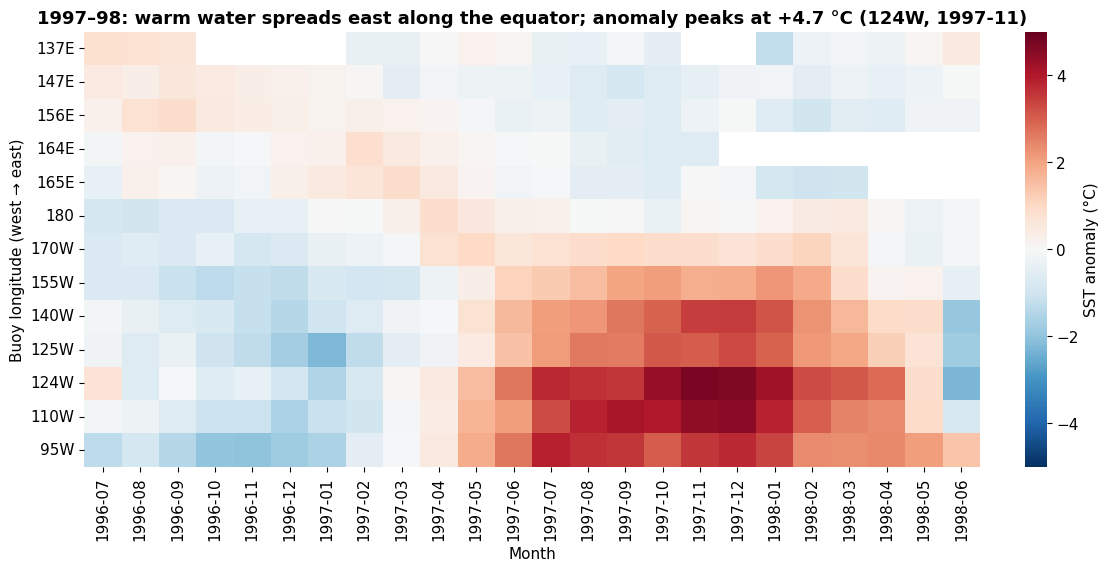

In [ ]:
eq = daily[daily["site_lat"].between(-2, 2) & (daily["date"] >= "1996-07-01")]
case = eq.pivot_table(index="site_lon", columns="ym", values="sst_anom", aggfunc="mean")
case.index = [site_name(0, l).replace("0_", "") for l in case.index]
case.columns = [c.strftime("%Y-%m") for c in case.columns]
peak_val = case.max().max()
peak_month = case.max().idxmax()
peak_lon = case[peak_month].idxmax()
east = eq[eq["site_lon"] >= 235].groupby("ym")["sst_anom"].mean()
west = eq[eq["site_lon"] <= 165].groupby("ym")["sst_anom"].mean()

fig, ax = plt.subplots(figsize=(11, 5.6), layout="constrained")
sns.heatmap(case, cmap="RdBu_r", center=0, vmin=-5, vmax=5, ax=ax, cbar_kws={"label": "SST anomaly (°C)"})
ax.set(xlabel="Month", ylabel="Buoy longitude (west → east)")
ax.set_title(f"1997–98: warm water spreads east along the equator; anomaly peaks at +{peak_val:.1f} °C ({peak_lon}, {peak_month})")
save(fig, "08_case_1997_98.png")
summary["case_1997_98"] = {"peak_sst_anom_c": round(float(peak_val), 2), "peak_lon": peak_lon, "peak_month": peak_month,
                           "east_pacific_max_monthly_anom_c": round(float(east.max()), 2),
                           "east_pacific_max_month": east.idxmax().strftime("%Y-%m"),
                           "west_pacific_min_monthly_anom_c": round(float(west.min()), 2),
                           "west_pacific_min_month": west.idxmin().strftime("%Y-%m"),
                           "oni_peak_1997_98": round(float(oni.loc[oni["ym"].between("1997-01-01", "1998-06-01"), "oni"].max()), 2)}
summary["case_1997_98"]

### 4.9 Autocorrelation of daily SST (TA comment)
For each buoy with ≥ 1 year of data we put its SST on a complete daily calendar (`asfreq("D")`, gaps stay NaN) and
compute `Series.autocorr(lag)`. We report the median across buoys, for raw SST and for SST anomalies.

            sst  sst_anom
lag_days                 
1         0.979     0.963
7         0.880     0.799
30        0.735     0.683
saved charts/09_autocorr.png


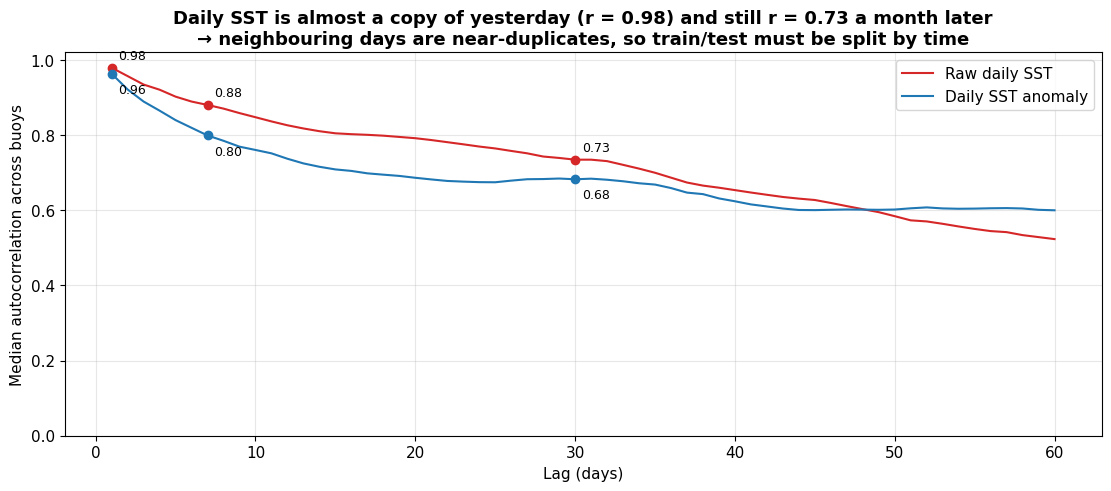

In [ ]:
def site_acf(g, col, lag):
    s = g.set_index("date")[col].asfreq("D")
    return s.autocorr(lag)


big_sites = daily.groupby("site").filter(lambda g: g["sst"].notna().sum() >= 365)
acf_lags = list(range(1, 61))
acf = pd.DataFrame({
    col: [big_sites.groupby("site")[["date", col]].apply(site_acf, col=col, lag=k).median() for k in acf_lags]
    for col in ["sst", "sst_anom"]}, index=pd.Index(acf_lags, name="lag_days"))
print(acf.loc[[1, 7, 30]].round(3))

fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
acf.rename(columns={"sst": "Raw daily SST", "sst_anom": "Daily SST anomaly"}).plot(ax=ax, color=["#d62728", "#1f77b4"])
for k in [1, 7, 30]:
    for col, c, dy in [("sst", "#d62728", 6), ("sst_anom", "#1f77b4", -14)]:
        ax.scatter(k, acf.loc[k, col], color=c, zorder=3)
        ax.annotate(f"{acf.loc[k, col]:.2f}", (k, acf.loc[k, col]), textcoords="offset points", xytext=(5, dy), fontsize=9)
ax.set(xlabel="Lag (days)", ylabel="Median autocorrelation across buoys", ylim=(0, 1.02))
ax.grid(alpha=.3)
ax.set_title(f"Daily SST is almost a copy of yesterday (r = {acf.loc[1, 'sst']:.2f}) and still r = {acf.loc[30, 'sst']:.2f} "
             "a month later\n→ neighbouring days are near-duplicates, so train/test must be split by time")
save(fig, "09_autocorr.png")
summary["autocorr_daily_sst"] = {f"lag_{k}d": round(float(acf.loc[k, "sst"]), 2) for k in [1, 7, 30]}
summary["autocorr_daily_sst_anom"] = {f"lag_{k}d": round(float(acf.loc[k, "sst_anom"]), 2) for k in [1, 7, 30]}
summary["autocorr_n_buoys"] = int(big_sites["site"].nunique())

### 4.10 Time-based train/test split
Candidate cut years: train = years ≤ cut, test = years > cut. We count **months with buoy data** in each phase on
each side. A cut is valid only if every phase has ≥ 6 months on both sides. Among valid cuts we choose the one whose
test set is as small as possible, i.e. the **latest** valid cut (most history for training, and the test set still
contains at least one complete El Niño and one La Niña episode).

In [ ]:
mdata = monthly[monthly["n_rows"] > 0].copy()
mdata["year"] = mdata["ym"].dt.year
rows_by_year = daily.groupby("year").size()
cand = []
for cut in range(1985, 1997):
    tr = mdata[mdata["year"] <= cut]["phase"].value_counts().reindex(PHASES, fill_value=0)
    te = mdata[mdata["year"] > cut]["phase"].value_counts().reindex(PHASES, fill_value=0)
    cand.append({"train_through": cut, **{f"train_{p}": tr[p] for p in PHASES}, **{f"test_{p}": te[p] for p in PHASES},
                 "test_row_share": rows_by_year[rows_by_year.index > cut].sum() / len(daily)})
cand = pd.DataFrame(cand)
phase_cols = [f"{side}_{p}" for side in ("train", "test") for p in PHASES]
cand["valid"] = (cand[phase_cols] >= 6).all(axis=1)
print(cand.round(2).to_string(index=False))
chosen = cand[cand["valid"]].sort_values("train_through").iloc[-1]
CUT = int(chosen["train_through"])
print("chosen cut: train <=", CUT, "| test >=", CUT + 1)

 train_through  train_La Niña  train_Neutral  train_El Niño  test_La Niña  test_Neutral  test_El Niño  test_row_share  valid
          1985             16             33             12            21            78            51            0.98   True
          1986             16             41             16            21            70            47            0.95   True
          1987             16             41             28            21            70            35            0.93   True
          1988             24             44             29            13            67            34            0.89   True
          1989             29             51             29             8            60            34            0.85   True
          1990             29             63             29             8            48            34            0.80   True
          1991             29             68             36             8            43            27            0.75   True


{'Random split': 81.31, 'Time split (≤1994 / ≥1995)': 0.08}
phase  La Niña  Neutral  El Niño
split                           
train       29       91       49
test         8       20       14
phase       La Niña  Neutral  El Niño
split_time                           
train          8509    60932    32553
test          14333    36026    25727
saved charts/10_time_split.png


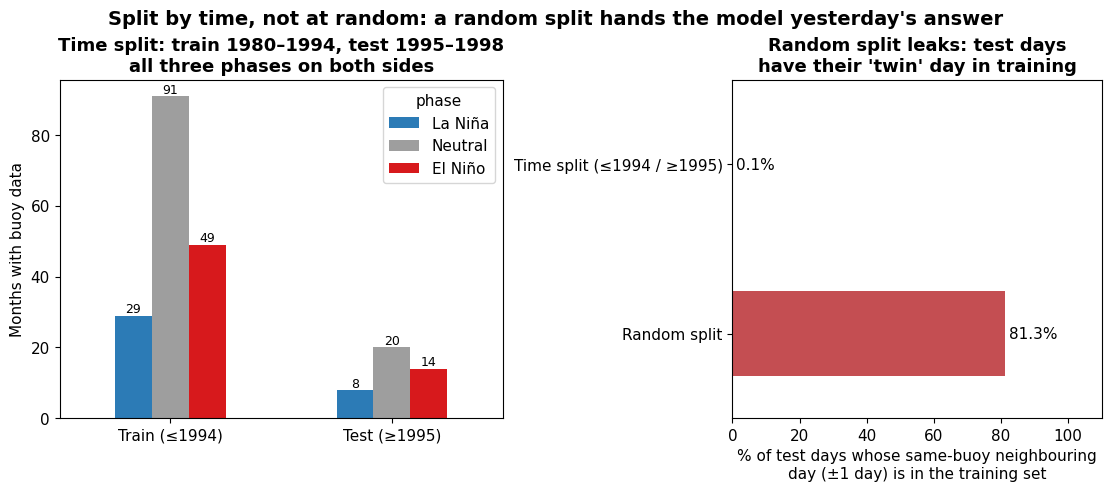

In [ ]:
daily["split_time"] = np.where(daily["year"] <= CUT, "train", "test")
test_share = float((daily["split_time"] == "test").mean())
rng = np.random.default_rng(212)
daily["split_random"] = np.where(rng.random(len(daily)) < test_share, "test", "train")


def neighbour_in_train(split_col):
    """% of test rows whose same-buoy previous or next day is in the training set."""
    keys = daily[["site", "date", split_col]]
    train_keys = keys[keys[split_col] == "train"][["site", "date"]].assign(in_train=True)
    test = keys[keys[split_col] == "test"][["site", "date"]]
    hit = pd.Series(False, index=test.index)
    for step in [-1, 1]:
        nb = test.assign(date=test["date"] + pd.Timedelta(days=step)).merge(
            train_keys, on=["site", "date"], how="left", validate="many_to_one")
        hit = hit | nb["in_train"].notna().to_numpy()  # matched neighbours carry True, unmatched ones NaN
    return float(hit.mean() * 100)


leak = {"Random split": neighbour_in_train("split_random"), f"Time split (≤{CUT} / ≥{CUT + 1})": neighbour_in_train("split_time")}
print({k: round(v, 2) for k, v in leak.items()})

mdata["split"] = np.where(mdata["year"] <= CUT, "train", "test")
split_counts = pd.crosstab(mdata["split"], mdata["phase"]).reindex(index=["train", "test"], columns=PHASES)
split_rows = pd.crosstab(daily["split_time"], daily["phase"]).reindex(index=["train", "test"], columns=PHASES)
print(split_counts); print(split_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1]})
split_counts.plot(kind="bar", ax=axes[0], color=[PHASE_COLORS[p] for p in PHASES], rot=0)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=9)
axes[0].set(xlabel="", ylabel="Months with buoy data",
            title=f"Time split: train {mdata['ym'].min():%Y}–{CUT}, test {CUT + 1}–{mdata['ym'].max():%Y}\nall three phases on both sides")
axes[0].set_xticks([0, 1], [f"Train (≤{CUT})", f"Test (≥{CUT + 1})"])
lk = pd.Series(leak)
lk.plot(kind="barh", ax=axes[1], color=["#c44e52", "#55a868"])
for i, v in enumerate(lk):
    axes[1].text(v + 1, i, f"{v:.1f}%", va="center")
axes[1].set(xlim=(0, 110), xlabel="% of test days whose same-buoy neighbouring\nday (±1 day) is in the training set",
            title="Random split leaks: test days\nhave their 'twin' day in training")
fig.suptitle("Split by time, not at random: a random split hands the model yesterday's answer", fontsize=14, fontweight="bold")
save(fig, "10_time_split.png")

summary["time_split"] = {
    "rule": "valid if every phase has >=6 months with data on both sides; choose the latest valid cut (largest training period)",
    "train_through_year": CUT, "test_from_year": CUT + 1,
    "test_share_daily_rows_pct": round(test_share * 100, 1),
    "months_by_phase": {s: split_counts.loc[s].astype(int).to_dict() for s in split_counts.index},
    "daily_rows_by_phase": {s: split_rows.loc[s].astype(int).to_dict() for s in split_rows.index},
    "candidate_cuts": cand[["train_through", "valid"]].assign(test_row_share=cand["test_row_share"].round(3)).to_dict(orient="records"),
    "test_days_with_neighbour_in_train_pct": {k: round(v, 1) for k, v in leak.items()},
}
summary["months_per_phase_all"] = mdata["phase"].value_counts().reindex(PHASES).astype(int).to_dict()
summary["months_with_data"] = int(len(mdata))

## 5. From El Niño to Los Angeles winter rain: a seasonal flood-risk outlook
The project's practical goal is **disaster prevention**. The chain we test here is:

**equatorial buoys → ONI (El Niño strength) → more Pacific storms reaching Southern California → heavy-rain days →
floods and debris flows (especially below recent burn scars) → preparation** (clearing debris basins, sandbags,
emergency staffing, insurance and supply planning).

Timing is what makes this useful: CPC publishes the Aug–Oct (ASO) ONI in early November, while Los Angeles gets most
of its heavy rain in Dec–Mar. A fall ONI reading therefore gives **1–4 months of warning**.
This is a **seasonal risk outlook** ("this winter is more likely to be wet"), not a daily weather forecast.

Outcome data: NOAA GHCN-Daily station **USW00093134, Los Angeles Downtown (USC)**, daily precipitation (the station file starts in April 1906; we use the 1950–2025 seasons).

In [ ]:
LA_URL = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00093134.csv"
LA_FILE = RAW / "USW00093134.csv"
if not os.path.exists(LA_FILE):
    print("downloading", LA_URL)
    urllib.request.urlretrieve(LA_URL, LA_FILE)

la = pd.read_csv(LA_FILE, usecols=["STATION", "DATE", "NAME", "PRCP", "PRCP_ATTRIBUTES"], low_memory=False)
la["DATE"] = pd.to_datetime(la["DATE"])
print(la.shape, la["DATE"].min().date(), "to", la["DATE"].max().date())
print(la["NAME"].iloc[0])
la.head()

downloading https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00093134.csv
(41415, 5) 1906-04-01 to 2026-11-15
LOS ANGELES DOWNTOWN USC, CA US


,STATION,DATE,NAME,PRCP,PRCP_ATTRIBUTES
0,USW00093134,1906-04-01,"LOS ANGELES DOWNTOWN USC, CA US",NaN,NaN
1,USW00093134,1906-04-02,"LOS ANGELES DOWNTOWN USC, CA US",NaN,NaN
2,USW00093134,1906-04-03,"LOS ANGELES DOWNTOWN USC, CA US",NaN,NaN
3,USW00093134,1906-04-04,"LOS ANGELES DOWNTOWN USC, CA US",76.0,",,6,2400"
4,USW00093134,1906-04-05,"LOS ANGELES DOWNTOWN USC, CA US",152.0,",,6,2400"


### 5.1 Clean
* `PRCP` is in **tenths of mm** → `mm = PRCP / 10`.
* `PRCP_ATTRIBUTES` is `"measurement,quality,source,time"`; a non-blank **quality flag** means the value failed a NOAA check → set to NaN.
* A **rain season** runs Jul–Jun and is labelled by its start year (season 1997 = Jul 1997 – Jun 1998), so one wet winter is not split across two calendar years.
* Keep seasons 1950–2025 whose Oct–Apr rows number ≥ 210 and whose non-missing `mm` covers ≥ 95 % of those rows.

In [ ]:
la["mm"] = pd.to_numeric(la["PRCP"], errors="coerce") / 10
qflag = la["PRCP_ATTRIBUTES"].fillna(",,,").astype(str).str.split(",", expand=True)[1].fillna("").str.strip()
n_qflagged = int((qflag != "").sum())
la.loc[qflag != "", "mm"] = np.nan
print("values removed by quality flag:", n_qflagged, "| flags:", qflag[qflag != ""].value_counts().to_dict())

la["year"] = la["DATE"].dt.year
la["month"] = la["DATE"].dt.month
la["season"] = np.where(la["month"] >= 7, la["year"], la["year"] - 1)
la["heavy_day"] = la["mm"] >= 25.4  # at least 1 inch in a day

wet_months = [10, 11, 12, 1, 2, 3, 4]
coverage_la = la[la["month"].isin(wet_months)].groupby("season").agg(rows=("DATE", "size"), valid=("mm", "count"))
coverage_la["ok"] = (coverage_la["rows"] >= 210) & (coverage_la["valid"] >= 0.95 * coverage_la["rows"])
candidate = coverage_la.loc[1950:2025]
good_seasons = candidate.index[candidate["ok"]]
print(f"seasons 1950–2025: {len(candidate)}, passing coverage rule: {len(good_seasons)}")

values removed by quality flag: 17 | flags: {'K': 17}
seasons 1950–2025: 76, passing coverage rule: 76


### 5.2 Season table labelled with the fall (ASO) ONI
* `inches` = total Jul–Jun rain; `heavy` = number of days with ≥ 1 inch (25.4 mm), the days that drive local flooding.
* Label = ONI of the **ASO** season of the start year (known in early November), phase by the same ±0.5 rule (`np.select`).

In [ ]:
seasons = (la[la["season"].isin(good_seasons)]
           .groupby("season")
           .agg(mm=("mm", "sum"), heavy=("heavy_day", "sum"))
           .reset_index())
seasons["inches"] = seasons["mm"] / 25.4

aso = oni.loc[oni["SEAS"] == "ASO", ["year", "oni"]].rename(columns={"year": "season", "oni": "aso_oni"})
seasons = seasons.merge(aso, on="season", how="left", validate="one_to_one", indicator=True)
print(seasons["_merge"].value_counts().to_dict())
seasons = seasons.drop(columns="_merge")
seasons["phase"] = np.select([seasons["aso_oni"] >= 0.5, seasons["aso_oni"] <= -0.5], ["El Niño", "La Niña"], default="Neutral")
seasons.round(2).tail()

{'both': 76, 'left_only': 0, 'right_only': 0}


,season,mm,heavy,inches,aso_oni,phase
71,2021,315.2,5,12.41,-0.64,La Niña
72,2022,721.7,11,28.41,-0.87,La Niña
73,2023,639.8,8,25.19,1.50,El Niño
74,2024,207.7,2,8.18,-0.12,Neutral
75,2025,484.5,7,19.07,-0.43,Neutral


### 5.3 Rainfall by fall ENSO phase
"Wet" = season total above the median of all seasons.

In [ ]:
LA_PHASES = ["El Niño", "Neutral", "La Niña"]
la_median = seasons["inches"].median()
seasons["wet"] = seasons["inches"] > la_median
by_phase_la = (seasons.groupby("phase")
               .agg(n=("season", "size"), median_in=("inches", "median"), wet=("wet", "sum"),
                    wet_share=("wet", "mean"), heavy_mean=("heavy", "mean"))
               .reindex(LA_PHASES))
print(f"median season rainfall, {seasons['season'].min()}–{seasons['season'].max()}: {la_median:.2f} in")
by_phase_la.round(2)

median season rainfall, 1950–2025: 12.41 in


,n,median_in,wet,wet_share,heavy_mean
phase,,,,,
El Niño,20,17.67,13,0.65,5.70
Neutral,38,11.09,17,0.45,4.05
La Niña,18,12.14,8,0.44,3.11


In [ ]:
# When do the heavy (>= 1 inch) days happen?
heavy_days = la[la["season"].isin(good_seasons) & la["heavy_day"]]
heavy_by_month = heavy_days.groupby("month").size().reindex([7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6], fill_value=0)
dec_mar_share = heavy_days["month"].isin([12, 1, 2, 3]).mean()
print(f"heavy days: {len(heavy_days)}, share in Dec–Mar: {dec_mar_share:.3f}")

# Strongest falls since 1950 and where this fall ranks
top_falls = seasons.sort_values("aso_oni", ascending=False).head(4)[["season", "aso_oni", "inches", "heavy"]]
aso_hist = aso[aso["season"].between(1950, 2026)].copy()
aso_hist["rank"] = aso_hist["aso_oni"].rank(ascending=False, method="min").astype(int)
aso_2026 = aso_hist.loc[aso_hist["season"] == 2026].iloc[0]
s2026 = la[la["season"] == 2026]
season_to_date_in = s2026["mm"].sum() / 25.4
last_date = s2026["DATE"].max()
print(top_falls.round(2).to_string(index=False))
print(f"ASO 2026 = {aso_2026['aso_oni']:.2f}, rank {int(aso_2026['rank'])} of {len(aso_hist)} falls 1950–2026; "
      f"2026–27 season to date: {season_to_date_in:.2f} in through {last_date.date()}")

heavy days: 324, share in Dec–Mar: 0.824
 season  aso_oni  inches  heavy
   1997     2.04   31.03     11
   2015     2.02    9.67      2
   1965     1.55   20.44      6
   2023     1.50   25.19      8
ASO 2026 = 2.46, rank 1 of 77 falls 1950–2026; 2026–27 season to date: 2.44 in through 2026-11-15


### 5.4 Does it hold on later years? (time split, TA comment)
Same logic as section 4.10: train = seasons ≤ 2014, test = 2015–2025. The "wet" threshold is the **training** median only,
so nothing from the test years leaks into the definition.

In [ ]:
seasons["split"] = np.where(seasons["season"] <= 2014, "train", "test")
seasons["fall_el_nino"] = np.where(seasons["phase"] == "El Niño", "El Niño fall", "Other fall")
train_median = seasons.loc[seasons["split"] == "train", "inches"].median()
seasons["wet_train_thr"] = seasons["inches"] > train_median
split_la = (seasons.groupby(["split", "fall_el_nino"])
            .agg(n=("season", "size"), wet=("wet_train_thr", "sum"), wet_share=("wet_train_thr", "mean"),
                 heavy_mean=("heavy", "mean"))
            .reindex(pd.MultiIndex.from_product([["train", "test"], ["El Niño fall", "Other fall"]])))
test_el_nino_seasons = seasons.loc[(seasons["split"] == "test") & (seasons["phase"] == "El Niño"), "season"].tolist()
print(f"train median = {train_median:.2f} in; test El Niño falls: {test_el_nino_seasons}")
split_la.round(2)

train median = 12.32 in; test El Niño falls: [2015, 2018, 2023]


n  wet  wet_share  heavy_mean
train El Niño fall  17   11       0.65        5.76
      Other fall    48   21       0.44        3.56
test  El Niño fall   3    2       0.67        5.33
      Other fall     8    5       0.62        4.88

**Reading the split.** In 1950–2014 an El Niño fall clearly raises the odds of a wet winter and of more ≥ 1-inch days.
The 2015–2025 test decade is small: it had only 3 El Niño falls (one of them, 2015, a famously dry "strong El Niño" winter in LA)
and several very wet non-El Niño winters. So on recent data ONI alone **raises the odds but cannot confirm** the effect;
a real outlook should combine it with other signals and always report the base rate.

saved charts/11_oni_vs_la_rain.png


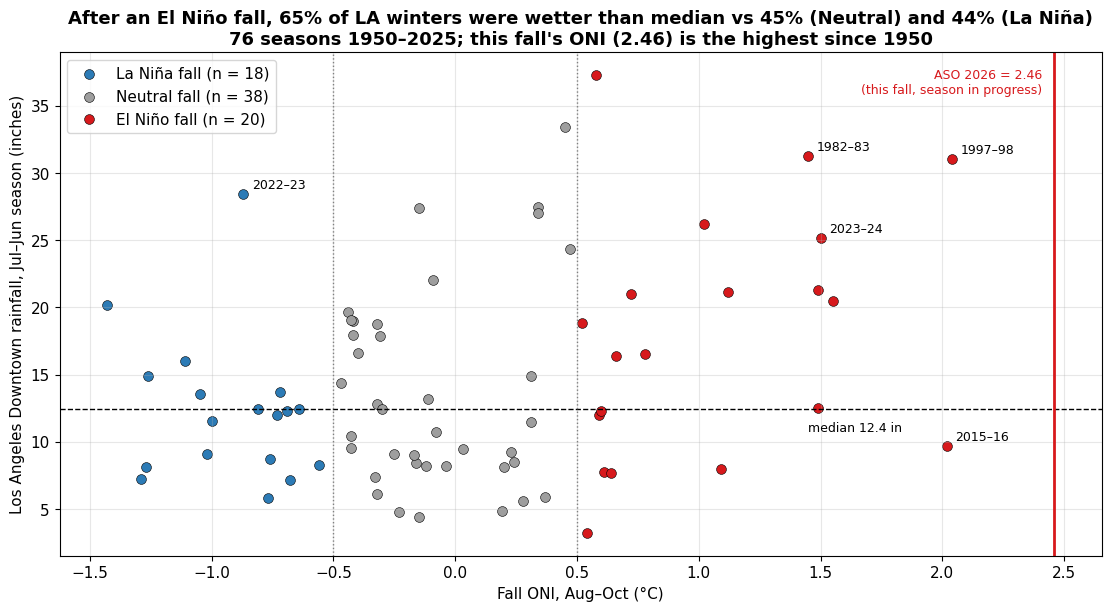

In [ ]:
# Chart 11: fall ONI vs LA season rainfall
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
for p in PHASES:
    d = seasons[seasons["phase"] == p]
    ax.scatter(d["aso_oni"], d["inches"], color=PHASE_COLORS[p], s=50, edgecolor="black", linewidth=.4,
               label=f"{p} fall (n = {len(d)})")
ax.axhline(la_median, ls="--", color="black", lw=1)
ax.text(1.45, la_median - 1.6, f"median {la_median:.1f} in", fontsize=9)
for x in [-0.5, 0.5]:
    ax.axvline(x, ls=":", color="gray", lw=1)
for yr in [1982, 1997, 2015, 2022, 2023]:
    r = seasons.loc[seasons["season"] == yr].iloc[0]
    ax.annotate(f"{yr}–{str(yr + 1)[-2:]}", (r["aso_oni"], r["inches"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.axvline(aso_2026["aso_oni"], color="#d7191c", lw=2)
ax.text(aso_2026["aso_oni"] - 0.05, ax.get_ylim()[1] * 0.97, f"ASO 2026 = {aso_2026['aso_oni']:.2f}\n(this fall, season in progress)",
        ha="right", va="top", fontsize=9, color="#d7191c")
ax.set(xlabel="Fall ONI, Aug–Oct (°C)", ylabel="Los Angeles Downtown rainfall, Jul–Jun season (inches)")
ax.grid(alpha=.3)
ax.legend(loc="upper left")
ax.set_title(f"After an El Niño fall, {by_phase_la.loc['El Niño', 'wet_share']:.0%} of LA winters were wetter than median "
             f"vs {by_phase_la.loc['Neutral', 'wet_share']:.0%} (Neutral) and {by_phase_la.loc['La Niña', 'wet_share']:.0%} (La Niña)\n"
             f"{len(seasons)} seasons {seasons['season'].min()}–{seasons['season'].max()}; this fall's ONI "
             f"({aso_2026['aso_oni']:.2f}) is the highest since 1950")
save(fig, "11_oni_vs_la_rain.png")

saved charts/12_la_rain_by_phase.png


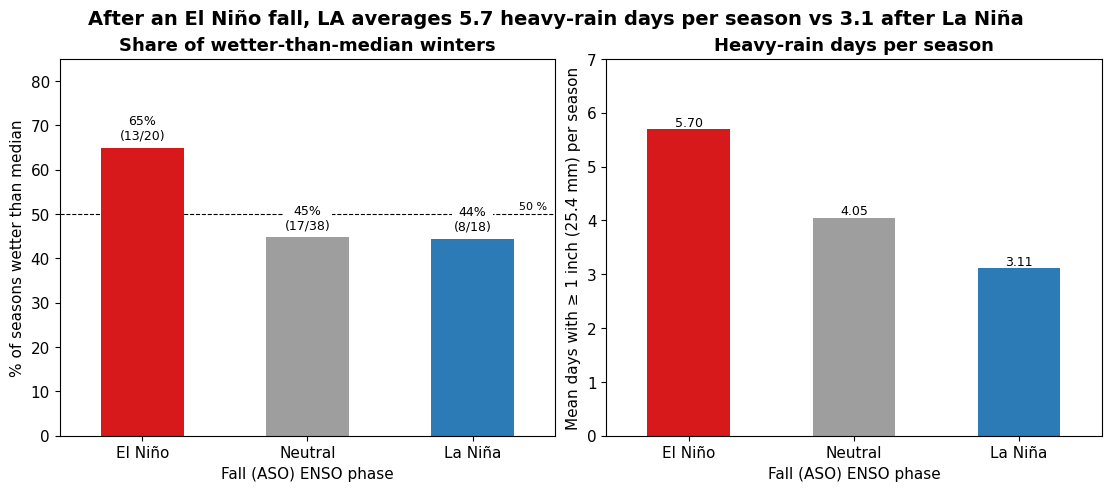

In [ ]:
# Chart 12: wet share and heavy-rain days by phase
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
colors = [PHASE_COLORS[p] for p in LA_PHASES]
(by_phase_la["wet_share"] * 100).plot(kind="bar", ax=axes[0], color=colors, rot=0)
wet_labels = axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.0%}\n({w}/{n})" for v, w, n in
                               zip(by_phase_la["wet_share"], by_phase_la["wet"], by_phase_la["n"])], fontsize=9, padding=4)
for t in wet_labels:
    t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1))
axes[0].axhline(50, ls="--", color="black", lw=.8, zorder=0)
axes[0].text(2.45, 51, "50 %", ha="right", fontsize=8)
axes[0].set(xlabel="Fall (ASO) ENSO phase", ylabel="% of seasons wetter than median", ylim=(0, 85),
            title="Share of wetter-than-median winters")
by_phase_la["heavy_mean"].plot(kind="bar", ax=axes[1], color=colors, rot=0)
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", fontsize=9)
axes[1].set(xlabel="Fall (ASO) ENSO phase", ylabel="Mean days with ≥ 1 inch (25.4 mm) per season", ylim=(0, 7),
            title="Heavy-rain days per season")
fig.suptitle(f"After an El Niño fall, LA averages {by_phase_la.loc['El Niño', 'heavy_mean']:.1f} heavy-rain days per season "
             f"vs {by_phase_la.loc['La Niña', 'heavy_mean']:.1f} after La Niña", fontsize=14, fontweight="bold")
save(fig, "12_la_rain_by_phase.png")

saved charts/13_heavy_rain_months.png


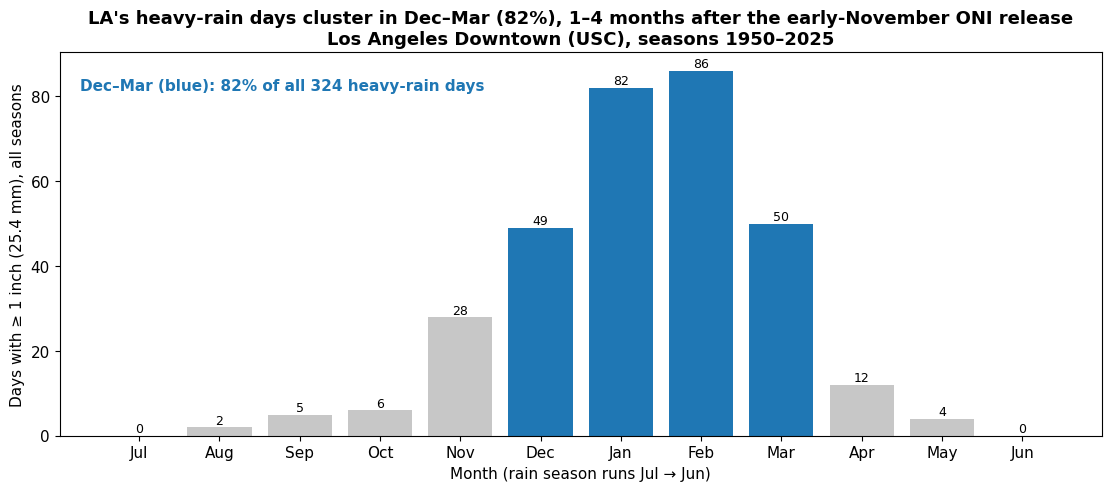

In [ ]:
# Chart 13: when the >= 1-inch days happen
month_names = pd.to_datetime([f"2000-{m:02d}-01" for m in heavy_by_month.index]).strftime("%b")
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
bar_colors = ["#1f77b4" if m in [12, 1, 2, 3] else "#c7c7c7" for m in heavy_by_month.index]
ax.bar(month_names, heavy_by_month.values, color=bar_colors)
ax.bar_label(ax.containers[0], fontsize=9)
ax.text(0.02, 0.9, f"Dec–Mar (blue): {dec_mar_share:.0%} of all {len(heavy_days)} heavy-rain days", transform=ax.transAxes,
        fontsize=11, color="#1f77b4", fontweight="bold")
ax.set(xlabel="Month (rain season runs Jul → Jun)", ylabel="Days with ≥ 1 inch (25.4 mm), all seasons")
ax.set_title(f"LA's heavy-rain days cluster in Dec–Mar ({dec_mar_share:.0%}), 1–4 months after the early-November ONI release\n"
             f"Los Angeles Downtown (USC), seasons {seasons['season'].min()}–{seasons['season'].max()}")
save(fig, "13_heavy_rain_months.png")

In [ ]:
def split_block(split):
    out = {}
    for grp, key in [("El Niño fall", "el_nino"), ("Other fall", "other")]:
        r = split_la.loc[(split, grp)]
        out[key] = {"n": int(r["n"]), "wet": int(r["wet"]), "wet_share": round(float(r["wet_share"]), 2),
                    "heavy_mean": round(float(r["heavy_mean"]), 2)}
    return out


summary["la_rain"] = {
    "station_id": str(la["STATION"].iloc[0]), "station_name": str(la["NAME"].iloc[0]), "source_url": LA_URL,
    "values_removed_by_quality_flag": n_qflagged,
    "season_definition": "Jul-Jun, labelled by start year; label = ONI ASO of the start year",
    "seasons_first": int(seasons["season"].min()), "seasons_last": int(seasons["season"].max()),
    "n_seasons": int(len(seasons)), "n_seasons_candidate": int(len(candidate)),
    "median_inches": round(float(la_median), 2),
    "by_phase": {p: {"n": int(r["n"]), "median_in": round(float(r["median_in"]), 2), "wet": int(r["wet"]),
                     "wet_share": round(float(r["wet_share"]), 2), "heavy_mean": round(float(r["heavy_mean"]), 2)}
                 for p, r in by_phase_la.iterrows()},
    "n_heavy_days": int(len(heavy_days)), "dec_mar_share": round(float(dec_mar_share), 3),
    "heavy_days_by_month": {str(k): int(v) for k, v in heavy_by_month.items()},
    "top_falls": [{"season": int(r["season"]), "aso_oni": round(float(r["aso_oni"]), 2), "inches": round(float(r["inches"]), 2),
                   "heavy": int(r["heavy"])} for _, r in top_falls.iterrows()],
    "aso_2026": round(float(aso_2026["aso_oni"]), 2), "aso_2026_rank": int(aso_2026["rank"]),
    "aso_rank_out_of": int(len(aso_hist)),
    "season_2026_to_date_inches": round(float(season_to_date_in), 2), "season_2026_last_date": str(last_date.date()),
    "time_split": {"train_seasons": "<=2014", "test_seasons": "2015-2025", "train_median_inches": round(float(train_median), 2),
                   "test_el_nino_seasons": [int(s) for s in test_el_nino_seasons],
                   "train": split_block("train"), "test": split_block("test")},
}
summary["la_rain"]

{'station_id': 'USW00093134',
 'station_name': 'LOS ANGELES DOWNTOWN USC, CA US',
 'source_url': 'https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00093134.csv',
 'values_removed_by_quality_flag': 17,
 'season_definition': 'Jul-Jun, labelled by start year; label = ONI ASO of the start year',
 'seasons_first': 1950,
 'seasons_last': 2025,
 'n_seasons': 76,
 'n_seasons_candidate': 76,
 'median_inches': 12.41,
 'by_phase': {'El Niño': {'n': 20,
   'median_in': 17.67,
   'wet': 13,
   'wet_share': 0.65,
   'heavy_mean': 5.7},
  'Neutral': {'n': 38,
   'median_in': 11.09,
   'wet': 17,
   'wet_share': 0.45,
   'heavy_mean': 4.05},
  'La Niña': {'n': 18,
   'median_in': 12.14,
   'wet': 8,
   'wet_share': 0.44,
   'heavy_mean': 3.11}},
 'n_heavy_days': 324,
 'dec_mar_share': 0.824,
 'heavy_days_by_month': {'7': 0,
  '8': 2,
  '9': 5,
  '10': 6,
  '11': 28,
  '12': 49,
  '1': 82,
  '2': 86,
  '3': 50,
  '4': 12,
  '5': 4,
  '6': 0},
 'top_falls': [{'season'

## 6. Q1 – How do ocean and air conditions differ between El Niño, La Niña and neutral months?
Sections 4.4–4.6 already hold the pieces. Here they are condensed into two conclusion charts and a few key numbers.

* **Chart 14** shows the mean daily anomaly of each variable in each phase, in standard deviations (SD), so that °C, m/s and %
  can share one axis. The 95 % intervals come from a **year-block bootstrap**: we resample whole calendar years 2,000 times.
  Neighbouring days are near-copies of each other (section 4.9), so treating 178,080 days as independent would make the
  intervals far too narrow; resampling years keeps each year's days together.
* **Chart 15** shows the same anomalies along the equator (2°S–2°N), west → east, i.e. *where* in the Pacific the phases differ.

In [ ]:
# 6.1 Mean anomaly per phase, with a year-block bootstrap
Q1_VARS = ["sst_anom", "air_temp_anom", "zon_wind_anom", "mer_wind_anom", "humidity_anom"]
Q1_LABELS = {"sst_anom": "Sea surface temp", "air_temp_anom": "Air temp", "zon_wind_anom": "Zonal wind (+ = westerly)",
             "mer_wind_anom": "Meridional wind (+ = southerly)", "humidity_anom": "Relative humidity"}
Q1_UNITS = {"sst_anom": "°C", "air_temp_anom": "°C", "zon_wind_anom": "m/s", "mer_wind_anom": "m/s", "humidity_anom": "%"}

years = np.sort(daily["year"].unique())
by_year = daily.groupby(["year", "phase"], observed=True)[Q1_VARS]
sums = by_year.sum().unstack("phase").reindex(years).fillna(0)     # columns = (variable, phase)
counts = by_year.count().unstack("phase").reindex(years).fillna(0)
sd = daily[Q1_VARS].std()                                          # same scale as the gap in section 4.5

rng = np.random.default_rng(212)
B = 2000
draws = rng.multinomial(len(years), np.full(len(years), 1 / len(years)), size=B)  # times each year is drawn, per replicate
with np.errstate(invalid="ignore", divide="ignore"):
    boot = pd.DataFrame((draws @ sums.to_numpy()) / (draws @ counts.to_numpy()), columns=sums.columns)

point = (sums.sum() / counts.sum()).unstack("phase")[PHASES]       # full-sample mean anomaly per phase, in units
rows = []
for v in Q1_VARS:
    gap_boot = (boot[(v, "El Niño")] - boot[(v, "La Niña")]) / sd[v]
    row = {"variable": v, "sd": sd[v], "gap_sd": (point.loc[v, "El Niño"] - point.loc[v, "La Niña"]) / sd[v],
           "gap_lo": np.nanpercentile(gap_boot, 2.5), "gap_hi": np.nanpercentile(gap_boot, 97.5)}
    for p in PHASES:
        row[f"{p} units"] = point.loc[v, p]
        row[f"{p} sd"] = point.loc[v, p] / sd[v]
        row[f"{p} lo"], row[f"{p} hi"] = np.nanpercentile(boot[(v, p)] / sd[v], [2.5, 97.5])
    rows.append(row)
q1 = pd.DataFrame(rows).set_index("variable").sort_values("gap_sd", key=abs, ascending=False)
q1[["gap_sd", "gap_lo", "gap_hi", "La Niña units", "Neutral units", "El Niño units"]].round(2)

,gap_sd,gap_lo,gap_hi,La Niña units,Neutral units,El Niño units
variable,,,,,,
sst_anom,1.42,1.02,2.23,-0.83,-0.16,0.58
air_temp_anom,1.33,0.97,2.00,-0.75,-0.14,0.51
zon_wind_anom,0.67,0.49,0.78,-0.91,-0.26,0.76
humidity_anom,-0.13,-0.25,0.05,0.41,0.02,-0.16
mer_wind_anom,-0.03,-0.33,0.18,-0.05,0.08,-0.11


saved charts/14_q1_phase_means.png


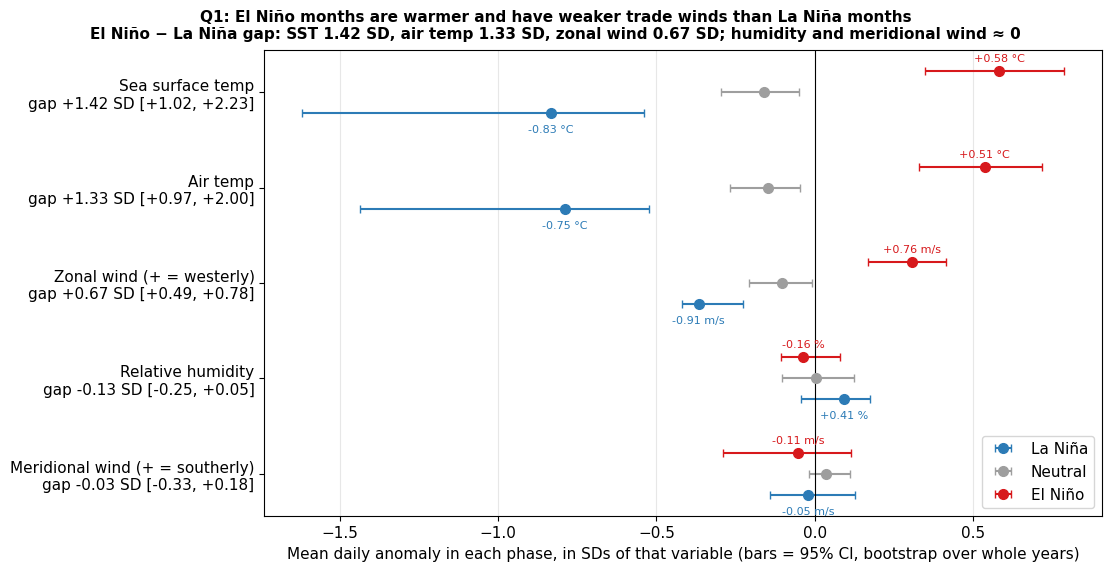

In [ ]:
# Chart 14: phase means in SD units with 95 % year-block bootstrap intervals
fig, ax = plt.subplots(figsize=(11, 5.6), layout="constrained")
order = q1.index[::-1]                                             # largest gap at the top
ypos = np.arange(len(order))
for p, dy in zip(PHASES, [-0.22, 0, 0.22]):
    x = q1.loc[order, f"{p} sd"]
    err = [x - q1.loc[order, f"{p} lo"], q1.loc[order, f"{p} hi"] - x]
    ax.errorbar(x, ypos + dy, xerr=err, fmt="o", ms=7, capsize=3, color=PHASE_COLORS[p], label=p)
    if p != "Neutral":                                             # El Niño value above its dot, La Niña value below
        for y, v in zip(ypos, order):
            ax.annotate(f"{q1.loc[v, f'{p} units']:+.2f} {Q1_UNITS[v]}", (q1.loc[v, f"{p} sd"], y + dy),
                        textcoords="offset points", xytext=(0, 7 if p == "El Niño" else -14), ha="center", fontsize=8,
                        color=PHASE_COLORS[p])
ax.axvline(0, color="black", lw=.8)
ax.set_yticks(ypos, [f"{Q1_LABELS[v]}\ngap {q1.loc[v, 'gap_sd']:+.2f} SD [{q1.loc[v, 'gap_lo']:+.2f}, {q1.loc[v, 'gap_hi']:+.2f}]"
                     for v in order])
ax.set_xlabel("Mean daily anomaly in each phase, in SDs of that variable (bars = 95% CI, bootstrap over whole years)")
ax.grid(axis="x", alpha=.3)
ax.legend(loc="lower right")
fig.suptitle("Q1: El Niño months are warmer and have weaker trade winds than La Niña months\n"
             f"El Niño − La Niña gap: SST {q1.loc['sst_anom', 'gap_sd']:.2f} SD, air temp {q1.loc['air_temp_anom', 'gap_sd']:.2f} SD, "
             f"zonal wind {q1.loc['zon_wind_anom', 'gap_sd']:.2f} SD; humidity and meridional wind ≈ 0", fontsize=11, fontweight="bold")
save(fig, "14_q1_phase_means.png")

saved charts/15_q1_equator_profile.png


SST anom (°C)                 Zonal wind anom (m/s)                
phase       La Niña Neutral El Niño               La Niña Neutral El Niño
137E           0.66   -0.02   -0.14                   NaN    0.33   -0.48
147E           0.37    0.05   -0.26                 -0.12    0.18   -0.43
156E           0.53    0.09   -0.26                 -1.79   -0.04    0.51
165E          -0.60    0.17   -0.03                 -3.22   -0.29    1.46
180           -0.94   -0.00    0.41                 -2.53   -0.78    2.55
170W          -1.41   -0.15    0.88                 -1.97   -0.65    2.34
155W          -1.52   -0.50    1.01                 -1.31   -0.65    1.43
140W          -1.85   -0.29    1.36                 -0.46   -0.49    0.95
125W          -1.59   -0.42    1.56                  0.11   -0.33    0.49
110W          -1.59   -0.45    1.57                  0.57   -0.24    0.13
95W           -1.35   -0.89    1.86                 -0.05   -0.07    0.14

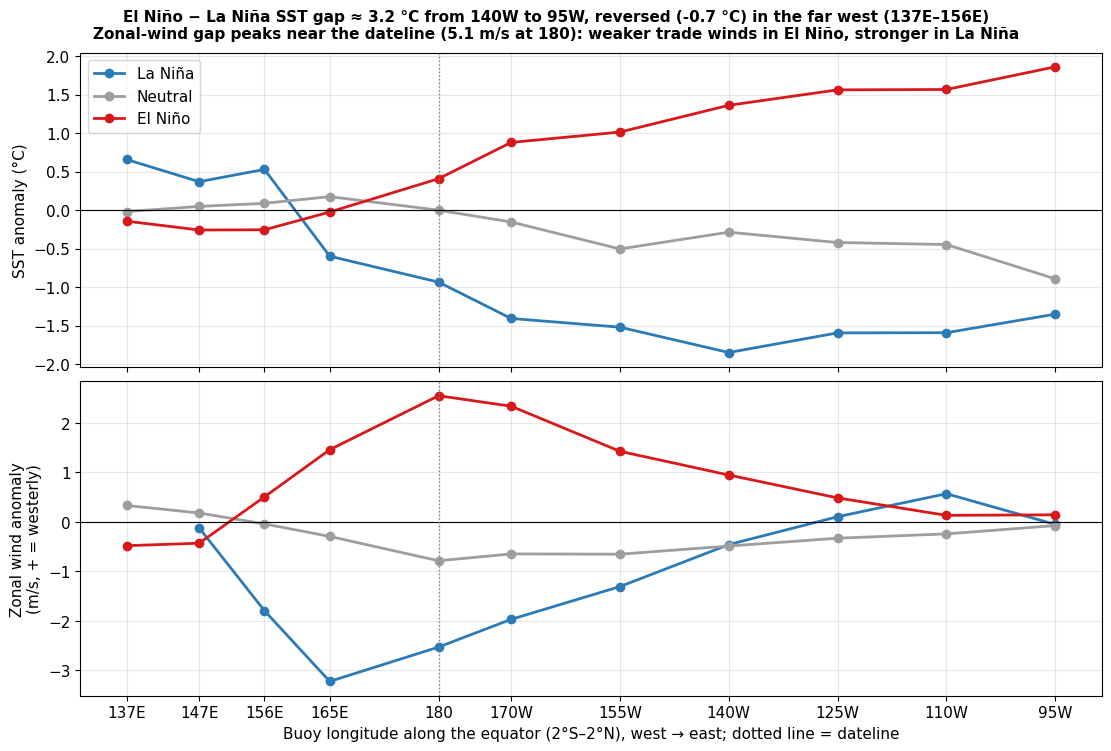

In [ ]:
# Chart 15: where along the equator the phases differ (sites within 2°S–2°N, snapped to the standard TAO longitudes)
TAO_LONS = np.array([137, 147, 156, 165, 180, 190, 205, 220, 235, 250, 265])
eqd = daily[daily["site_lat"].between(-2, 2)].copy()
eqd["lon_bin"] = TAO_LONS[np.abs(eqd["site_lon"].to_numpy()[:, None] - TAO_LONS[None, :]).argmin(axis=1)]
prof = eqd.groupby(["lon_bin", "phase"], observed=True).agg(
    sst=("sst_anom", "mean"), zw=("zon_wind_anom", "mean"), n_sst=("sst_anom", "count"), n_zw=("zon_wind_anom", "count"))
prof.loc[prof["n_sst"] < 100, "sst"] = np.nan                      # hide cells with < 100 buoy-days
prof.loc[prof["n_zw"] < 100, "zw"] = np.nan
lon_labels = [site_name(0, lon).replace("0_", "") for lon in TAO_LONS]
profile = {col: prof[col].unstack("phase").reindex(TAO_LONS)[PHASES] for col in ["sst", "zw"]}
profile_gap = {col: profile[col]["El Niño"] - profile[col]["La Niña"] for col in profile}

fig, axes = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, layout="constrained")
for ax, col, ylab in [(axes[0], "sst", "SST anomaly (°C)"), (axes[1], "zw", "Zonal wind anomaly\n(m/s, + = westerly)")]:
    for p in PHASES:
        ax.plot(TAO_LONS, profile[col][p], marker="o", lw=2, color=PHASE_COLORS[p], label=p)
    ax.axhline(0, color="black", lw=.8)
    ax.axvline(180, color="gray", ls=":", lw=1)
    ax.set_ylabel(ylab)
    ax.grid(alpha=.3)
axes[0].legend(loc="upper left")
axes[1].set_xticks(TAO_LONS, lon_labels)
axes[1].set_xlabel("Buoy longitude along the equator (2°S–2°N), west → east; dotted line = dateline")
sst_peak, zw_peak = profile_gap["sst"].idxmax(), profile_gap["zw"].idxmax()
sst_gap_east = float(profile_gap["sst"].loc[220:].mean())         # 140W-95W
sst_gap_west = float(profile_gap["sst"].loc[:156].mean())         # 137E-156E
fig.suptitle(f"El Niño − La Niña SST gap ≈ {sst_gap_east:.1f} °C from 140W to 95W, reversed ({sst_gap_west:+.1f} °C) in the far west "
             f"(137E–156E)\nZonal-wind gap peaks near the dateline ({profile_gap['zw'].max():.1f} m/s at "
             f"{site_name(0, int(zw_peak)).replace('0_', '')}): weaker trade winds in El Niño, stronger in La Niña",
             fontsize=11, fontweight="bold")
save(fig, "15_q1_equator_profile.png")
pd.concat({"SST anom (°C)": profile["sst"], "Zonal wind anom (m/s)": profile["zw"]}, axis=1).set_index(pd.Index(lon_labels)).round(2)

In [ ]:
summary["q1"] = {
    "method": "daily anomalies vs each site's calendar-month mean (1980-98); SD units = anomaly / overall SD; "
              "95% CI = percentile bootstrap over whole calendar years (B=2000, seed 212)",
    "mean_anomaly_units": {v: {p: round(float(q1.loc[v, f"{p} units"]), 3) for p in PHASES} for v in q1.index},
    "gap_elnino_minus_lanina_sd": {v: {"gap": round(float(q1.loc[v, "gap_sd"]), 2), "ci95": [round(float(q1.loc[v, "gap_lo"]), 2),
                                                                                          round(float(q1.loc[v, "gap_hi"]), 2)]}
                                   for v in q1.index},
    "equator_profile": {
        "sst_gap_max_c": round(float(profile_gap["sst"].max()), 2), "sst_gap_max_lon": site_name(0, int(sst_peak)).replace("0_", ""),
        "sst_gap_140w_95w_mean_c": round(sst_gap_east, 2), "sst_gap_137e_156e_mean_c": round(sst_gap_west, 2),
        "zonal_wind_gap_max_ms": round(float(profile_gap["zw"].max()), 2), "zonal_wind_gap_max_lon": site_name(0, int(zw_peak)).replace("0_", ""),
        "sst_by_lon": {lab: {p: (None if pd.isna(profile["sst"].loc[lon, p]) else round(float(profile["sst"].loc[lon, p]), 2)) for p in PHASES}
                       for lab, lon in zip(lon_labels, TAO_LONS)},
        "zonal_wind_by_lon": {lab: {p: (None if pd.isna(profile["zw"].loc[lon, p]) else round(float(profile["zw"].loc[lon, p]), 2)) for p in PHASES}
                              for lab, lon in zip(lon_labels, TAO_LONS)},
    },
}
summary["q1"]["gap_elnino_minus_lanina_sd"]

{'sst_anom': {'gap': 1.42, 'ci95': [1.02, 2.23]},
 'air_temp_anom': {'gap': 1.33, 'ci95': [0.97, 2.0]},
 'zon_wind_anom': {'gap': 0.67, 'ci95': [0.49, 0.78]},
 'humidity_anom': {'gap': -0.13, 'ci95': [-0.25, 0.05]},
 'mer_wind_anom': {'gap': -0.03, 'ci95': [-0.33, 0.18]}}

**Reading Q1.** El Niño and La Niña are mirror images in temperature and zonal wind, and the gaps are large next to the day-to-day spread:
about 1.3–1.4 SD for SST and air temperature and about 0.7 SD for zonal wind, with intervals far from 0. Humidity and meridional wind
barely move with the phase (both intervals include 0), so the model in section 7 leaves them out. Along the equator the SST signal sits
in the central and eastern Pacific, and the zonal-wind signal sits near the dateline.
Note: "neutral" anomalies are slightly negative because the anomaly baseline is the 1980–98 average, a period with many El Niño months.

## 7. Q2 – Which buoy readings signal the phase best, and can they call it earlier than NOAA's index?
**Real-time set-up.** ONI for month *t* is a 3-month mean (months *t−1, t, t+1*), so NOAA can publish it only at the start of month *t+2*.
Buoy data for month *t* is complete at the end of month *t*. A forecast issued at the start of month *t+1* therefore knows:
* the buoy monthly anomalies for month *t* (and *t−1*, for the 1-month change);
* the **latest official index, ONI(*t−1*)**.

**Target:** the phase NOAA will assign to month *t+k*: k = 0 ("nowcast": NOAA's answer arrives about a month later), 1, 2, 3 and 6 months ahead.

**Baseline (persistence):** "the phase stays what the latest ONI says", phase(*t+k*) = phase(*t−1*). Persistence is hard to beat
because phases last many months, but by construction it never calls a change. So besides accuracy we count **phase changes caught**:
test months whose true phase differs from the latest ONI phase, and which the model gets right.

**Leakage controls.**
1. Anomalies use a site × calendar-month climatology from the **training years only** (≤ 1994), not the all-years mean of section 3.
2. Same time split as 4.10: issue months ≤ 1994 train, ≥ 1995 test (Jan 1995 – Jun 1998).
3. Training rows whose *target* month falls in 1995 or later are dropped, so no test-period label is used for training.
4. Only months with ≥ 5 reporting buoys (from Jun 1985), as in 4.6–4.7.

**Models** (scikit-learn): multinomial logistic regression (median imputation → standardisation → `class_weight="balanced"`, C = 1, no tuning),
once with buoy features only and once adding the latest ONI; a random forest (500 trees, min 3 months per leaf) as a non-linear check.
Humidity is left out: it is 99.8 % missing before 1990, i.e. in most training years.

In [ ]:
# 7.1 Monthly buoy features against a training-only climatology
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, confusion_matrix

FEAT_VARS = ["sst", "air_temp", "zon_wind", "mer_wind"]
FEATURES = {
    "sst_n34": "SST anom, Niño 3.4 box",
    "sst_all": "SST anom, all buoys",
    "air_all": "Air temp anom, all buoys",
    "zw_all": "Zonal wind anom, all buoys",
    "zw_west": "Zonal wind anom, west Pacific (≤180°)",
    "mw_all": "Meridional wind anom, all buoys",
    "d_sst_n34": "1-month change: SST, Niño 3.4 box",
    "d_zw_west": "1-month change: zonal wind, west Pacific",
}
LATEST_ONI = {"oni_lag1": "Latest official ONI (month t−1)"}
BUOY = list(FEATURES)
CALENDAR = pd.DatetimeIndex(monthly["ym"])
oni_by_month = oni.set_index("ym")
TRAIN_END = pd.Timestamp(f"{CUT}-12-31")


def monthly_features(train_end, data=None, calendar=None, window=None):
    """Monthly array features; anomaly = value minus the site x calendar-month mean over days <= train_end only
    (only the last `window` years before train_end when given). Section 9 passes the 1980-2026 table as `data`."""
    data = daily if data is None else data
    calendar = CALENDAR if calendar is None else calendar
    base = data[data["date"] <= train_end]
    if window:
        base = base[base["date"] > train_end - pd.DateOffset(years=window)]
    clim = base.groupby(["site", "month"])[FEAT_VARS].mean()
    d = data[["ym", "site", "month", "site_lat", "site_lon", "in_nino34", *FEAT_VARS]].join(
        clim, on=["site", "month"], rsuffix="_clim")
    for v in FEAT_VARS:
        d[v] = d[v] - d[v + "_clim"]           # NaN when the site has no training data for that calendar month
    west = d["site_lat"].between(-5, 5) & (d["site_lon"] <= 180)
    f = pd.DataFrame({
        "sst_n34": d[d["in_nino34"]].groupby("ym")["sst"].mean(),
        "sst_all": d.groupby("ym")["sst"].mean(),
        "air_all": d.groupby("ym")["air_temp"].mean(),
        "zw_all": d.groupby("ym")["zon_wind"].mean(),
        "zw_west": d[west].groupby("ym")["zon_wind"].mean(),
        "mw_all": d.groupby("ym")["mer_wind"].mean(),
    }).reindex(calendar)
    f["d_sst_n34"] = f["sst_n34"].diff()        # full calendar, so diff() = change since the previous month
    f["d_zw_west"] = f["zw_west"].diff()
    f["n_sites"] = data.groupby("ym")["site"].nunique().reindex(calendar)
    return f


def build_rows(f, k):
    """One row per issue month t: buoy features at t, latest ONI (t-1) and the target phase at t+k."""
    X = f.copy()
    X["oni_lag1"] = oni_by_month["oni"].reindex(X.index.shift(-1, freq="MS")).to_numpy()
    X["phase_lag1"] = oni_by_month["phase"].reindex(X.index.shift(-1, freq="MS")).to_numpy()
    X["target"] = oni_by_month["phase"].reindex(X.index.shift(k, freq="MS")).to_numpy()
    X["target_month"] = X.index.shift(k, freq="MS")
    return X[(X["n_sites"] >= 5) & X["sst_n34"].notna()]


f_main = monthly_features(TRAIN_END)
test_days = daily[(daily["date"] > TRAIN_END) & daily["sst"].notna()]
clim_keys = daily[daily["date"] <= TRAIN_END].dropna(subset=["sst"])[["site", "month"]].drop_duplicates()
no_clim = 1 - test_days.merge(clim_keys, on=["site", "month"], how="inner").shape[0] / len(test_days)
print(f"test-period SST buoy-days without a training climatology (dropped from the averages): {no_clim:.1%}")
print("missing share of each feature over months with >= 5 buoys:")
print(f_main.loc[f_main["n_sites"] >= 5, BUOY].isna().mean().round(3).to_dict())
f_main.loc[f_main["n_sites"] >= 5, BUOY].describe().round(2)

test-period SST buoy-days without a training climatology (dropped from the averages): 6.5%
missing share of each feature over months with >= 5 buoys:
{'sst_n34': 0.013, 'sst_all': 0.0, 'air_all': 0.0, 'zw_all': 0.0, 'zw_west': 0.045, 'mw_all': 0.0, 'd_sst_n34': 0.019, 'd_zw_west': 0.051}


,sst_n34,sst_all,air_all,zw_all,zw_west,mw_all,d_sst_n34,d_zw_west
count,155.00,157.00,157.00,157.00,150.00,157.00,154.00,149.00
mean,-0.06,-0.04,-0.02,-0.08,-0.36,-0.01,-0.00,-0.01
std,1.00,0.64,0.55,0.83,1.75,0.53,0.36,1.24
min,-3.03,-2.40,-2.02,-1.66,-5.30,-2.44,-1.98,-4.02
25%,-0.60,-0.40,-0.30,-0.61,-1.57,-0.21,-0.19,-0.68
50%,-0.10,0.03,-0.00,-0.09,-0.07,0.01,-0.01,0.04
75%,0.48,0.31,0.33,0.40,0.78,0.28,0.23,0.67
max,2.00,1.32,1.12,2.18,3.63,1.10,0.86,4.52


In [ ]:
# 7.2 Fit on train (issue months <= 1994), score on test (issue months 1995 - Jun 1998)
HORIZONS = [0, 1, 2, 3, 6]
PERSIST = "Persistence (latest ONI)"


def logit():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))


def forest():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced",
                                                random_state=212, n_jobs=-1))


MODELS = {"Logistic, buoys only": (logit, BUOY),
          "Logistic, buoys + latest ONI": (logit, BUOY + ["oni_lag1"]),
          "Random forest, buoys + latest ONI": (forest, BUOY + ["oni_lag1"])}
MODEL_COLORS = {PERSIST: "#9e9e9e", "Logistic, buoys only": "#ff7f0e", "Logistic, buoys + latest ONI": "#1f77b4",
                "Random forest, buoys + latest ONI": "#2ca02c"}


def scores(y, pred, prev):
    """Accuracy metrics plus 'phase changes caught' (true phase differs from the latest ONI phase, and the call is right)."""
    y, pred, prev = (np.asarray(a, dtype=object) for a in (y, pred, prev))
    change = y != prev
    rec = recall_score(y, pred, labels=PHASES, average=None, zero_division=0)
    return {"months": len(y), "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, labels=PHASES, average="macro", zero_division=0),
            **{f"recall {p}": r for p, r in zip(PHASES, rec)},
            "phase_changes": int(change.sum()), "changes_caught": int((pred[change] == y[change]).sum())}


def split_rows(data, train_end, test_year=None):
    train = data[(data.index <= train_end) & (data["target_month"] <= train_end)]   # purge: target must be a training month
    test = data[data.index.year == test_year] if test_year else data[data.index > train_end]
    return train, test


results, test_preds, fitted = [], {}, {}
for k in HORIZONS:
    train, test = split_rows(build_rows(f_main, k), TRAIN_END)
    test_preds[(k, "truth")] = test["target"]
    test_preds[(k, PERSIST)] = test["phase_lag1"]
    results.append({"k": k, "model": PERSIST, "train_months": len(train), **scores(test["target"], test["phase_lag1"], test["phase_lag1"])})
    for name, (make, cols) in MODELS.items():
        fitted[(k, name)] = model = make().fit(train[cols], train["target"])
        test_preds[(k, name)] = pd.Series(model.predict(test[cols]), index=test.index)
        results.append({"k": k, "model": name, "train_months": len(train), **scores(test["target"], test_preds[(k, name)], test["phase_lag1"])})
results = pd.DataFrame(results)
print("training months per horizon:", results.groupby("k")["train_months"].first().to_dict(),
      "| test months:", results.groupby("k")["months"].first().to_dict())
results.assign(changes=results["changes_caught"].astype(str) + "/" + results["phase_changes"].astype(str)).pivot(
    index="model", columns="k", values=["balanced_accuracy", "changes"]).reindex([PERSIST, *MODELS]).round(2)

training months per horizon: {0: 113, 1: 112, 2: 111, 3: 110, 6: 107} | test months: {0: 42, 1: 42, 2: 42, 3: 42, 6: 42}


balanced_accuracy                      \
k                                                 0         1         2   
model                                                                     
Persistence (latest ONI)                   0.884524  0.737607  0.616667   
Logistic, buoys only                            0.8  0.676211  0.733333   
Logistic, buoys + latest ONI                    0.9  0.692877      0.75   
Random forest, buoys + latest ONI          0.817857  0.681766  0.611111   

                                                      changes              \
k                                         3         6       0     1     2   
model                                                                       
Persistence (latest ONI)           0.518873  0.287698     0/5  0/11  0/16   
Logistic, buoys only               0.763291   0.66369     3/5  4/11  9/16   
Logistic, buoys + latest ONI       0.793594  0.619048     3/5  5/11  9/16   
Random forest, buoys + latest ONI  0.576023  0.626984     1/5  5/11  7/16   

                                                 
k                                      3      6  
model                                            
Persistence (latest ONI)            0/20   0/30  
Logistic, buoys only               14/20  18/30  
Logistic, buoys + latest ONI       15/20  16/30  
Random forest, buoys + latest ONI   9/20  16/30

saved charts/16_q2_skill_by_horizon.png


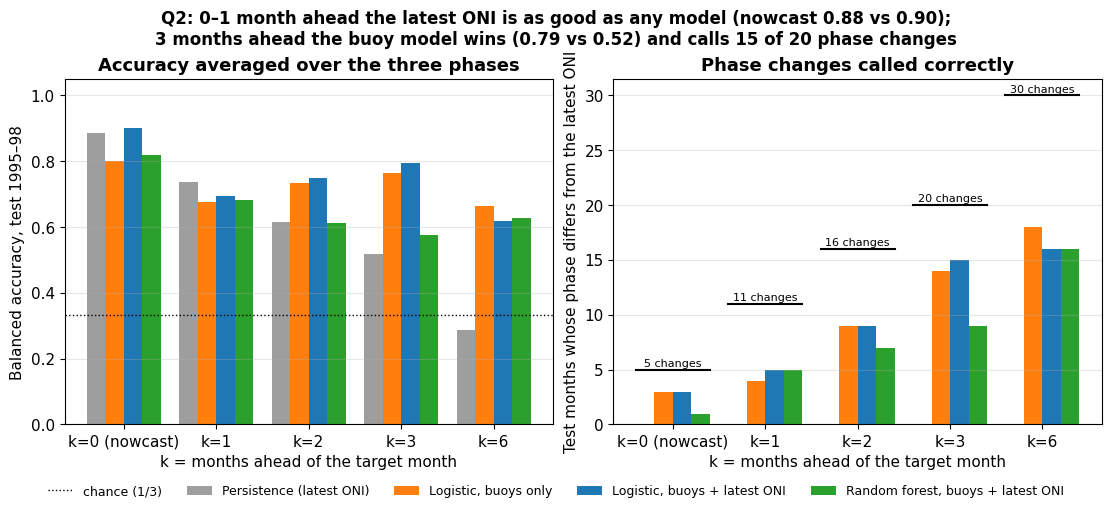

In [ ]:
# Chart 16: skill by horizon, and phase changes caught
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
names = [PERSIST, *MODELS]
width = 0.2
for i, name in enumerate(names):
    r = results[results["model"] == name].set_index("k").reindex(HORIZONS)
    x = np.arange(len(HORIZONS)) + (i - 1.5) * width
    axes[0].bar(x, r["balanced_accuracy"], width, color=MODEL_COLORS[name], label=name)
    axes[1].bar(x, r["changes_caught"], width, color=MODEL_COLORS[name])
total_changes = results[results["model"] == PERSIST].set_index("k").reindex(HORIZONS)["phase_changes"]
for j, n in enumerate(total_changes):
    axes[1].plot([j - 2 * width, j + 2 * width], [n, n], color="black", lw=1.5)
    axes[1].text(j, n + 0.3, f"{n} changes", ha="center", fontsize=8)
axes[0].axhline(1 / 3, ls=":", color="black", lw=1, label="chance (1/3)")
xt = [f"k={k}" + (" (nowcast)" if k == 0 else "") for k in HORIZONS]
for ax in axes:
    ax.set_xticks(range(len(HORIZONS)), xt)
    ax.set_xlabel("k = months ahead of the target month")
    ax.grid(axis="y", alpha=.3)
axes[0].set(ylabel="Balanced accuracy, test 1995–98", ylim=(0, 1.05), title="Accuracy averaged over the three phases")
axes[1].set(ylabel="Test months whose phase differs from the latest ONI", title="Phase changes called correctly")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, fontsize=9, frameon=False)
r0 = results.set_index(["k", "model"])
best = "Logistic, buoys + latest ONI"
fig.suptitle(f"Q2: 0–1 month ahead the latest ONI is as good as any model (nowcast {r0.loc[(0, PERSIST), 'balanced_accuracy']:.2f} vs "
             f"{r0.loc[(0, best), 'balanced_accuracy']:.2f});\n3 months ahead the buoy model wins "
             f"({r0.loc[(3, best), 'balanced_accuracy']:.2f} vs {r0.loc[(3, PERSIST), 'balanced_accuracy']:.2f}) and calls "
             f"{r0.loc[(3, best), 'changes_caught']} of {r0.loc[(3, PERSIST), 'phase_changes']} phase changes",
             fontsize=12, fontweight="bold")
save(fig, "16_q2_skill_by_horizon.png")

saved charts/17_q2_test_timeline.png


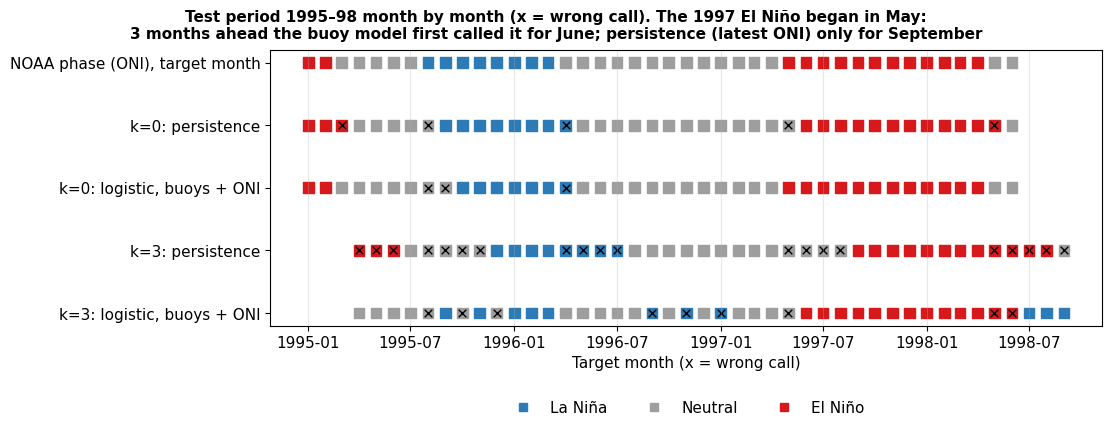

In [ ]:
# Chart 17: the test period month by month: NOAA's phase vs the latest ONI (persistence) vs the model, nowcast and 3 months ahead
phase_code = {"La Niña": 0, "Neutral": 1, "El Niño": 2}
from matplotlib.colors import ListedColormap
cmap = ListedColormap([PHASE_COLORS[p] for p in PHASES])
lines = [("NOAA phase (ONI), target month", test_preds[(0, "truth")], None, 0)]
for k in [0, 3]:
    truth_k = test_preds[(k, "truth")]
    for name in [PERSIST, best]:
        label = f"k={k}: {'persistence' if name == PERSIST else 'logistic, buoys + ONI'}"
        lines.append((label, test_preds[(k, name)], truth_k, k))
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
for row, (label, pred, truth_k, shift) in enumerate(lines):
    tm = pred.index.shift(shift, freq="MS")                       # plot at the TARGET month
    ax.scatter(tm, np.full(len(tm), row), c=[phase_code[v] for v in pred], cmap=cmap, vmin=0, vmax=2, marker="s", s=60)
    if truth_k is not None:
        wrong = np.asarray(pred) != np.asarray(truth_k)
        ax.scatter(tm[wrong], np.full(wrong.sum(), row), marker="x", color="black", s=30, lw=1)
ax.set_yticks(range(len(lines)), [l[0] for l in lines])
ax.invert_yaxis()
ax.grid(axis="x", alpha=.3)
ax.set_xlabel("Target month (x = wrong call)")
handles = [plt.Line2D([], [], marker="s", ls="", color=PHASE_COLORS[p], label=p) for p in PHASES]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
k3 = pd.DataFrame({"truth": test_preds[(3, "truth")], "model": test_preds[(3, best)], "persist": test_preds[(3, PERSIST)]})
k3.index = k3.index.shift(3, freq="MS")                           # index = target month
in97 = k3[k3.index.year == 1997]
onset_1997 = in97.index[in97["truth"] == "El Niño"].min()
model_1997 = in97.index[in97["model"] == "El Niño"].min()
persist_1997 = in97.index[in97["persist"] == "El Niño"].min()
fig.suptitle(f"Test period 1995–98 month by month (x = wrong call). The 1997 El Niño began in {onset_1997:%B}:\n"
             f"3 months ahead the buoy model first called it for {model_1997:%B}; persistence (latest ONI) only for {persist_1997:%B}",
             fontsize=11, fontweight="bold")
save(fig, "17_q2_test_timeline.png")

In [ ]:
# 7.3 Robustness: walk-forward check. Each year 1990-1998 is a test year; the models (and the anomaly climatology) are
# re-built from all earlier months only. This gives ~100 test months and twice as many phase changes as the single split.
WF_YEARS = range(1990, 1999)
wf_features = {yr: monthly_features(pd.Timestamp(f"{yr - 1}-12-31")) for yr in WF_YEARS}


def walk_forward(k, models):
    """Out-of-sample predictions for test years 1990-1998, each year predicted by models fitted on all earlier months."""
    parts = []
    for yr in WF_YEARS:
        end = pd.Timestamp(f"{yr - 1}-12-31")
        train, test = split_rows(build_rows(wf_features[yr], k), end, test_year=yr)
        out = test[["target", "phase_lag1"]].copy()
        for name, (make, cols) in models.items():
            out[name] = make().fit(train[cols], train["target"]).predict(test[cols])
        parts.append(out)
    return pd.concat(parts)


wf = []
for k in [0, 1, 3]:
    allp = walk_forward(k, MODELS)
    wf.append({"k": k, "model": PERSIST, **scores(allp["target"], allp["phase_lag1"], allp["phase_lag1"])})
    wf += [{"k": k, "model": name, **scores(allp["target"], allp[name], allp["phase_lag1"])} for name in MODELS]
wf = pd.DataFrame(wf)
wf.assign(changes=wf["changes_caught"].astype(str) + "/" + wf["phase_changes"].astype(str)).pivot(
    index="model", columns="k", values=["balanced_accuracy", "changes"]).reindex([PERSIST, *MODELS]).round(2)

balanced_accuracy                      \
k                                                 0         1         3   
model                                                                     
Persistence (latest ONI)                    0.89134   0.75396  0.525753   
Logistic, buoys only                        0.75817  0.692497  0.606373   
Logistic, buoys + latest ONI               0.802614  0.769562  0.592613   
Random forest, buoys + latest ONI           0.81634  0.665596  0.408669   

                                  changes                
k                                       0      1      3  
model                                                    
Persistence (latest ONI)             0/10   0/21   0/41  
Logistic, buoys only                 5/10  11/21  19/41  
Logistic, buoys + latest ONI         5/10  12/21  18/41  
Random forest, buoys + latest ONI    4/10   8/21  16/41

saved charts/18_q2_single_feature.png


,split k=0,walk-forward k=0,split k=3,walk-forward k=3
"Zonal wind anom, west Pacific (≤180°)",0.55,0.62,0.66,0.66
"Zonal wind anom, all buoys",0.67,0.68,0.58,0.56
"SST anom, Niño 3.4 box",0.80,0.77,0.48,0.51
"SST anom, all buoys",0.73,0.62,0.59,0.50
"1-month change: SST, Niño 3.4 box",0.24,0.16,0.55,0.50
"Air temp anom, all buoys",0.71,0.75,0.53,0.48
"Meridional wind anom, all buoys",0.31,0.35,0.52,0.47
Latest official ONI (month t−1),0.86,0.84,0.48,0.47
"1-month change: zonal wind, west Pacific",0.24,0.35,0.29,0.29


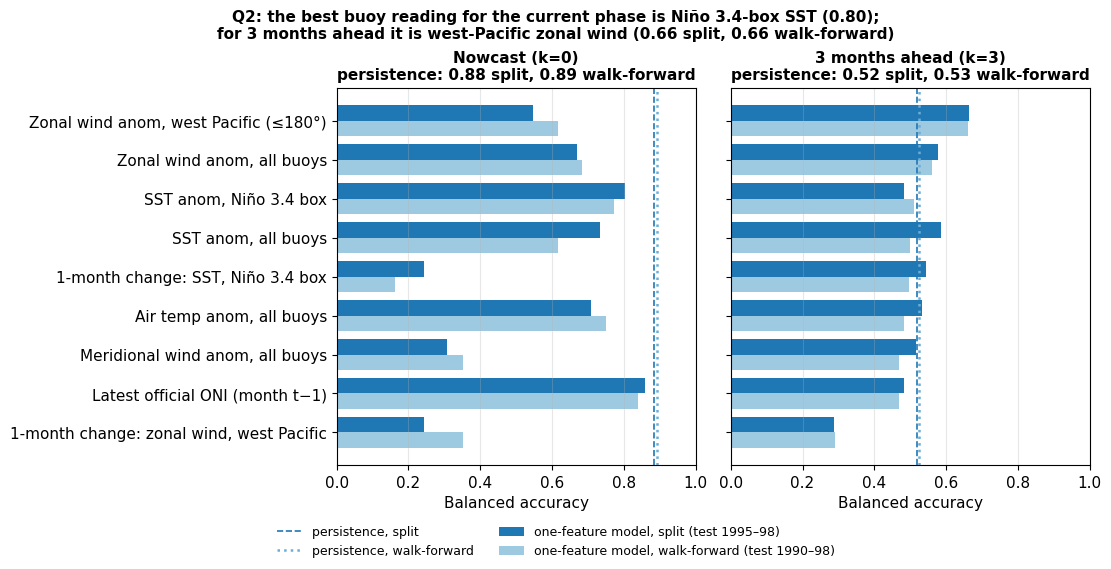

In [ ]:
# 7.4 Which single reading signals the phase best? One-feature logistic models, in both checks
SINGLE = {lab: (logit, [col]) for col, lab in {**FEATURES, **LATEST_ONI}.items()}
single = {}
for k in [0, 3]:
    train, test = split_rows(build_rows(f_main, k), TRAIN_END)
    wfp = walk_forward(k, SINGLE)
    for lab, (make, cols) in SINGLE.items():
        m = make().fit(train[cols], train["target"])
        single.setdefault(lab, {})[f"split k={k}"] = balanced_accuracy_score(test["target"], m.predict(test[cols]))
        single[lab][f"walk-forward k={k}"] = balanced_accuracy_score(wfp["target"], wfp[lab])
single = pd.DataFrame(single).T.sort_values("walk-forward k=3", ascending=False)
persist_split = results[results["model"] == PERSIST].set_index("k")["balanced_accuracy"]
persist_wf = wf[wf["model"] == PERSIST].set_index("k")["balanced_accuracy"]
buoy_only = single.drop(index=list(LATEST_ONI.values()))
best_now, best_k3 = buoy_only["split k=0"].idxmax(), buoy_only["walk-forward k=3"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True, layout="constrained")
y = np.arange(len(single))
for ax, k, title in [(axes[0], 0, "Nowcast (k=0)"), (axes[1], 3, "3 months ahead (k=3)")]:
    ax.barh(y - 0.2, single[f"split k={k}"], 0.4, color="#1f77b4", label="one-feature model, split (test 1995–98)")
    ax.barh(y + 0.2, single[f"walk-forward k={k}"], 0.4, color="#9ecae1", label="one-feature model, walk-forward (test 1990–98)")
    ax.axvline(persist_split[k], color="#1f77b4", ls="--", lw=1.2, label="persistence, split")
    ax.axvline(persist_wf[k], color="#6baed6", ls=":", lw=1.8, label="persistence, walk-forward")
    ax.set(xlim=(0, 1), xlabel="Balanced accuracy")
    ax.set_title(f"{title}\npersistence: {persist_split[k]:.2f} split, {persist_wf[k]:.2f} walk-forward", fontsize=11)
    ax.grid(axis="x", alpha=.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, fontsize=9, frameon=False)
axes[0].set_yticks(y, single.index)
axes[0].invert_yaxis()
SHORT = dict(zip(FEATURES.values(), ["Niño 3.4-box SST", "all-buoy SST", "air temperature", "all-buoy zonal wind",
                                     "west-Pacific zonal wind", "meridional wind", "1-month SST change", "1-month west-wind change"]))
fig.suptitle(f"Q2: the best buoy reading for the current phase is {SHORT[best_now]} ({single.loc[best_now, 'split k=0']:.2f});\n"
             f"for 3 months ahead it is {SHORT[best_k3]} ({single.loc[best_k3, 'split k=3']:.2f} split, "
             f"{single.loc[best_k3, 'walk-forward k=3']:.2f} walk-forward)", fontsize=11, fontweight="bold")
save(fig, "18_q2_single_feature.png")
single.round(2)

In [ ]:
def metrics_block(df):
    return {f"k{k}": {m: {"balanced_accuracy": round(float(r["balanced_accuracy"]), 2), "accuracy": round(float(r["accuracy"]), 2),
                          "macro_f1": round(float(r["macro_f1"]), 2), "changes_caught": int(r["changes_caught"]),
                          "phase_changes": int(r["phase_changes"]), "months": int(r["months"]),
                          "recall": {p: round(float(r[f"recall {p}"]), 2) for p in PHASES}}
                  for m, r in df[df["k"] == k].set_index("model").iterrows()}
            for k in sorted(df["k"].unique())}


summary["q2"] = {
    "setup": "forecast issued at start of month t+1 with buoy anomalies for month t and the latest ONI (t-1); target = ONI phase "
             "of month t+k; anomalies vs training-only climatology; train issue months <= 1994 (target also <= 1994), test 1995-1998-06; "
             "months with >= 5 buoys",
    "features": FEATURES, "train_months_by_k": results.groupby("k")["train_months"].first().astype(int).to_dict(),
    "test_buoy_days_without_training_climatology_pct": round(float(no_clim * 100), 1),
    "main_split": metrics_block(results),
    "single_feature_balanced_accuracy": {f: {c: round(float(v), 2) for c, v in r.items()} for f, r in single.iterrows()},
    "best_single_reading": {"nowcast": best_now, "three_months_ahead": best_k3},
    "call_1997_el_nino_k3": {"onset": f"{onset_1997:%Y-%m}", "model_first_call": f"{model_1997:%Y-%m}",
                             "persistence_first_call": f"{persist_1997:%Y-%m}"},
    "walk_forward_1990_1998": metrics_block(wf),
}
{k: {m: (v["balanced_accuracy"], f"{v['changes_caught']}/{v['phase_changes']}") for m, v in d.items()} for k, d in summary["q2"]["main_split"].items()}

{'k0': {'Persistence (latest ONI)': (0.88, '0/5'),
  'Logistic, buoys only': (0.8, '3/5'),
  'Logistic, buoys + latest ONI': (0.9, '3/5'),
  'Random forest, buoys + latest ONI': (0.82, '1/5')},
 'k1': {'Persistence (latest ONI)': (0.74, '0/11'),
  'Logistic, buoys only': (0.68, '4/11'),
  'Logistic, buoys + latest ONI': (0.69, '5/11'),
  'Random forest, buoys + latest ONI': (0.68, '5/11')},
 'k2': {'Persistence (latest ONI)': (0.62, '0/16'),
  'Logistic, buoys only': (0.73, '9/16'),
  'Logistic, buoys + latest ONI': (0.75, '9/16'),
  'Random forest, buoys + latest ONI': (0.61, '7/16')},
 'k3': {'Persistence (latest ONI)': (0.52, '0/20'),
  'Logistic, buoys only': (0.76, '14/20'),
  'Logistic, buoys + latest ONI': (0.79, '15/20'),
  'Random forest, buoys + latest ONI': (0.58, '9/20')},
 'k6': {'Persistence (latest ONI)': (0.29, '0/30'),
  'Logistic, buoys only': (0.66, '18/30'),
  'Logistic, buoys + latest ONI': (0.62, '16/30'),
  'Random forest, buoys + latest ONI': (0.63, '16/30')}}

**Reading Q2.**
* *This month and next* (k = 0–1): the latest official ONI is very hard to beat and no model clearly does. The buoys' edge here is
  timing: a month's buoy data are ready about a month before NOAA can publish that month's ONI.
* *Three or more months ahead* (k ≥ 2): the logistic model on buoy readings beats persistence in the 1995–98 test and calls most phase
  changes, including the 1997 El Niño onset and the 1998 swing to La Niña. The walk-forward check over 1990–98 shows a smaller gain,
  so the size of the edge is uncertain.
* *Which reading*: Niño 3.4-box SST tells you the current phase (it is almost the index itself). West-Pacific zonal wind is the best
  early signal in both checks, in line with the lead/lag result in 4.7, where zonal wind peaks one month ahead of ONI.
* The random forest does not beat the logistic model: about 110 training months are too few for a flexible model.
* Caveat: the split's test set has 42 months and a handful of phase changes; one or two months more or less correct move balanced
  accuracy by about 0.05.

## 8. Q3 – After a fall El Niño, how much more likely is a wet, stormy LA winter? And what does it mean for 2026–27?
This builds on section 5 (76 seasons, 1950–2025; *wet* = season total above the 1950–2025 median of all seasons;
*heavy-rain day* = ≥ 1 inch). New here:
* **8.1 Odds with uncertainty**: share of wet winters per fall phase with a 95 % Wilson interval (suited to small counts),
  Fisher's exact test (El Niño fall vs all other falls) and a permutation test for the difference in heavy-rain days.
* **8.2 Strong El Niño** (Aug–Oct index ≥ 1.5) on its own, under both indices: the traditional **ONI** and NOAA's
  **Relative ONI (RONI)**, the official index since Feb 2026 (Niño 3.4 anomaly minus the tropical-mean anomaly, rescaled).
  The two disagree on which falls were "strong", so both lists are shown.
* **8.3 Winter 2026–27**: where this fall ranks under each index, and how the season is going so far.

In [ ]:
# 8.1 Odds of a wet winter with 95 % Wilson intervals, plus significance tests
from scipy.stats import fisher_exact


def wilson(k, n, z=1.96):
    """95 % Wilson score interval for k successes out of n."""
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


def odds_table(phase_col):
    """Seasons, wet count/share (+ Wilson CI), mean heavy days and median inches per fall group."""
    g = seasons.groupby(phase_col).agg(n=("season", "size"), wet=("wet", "sum"), heavy_mean=("heavy", "mean"),
                                       median_in=("inches", "median"))
    g["wet_share"] = g["wet"] / g["n"]
    g["ci_low"], g["ci_high"] = zip(*[wilson(w, n) for w, n in zip(g["wet"], g["n"])])
    return g


odds_oni = odds_table("phase").reindex(LA_PHASES)
en = seasons["phase"] == "El Niño"
wet_en, n_en = int(seasons.loc[en, "wet"].sum()), int(en.sum())
wet_ot, n_ot = int(seasons.loc[~en, "wet"].sum()), int((~en).sum())
odds_ratio, p_fisher = fisher_exact([[wet_en, n_en - wet_en], [wet_ot, n_ot - wet_ot]], alternative="greater")
risk_ratio = (wet_en / n_en) / (wet_ot / n_ot)

rng = np.random.default_rng(212)
heavy_arr, inch_arr = seasons["heavy"].to_numpy(), seasons["inches"].to_numpy()
obs_heavy = heavy_arr[en].mean() - heavy_arr[~en].mean()
obs_inch = inch_arr[en].mean() - inch_arr[~en].mean()
perm_heavy, perm_inch = [], []
for _ in range(10000):
    lab = rng.permutation(en.to_numpy())
    perm_heavy.append(heavy_arr[lab].mean() - heavy_arr[~lab].mean())
    perm_inch.append(inch_arr[lab].mean() - inch_arr[~lab].mean())
p_heavy = (np.sum(np.array(perm_heavy) >= obs_heavy) + 1) / (len(perm_heavy) + 1)
p_inch = (np.sum(np.array(perm_inch) >= obs_inch) + 1) / (len(perm_inch) + 1)
print(f"El Niño fall: {wet_en}/{n_en} wet ({wet_en / n_en:.0%}) vs other falls {wet_ot}/{n_ot} ({wet_ot / n_ot:.0%}); "
      f"risk ratio {risk_ratio:.2f}; Fisher one-sided p = {p_fisher:.3f}")
print(f"heavy days/season: {heavy_arr[en].mean():.2f} vs {heavy_arr[~en].mean():.2f} (+{obs_heavy:.2f}); permutation p = {p_heavy:.4f}")
print(f"mean season total: {inch_arr[en].mean():.2f} vs {inch_arr[~en].mean():.2f} in (+{obs_inch:.2f}); permutation p = {p_inch:.4f}")
odds_oni.round(2)

El Niño fall: 13/20 wet (65%) vs other falls 25/56 (45%); risk ratio 1.46; Fisher one-sided p = 0.096
heavy days/season: 5.70 vs 3.75 (+1.95); permutation p = 0.0145
mean season total: 17.98 vs 13.20 in (+4.78); permutation p = 0.0103


,n,wet,heavy_mean,median_in,wet_share,ci_low,ci_high
phase,,,,,,,
El Niño,20,13,5.70,17.67,0.65,0.43,0.82
Neutral,38,17,4.05,11.09,0.45,0.30,0.60
La Niña,18,8,3.11,12.14,0.44,0.25,0.66


In [ ]:
# 8.2 Strong El Niño, ONI vs RONI. RONI comes from the same CPC folder and has the same SEAS / YR layout.
RONI_URL = "https://www.cpc.ncep.noaa.gov/data/indices/RONI.ascii.txt"
if not os.path.exists(RAW / "RONI.ascii.txt"):
    print("downloading", RONI_URL)
    urllib.request.urlretrieve(RONI_URL, RAW / "RONI.ascii.txt")
roni = pd.read_csv(RAW / "RONI.ascii.txt", sep=r"\s+")
roni_aso = roni.loc[roni["SEAS"] == "ASO", ["YR", "ANOM"]].rename(columns={"YR": "season", "ANOM": "aso_roni"})
seasons = seasons.drop(columns=["aso_roni"], errors="ignore").merge(roni_aso, on="season", how="left", validate="one_to_one")
assert seasons["aso_roni"].notna().all()

STRENGTHS = ["La Niña", "Neutral", "Moderate El Niño (0.5–1.49)", "Strong El Niño (≥ 1.5)"]
for idx in ["oni", "roni"]:
    x = seasons[f"aso_{idx}"]
    seasons[f"phase_{idx}"] = np.select([x >= 0.5, x <= -0.5], ["El Niño", "La Niña"], default="Neutral")
    seasons[f"strength_{idx}"] = np.select([x >= 1.5, x >= 0.5, x <= -0.5], [STRENGTHS[3], STRENGTHS[2], STRENGTHS[0]], default="Neutral")
odds_by_index = pd.concat({"ONI": odds_table("strength_oni").reindex(STRENGTHS),
                           "RONI": odds_table("strength_roni").reindex(STRENGTHS)})
odds_roni_3 = odds_table("phase_roni").reindex(LA_PHASES)

strong = seasons[(seasons["aso_oni"] >= 1.5) | (seasons["aso_roni"] >= 1.5)].sort_values("season")
strong_tbl = strong[["season", "aso_oni", "aso_roni", "inches", "heavy", "wet"]].assign(
    winter=lambda t: t["season"].astype(str) + "–" + (t["season"] + 1).astype(str).str[-2:],
    strong_by=lambda t: np.select([(t["aso_oni"] >= 1.5) & (t["aso_roni"] >= 1.5), t["aso_oni"] >= 1.5], ["both", "ONI only"], "RONI only"))
print("RONI-labelled 3-phase table (robustness):")
print(odds_roni_3.round(2).to_string())
print()
print(strong_tbl.round(2).to_string(index=False))
odds_by_index.round(2)

downloading https://www.cpc.ncep.noaa.gov/data/indices/RONI.ascii.txt
RONI-labelled 3-phase table (robustness):
             n  wet  heavy_mean  median_in  wet_share  ci_low  ci_high
phase_roni                                                            
El Niño     21   14        6.10      20.44       0.67    0.45     0.83
Neutral     34   14        3.65      10.13       0.41    0.26     0.58
La Niña     21   10        3.43      12.32       0.48    0.28     0.68

 season  aso_oni  aso_roni  inches  heavy   wet  winter strong_by
   1965     1.55      1.76   20.44      6  True 1965–66      both
   1972     1.49      1.64   21.27      7  True 1972–73 RONI only
   1982     1.45      1.64   31.27     13  True 1982–83 RONI only
   1997     2.04      2.07   31.03     11  True 1997–98      both
   2015     2.02      1.80    9.67      2 False 2015–16      both
   2023     1.50      1.04   25.19      8  True 2023–24  ONI only


n  wet  heavy_mean  median_in  wet_share  \
     strength_oni                                                             
ONI  La Niña                      18    8        3.11      12.14       0.44   
     Neutral                      38   17        4.05      11.09       0.45   
     Moderate El Niño (0.5–1.49)  16   10        5.44      16.44       0.62   
     Strong El Niño (≥ 1.5)        4    3        6.75      22.82       0.75   
RONI La Niña                      21   10        3.43      12.32       0.48   
     Neutral                      34   14        3.65      10.13       0.41   
     Moderate El Niño (0.5–1.49)  16   10        5.56      16.44       0.62   
     Strong El Niño (≥ 1.5)        5    4        7.80      21.27       0.80   

                                  ci_low  ci_high  
     strength_oni                                  
ONI  La Niña                        0.25     0.66  
     Neutral                        0.30     0.60  
     Moderate El Niño (0.5–1.49)    0.39     0.82  
     Strong El Niño (≥ 1.5)         0.30     0.95  
RONI La Niña                        0.28     0.68  
     Neutral                        0.26     0.58  
     Moderate El Niño (0.5–1.49)    0.39     0.82  
     Strong El Niño (≥ 1.5)         0.38     0.96

saved charts/19_q3_wet_odds_oni_roni.png


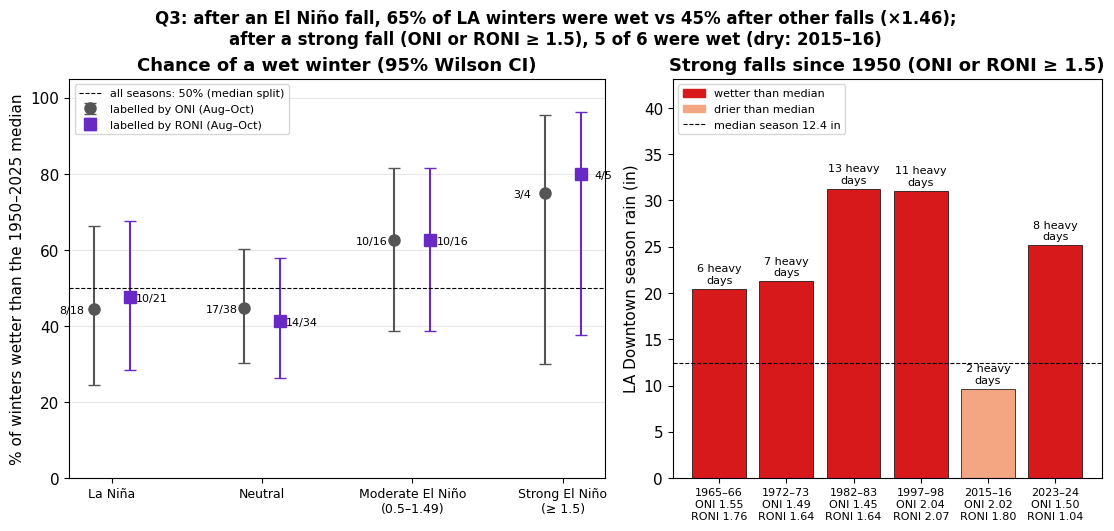

In [ ]:
# Chart 19: odds of a wet winter by fall strength, ONI vs RONI (95 % Wilson intervals)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for j, (idx, mk, dx) in enumerate([("ONI", "o", -0.12), ("RONI", "s", 0.12)]):
    t = odds_by_index.loc[idx]
    xs = np.arange(len(STRENGTHS)) + dx
    ax.errorbar(xs, t["wet_share"] * 100, yerr=[(t["wet_share"] - t["ci_low"]) * 100, (t["ci_high"] - t["wet_share"]) * 100],
                fmt=mk, ms=8, capsize=4, color=["#555555", "#6929c4"][j], label=f"labelled by {idx} (Aug–Oct)")
    for x_, (_, r) in zip(xs, t.iterrows()):
        ax.annotate(f"{int(r['wet'])}/{int(r['n'])}", (x_, r["wet_share"] * 100), textcoords="offset points",
                    xytext=(-16 if j == 0 else 16, -3), ha="center", fontsize=8)
ax.axhline(50, ls="--", color="black", lw=.8, label="all seasons: 50% (median split)")
ax.set_xticks(range(len(STRENGTHS)), [s.replace(" (", "\n(") for s in STRENGTHS], fontsize=9)
ax.set(ylim=(0, 105), ylabel="% of winters wetter than the 1950–2025 median", title="Chance of a wet winter (95% Wilson CI)")
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="y", alpha=.3)
ax = axes[1]
for i, (_, r) in enumerate(strong_tbl.iterrows()):
    ax.bar(i, r["inches"], color=PHASE_COLORS["El Niño"] if r["wet"] else "#f4a582", edgecolor="black", lw=.5)
    ax.text(i, r["inches"] + 0.6, f"{r['heavy']} heavy\ndays", ha="center", fontsize=8)
ax.axhline(la_median, ls="--", color="black", lw=.8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PHASE_COLORS["El Niño"], label="wetter than median"),
                   plt.Rectangle((0, 0), 1, 1, color="#f4a582", label="drier than median"),
                   plt.Line2D([], [], ls="--", color="black", lw=.8, label=f"median season {la_median:.1f} in")],
          loc="upper left", fontsize=8)
ax.set_xticks(range(len(strong_tbl)), [f"{w}\nONI {o:.2f}\nRONI {r_:.2f}" for w, o, r_ in
                                      zip(strong_tbl["winter"], strong_tbl["aso_oni"], strong_tbl["aso_roni"])], fontsize=8)
ax.set(ylabel="LA Downtown season rain (in)", ylim=(0, strong_tbl["inches"].max() * 1.38),
       title="Strong falls since 1950 (ONI or RONI ≥ 1.5)")
dry_strong = strong_tbl.loc[~strong_tbl["wet"], "winter"].tolist()
fig.suptitle(f"Q3: after an El Niño fall, {wet_en / n_en:.0%} of LA winters were wet vs {wet_ot / n_ot:.0%} after other falls "
             f"(×{risk_ratio:.2f});\nafter a strong fall (ONI or RONI ≥ 1.5), {int(strong_tbl['wet'].sum())} of {len(strong_tbl)} were wet "
             f"(dry: {', '.join(dry_strong) or 'none'})", fontsize=12, fontweight="bold")
save(fig, "19_q3_wet_odds_oni_roni.png")

In [ ]:
# 8.3 Winter 2026-27: rank of this fall and season-to-date rain vs the same date in past seasons
la["day_of_season"] = (la["DATE"] - pd.to_datetime(la["season"].astype(str) + "-07-01")).dt.days
last_obs = la.loc[la["mm"].notna(), "DATE"].max()
day_cut = int((last_obs - pd.Timestamp("2026-07-01")).days)
to_date = la[la["day_of_season"] <= day_cut].groupby("season")["mm"].sum() / 25.4
hist_to_date = to_date.loc[1950:2025]
now_in = float(to_date.loc[2026])
valid_2026 = int(la.loc[(la["season"] == 2026) & (la["day_of_season"] <= day_cut), "mm"].notna().sum())
share_by_date = float((hist_to_date / seasons.set_index("season")["inches"]).median())
pct_rank = float((hist_to_date < now_in).mean())
rank_oni = int(aso_hist.loc[aso_hist["season"] == 2026, "rank"].iloc[0])
roni_hist = roni_aso[roni_aso["season"].between(1950, 2026)].copy()
roni_hist["rank"] = roni_hist["aso_roni"].rank(ascending=False, method="min").astype(int)
aso_roni_2026 = float(roni_hist.loc[roni_hist["season"] == 2026, "aso_roni"].iloc[0])
rank_roni = int(roni_hist.loc[roni_hist["season"] == 2026, "rank"].iloc[0])
ahead_roni = roni_hist[roni_hist["aso_roni"] > aso_roni_2026]["season"].tolist()
print(f"ASO 2026: ONI {aso_2026['aso_oni']:+.2f} (rank {rank_oni} of {len(aso_hist)} since 1950); "
      f"RONI {aso_roni_2026:+.2f} (rank {rank_roni}; higher only in {ahead_roni})")
print(f"2026-27 season to date (Jul 1 - {last_obs.date()}, {valid_2026} valid days): {now_in:.2f} in; "
      f"median of 1950-2025 by the same date: {hist_to_date.median():.2f} in; this is above {pct_rank:.0%} of past seasons; "
      f"by this date a typical season has had {share_by_date:.0%} of its total")

ASO 2026: ONI +2.46 (rank 1 of 77 since 1950); RONI +1.97 (rank 2; higher only in [1997])
2026-27 season to date (Jul 1 - 2026-11-15, 138 valid days): 2.44 in; median of 1950-2025 by the same date: 1.00 in; this is above 83% of past seasons; by this date a typical season has had 7% of its total


saved charts/20_q3_season_2026_27.png


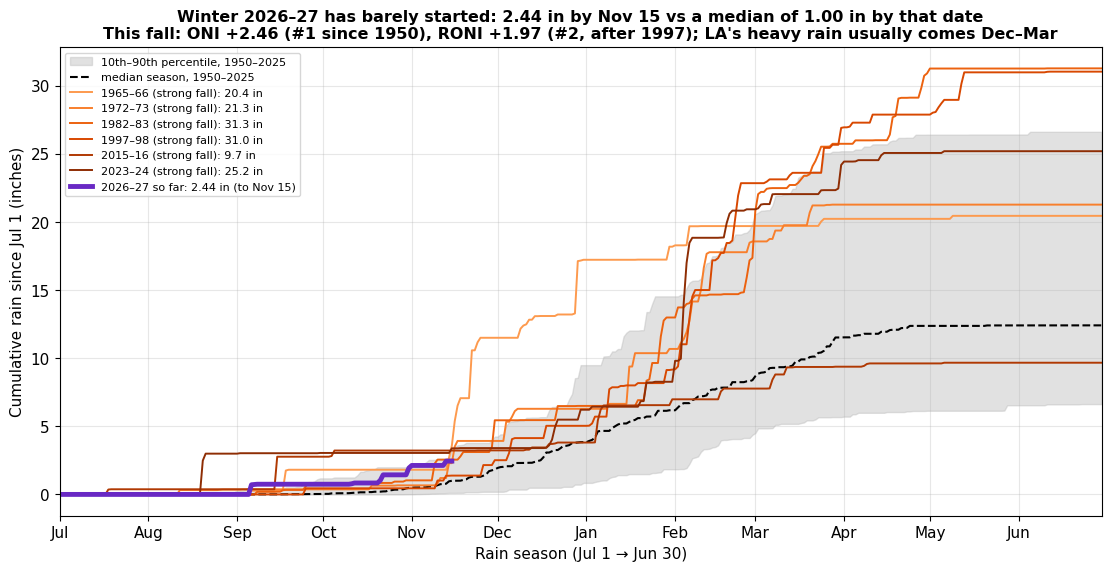

In [ ]:
# Chart 20: cumulative season rain, 2026-27 so far vs history and the strong-El Niño winters
cum = (la[la["season"].between(1950, 2026) & (la["day_of_season"] < 365)]
       .assign(inch=lambda t: t["mm"].fillna(0) / 25.4)
       .pivot_table(index="day_of_season", columns="season", values="inch", aggfunc="sum")
       .cumsum())
hist = cum.loc[:, [s for s in cum.columns if s <= 2025 and s in set(seasons["season"])]]
fig, ax = plt.subplots(figsize=(11, 5.6), layout="constrained")
ax.fill_between(hist.index, hist.quantile(0.1, axis=1), hist.quantile(0.9, axis=1), color="#bdbdbd", alpha=.45,
                label="10th–90th percentile, 1950–2025")
ax.plot(hist.index, hist.median(axis=1), color="black", lw=1.5, ls="--", label="median season, 1950–2025")
strong_colors = plt.cm.Oranges(np.linspace(0.45, 0.95, len(strong_tbl)))
for c, (_, r) in zip(strong_colors, strong_tbl.iterrows()):
    ax.plot(cum.index, cum[r["season"]], color=c, lw=1.4, label=f"{r['winter']} (strong fall): {r['inches']:.1f} in")
now = cum.loc[:day_cut, 2026]
ax.plot(now.index, now.values, color="#6929c4", lw=3.5, label=f"2026–27 so far: {now_in:.2f} in (to {last_obs:%b %d})")
month_starts = pd.date_range("2025-07-01", periods=12, freq="MS")
ax.set_xticks((month_starts - pd.Timestamp("2025-07-01")).days, month_starts.strftime("%b"))
ax.set(xlim=(0, 364), xlabel="Rain season (Jul 1 → Jun 30)", ylabel="Cumulative rain since Jul 1 (inches)")
ax.grid(alpha=.3)
ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"Winter 2026–27 has barely started: {now_in:.2f} in by {last_obs:%b %d} vs a median of {hist_to_date.median():.2f} in "
             f"by that date\nThis fall: ONI {aso_2026['aso_oni']:+.2f} (#{rank_oni} since 1950), RONI {aso_roni_2026:+.2f} "
             f"(#{rank_roni}, after {', '.join(map(str, ahead_roni))}); LA's heavy rain usually comes Dec–Mar")
ax.title.set_fontsize(11.5)
save(fig, "20_q3_season_2026_27.png")

In [ ]:
summary["q3"] = {
    "definitions": {"season": "Jul 1 - Jun 30, labelled by start year", "wet": f"season total > median of 1950-2025 seasons ({la_median:.2f} in)",
                    "heavy_day": ">= 1 inch (25.4 mm)", "fall_phase": "Aug-Oct (ASO) index: >= +0.5 El Nino, <= -0.5 La Nina",
                    "strong": "ASO index >= 1.5"},
    "wet_odds_by_oni_phase": {p: {"wet": int(r["wet"]), "n": int(r["n"]), "share": round(float(r["wet_share"]), 2),
                                  "ci95": [round(float(r["ci_low"]), 2), round(float(r["ci_high"]), 2)],
                                  "heavy_mean": round(float(r["heavy_mean"]), 2), "median_in": round(float(r["median_in"]), 2)}
                              for p, r in odds_oni.iterrows()},
    "elnino_vs_other": {"wet_elnino": f"{wet_en}/{n_en}", "wet_other": f"{wet_ot}/{n_ot}", "risk_ratio": round(float(risk_ratio), 2),
                        "fisher_one_sided_p": round(float(p_fisher), 3), "odds_ratio": round(float(odds_ratio), 2),
                        "heavy_mean_elnino": round(float(heavy_arr[en].mean()), 2), "heavy_mean_other": round(float(heavy_arr[~en].mean()), 2),
                        "heavy_permutation_p": round(float(p_heavy), 4),
                        "mean_in_elnino": round(float(inch_arr[en].mean()), 2), "mean_in_other": round(float(inch_arr[~en].mean()), 2),
                        "inches_permutation_p": round(float(p_inch), 4)},
    "wet_odds_by_strength": {idx: {s: {"wet": int(r["wet"]), "n": int(r["n"]), "share": round(float(r["wet_share"]), 2),
                                       "ci95": [round(float(r["ci_low"]), 2), round(float(r["ci_high"]), 2)],
                                       "heavy_mean": round(float(r["heavy_mean"]), 2), "median_in": round(float(r["median_in"]), 2)}
                                   for s, r in odds_by_index.loc[idx].iterrows()} for idx in ["ONI", "RONI"]},
    "wet_odds_by_roni_phase": {p: {"wet": int(r["wet"]), "n": int(r["n"]), "share": round(float(r["wet_share"]), 2),
                                   "heavy_mean": round(float(r["heavy_mean"]), 2)} for p, r in odds_roni_3.iterrows()},
    "strong_falls": [{"winter": r["winter"], "aso_oni": round(float(r["aso_oni"]), 2), "aso_roni": round(float(r["aso_roni"]), 2),
                      "strong_by": r["strong_by"], "inches": round(float(r["inches"]), 2), "heavy_days": int(r["heavy"]), "wet": bool(r["wet"])}
                     for _, r in strong_tbl.iterrows()],
    "winter_2026_27": {"aso_oni": round(float(aso_2026["aso_oni"]), 2), "aso_oni_rank_since_1950": rank_oni,
                       "aso_roni": round(aso_roni_2026, 2), "aso_roni_rank_since_1950": rank_roni, "roni_higher_seasons": ahead_roni,
                       "season_to_date_in": round(now_in, 2), "through": str(last_obs.date()), "valid_days": valid_2026,
                       "median_to_date_1950_2025_in": round(float(hist_to_date.median()), 2),
                       "pct_of_past_seasons_below": round(pct_rank, 2), "typical_share_of_season_by_this_date": round(share_by_date, 3),
                       "note": "season-to-date changes with every download of the station file"},
}
summary["q3"]["elnino_vs_other"]

{'wet_elnino': '13/20',
 'wet_other': '25/56',
 'risk_ratio': 1.46,
 'fisher_one_sided_p': 0.096,
 'odds_ratio': 2.3,
 'heavy_mean_elnino': 5.7,
 'heavy_mean_other': 3.75,
 'heavy_permutation_p': 0.0145,
 'mean_in_elnino': 17.98,
 'mean_in_other': 13.2,
 'inches_permutation_p': 0.0103}

**Reading Q3.**
* After an El Niño fall, LA had a wetter-than-median winter about 2 times in 3, against a bit under half after other falls. With 20
  El Niño seasons this difference alone is suggestive rather than conclusive (Fisher p ≈ 0.1), but El Niño winters also bring clearly
  more rain in total and more ≥ 1-inch days (permutation p ≈ 0.01), and those days drive local flooding.
* Strong falls (index ≥ 1.5) were followed by a wet winter in 5 of the 6 cases flagged by either index; 2015–16 is the reminder that a
  strong El Niño does not guarantee rain in LA. With 4–6 cases per index the intervals are wide (roughly 30–95 %).
* Labelling the falls with RONI instead of ONI gives nearly the same picture (El Niño falls 14 of 21 wet, against 13 of 20 with ONI).
* 2026–27: by either index this is one of the two strongest falls since 1950, so the odds lean towards a wet, stormy winter. This is a
  seasonal risk outlook, not a forecast. The station file and CPC's indices are updated every month, so the to-date numbers will change.

## 9. Extension: the same buoy array from 1998 to 2026 (NOAA PMEL GTMBA)

The UCI file stops on 1998-06-23, but the TAO/TRITON moorings kept reporting. NOAA PMEL publishes the same daily readings (the Global
Tropical Moored Buoy Array, GTMBA) on its ERDDAP data server. Adding them gives 28 more years and many more El Niño and La Niña
episodes (2002, 2009, 2015, 2023 and 2026 among the El Niños), so we can:

* **9.2** check that the two sources agree on the year they share (July 1997 – June 1998);
* **9.4 Q1** repeat the phase comparison on years the earlier sections never saw;
* **9.5 Q2** test the forecast models out of sample on 1999–2026, one year at a time;
* **9.6** read what the buoys say about this winter (Q3, 2026–27).

Quality control follows the ERDDAP metadata: every reading has a quality code (0 missing, 1 highest, 2 standard, 3 lower,
4 questionable, 5 bad) and we keep codes 1–3, as PMEL recommends. The first run downloads about 150 MB (3–4 minutes) into
`data/raw/gtmba/`; later runs read the cache.

In [ ]:
# 9.1 GTMBA loader (helper code; fold this cell).
# Downloads the daily TAO/TRITON files from NOAA PMEL's ERDDAP server one calendar year at a time, caches them
# under data/raw/gtmba/, keeps readings with quality codes 1-3, and returns one row per buoy-day with the
# same columns as the UCI table: date, station, site, site_lat, site_lon, sst, air_temp, zon_wind, mer_wind, humidity.
# Winds keep the UCI signs: zon_wind + = toward the east (westerly), mer_wind + = toward the north (southerly).
import datetime as dt
import http.client
import os
import socket
import time
import urllib.error
import urllib.parse
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

ERDDAP_BASES = (
    "https://data.pmel.noaa.gov/pmel/erddap/tabledap",
    "https://coastwatch.pfeg.noaa.gov/erddap/tabledap",
)
ARRAY = "TAO/TRITON"
COMMON_COLS = ["station", "longitude", "latitude", "time", "depth"]

# key -> (ERDDAP dataset, {output column: value variable}, quality variables)
DATASETS = {
    "sst": ("pmelTaoDySst", {"sst": "T_25"}, ["QT_5025"]),
    "air_temp": ("pmelTaoDyAirt", {"air_temp": "AT_21"}, ["QAT_5021"]),
    "wind": ("pmelTaoDyW", {"zon_wind": "WU_422", "mer_wind": "WV_423"},
             ["QWS_5401", "QWD_5410"]),
    "humidity": ("pmelTaoDyRh", {"humidity": "RH_910"}, ["QRH_5910"]),
}
VALUE_COLS = ["sst", "air_temp", "zon_wind", "mer_wind", "humidity"]
OUT_COLS = ["date", "station", "site", "site_lat", "site_lon"] + VALUE_COLS
GOOD_QUALITY = (1, 2, 3)
RECENT_DAYS = 400
RETRIES_PER_SERVER = 4
TIMEOUT_S = 180
CONNECT_TIMEOUT_S = 10
NO_DATA_MARKER = "Your query produced no matching results"


# site_name() is the section 2.3 function; GTMBA sites are named the same way.


def _chunk_url(base: str, dataset: str, variables: list[str], year: int) -> str:
    q = lambda s: urllib.parse.quote(s, safe="")
    array = q('"' + ARRAY + '"')
    t0 = q(f"{year}-01-01T00:00:00Z")
    t1 = q(f"{year + 1}-01-01T00:00:00Z")
    return (f"{base}/{dataset}.csv?{','.join(variables)}"
            f"&array={array}&time%3E={t0}&time%3C{t1}")


def _create_connection(address, timeout=None, source_address=None, *args, **kwargs):
    """IPv4-first connect with a short per-address connect timeout.

    The CoastWatch ERDDAP (which PMEL redirects to) advertises an IPv6 address;
    on networks without working IPv6 urllib would otherwise stall a full
    timeout per request before falling back to IPv4.
    """
    host, port = address
    infos = socket.getaddrinfo(host, port, 0, socket.SOCK_STREAM)
    infos.sort(key=lambda info: info[0] != socket.AF_INET)
    last_err = None
    for family, socktype, proto, _, sockaddr in infos:
        sock = socket.socket(family, socktype, proto)
        try:
            sock.settimeout(CONNECT_TIMEOUT_S)
            if source_address:
                sock.bind(source_address)
            sock.connect(sockaddr)
            sock.settimeout(timeout)
            return sock
        except OSError as err:
            last_err = err
            sock.close()
    raise last_err or OSError(f"cannot resolve {host}")


class _HTTPConnection(http.client.HTTPConnection):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._create_connection = _create_connection  # set per instance by http.client


class _HTTPSConnection(http.client.HTTPSConnection):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._create_connection = _create_connection


class _HTTPHandler(urllib.request.HTTPHandler):
    def http_open(self, req):
        return self.do_open(_HTTPConnection, req)


class _HTTPSHandler(urllib.request.HTTPSHandler):
    def https_open(self, req):
        return self.do_open(_HTTPSConnection, req)


_OPENER = urllib.request.build_opener(_HTTPHandler, _HTTPSHandler)


def _fetch(url: str) -> bytes | None:
    """Return the CSV body, or None when ERDDAP reports an empty result."""
    req = urllib.request.Request(url, headers={"User-Agent": "BANA212-elnino/1.0"})
    try:
        with _OPENER.open(req, timeout=TIMEOUT_S) as resp:
            return resp.read()
    except urllib.error.HTTPError as err:
        body = err.read().decode("utf-8", "replace")
        if err.code == 404 and NO_DATA_MARKER in body:
            return None
        raise


def _download_chunk(dataset: str, variables: list[str], year: int, path: Path,
                    stats: dict) -> None:
    header = ",".join(variables) + "\n"
    errors = []
    for base in ERDDAP_BASES:
        url = _chunk_url(base, dataset, variables, year)
        for attempt in range(RETRIES_PER_SERVER):
            try:
                t0 = time.monotonic()
                body = _fetch(url)
                if body is None:
                    body = header.encode()  # empty chunk: cache header only
                elif not body.decode("utf-8", "replace").startswith(header):
                    raise ValueError(f"unexpected response header from {url}")
                tmp = path.with_suffix(".part")
                tmp.write_bytes(body)
                os.replace(tmp, path)
                stats["downloads"] += 1
                stats["bytes"] += len(body)
                stats["seconds"] += time.monotonic() - t0
                if base != ERDDAP_BASES[0]:
                    stats["mirror_downloads"].append(path.name)
                return
            except (urllib.error.URLError, TimeoutError, ConnectionError,
                    ValueError, OSError) as err:
                errors.append(f"{base} attempt {attempt + 1}: {err}")
                time.sleep(min(2 ** attempt * 2, 30))
    raise RuntimeError(f"Failed to download {dataset} {year}:\n" + "\n".join(errors))


def _read_chunk(path: Path, value_map: dict, qual_cols: list[str]) -> pd.DataFrame:
    df = pd.read_csv(path, skiprows=[1], dtype={"station": str})
    if df.empty:
        return pd.DataFrame(columns=["station", "date", "latitude", "longitude",
                                     "depth", *value_map])
    good = np.ones(len(df), dtype=bool)
    for q in qual_cols:
        good &= df[q].isin(GOOD_QUALITY).to_numpy()
    out = df[["station", "latitude", "longitude", "depth"]].copy()
    out["date"] = (pd.to_datetime(df["time"], utc=True)
                   .dt.tz_localize(None).dt.normalize())
    for col, var in value_map.items():
        vals = pd.to_numeric(df[var], errors="coerce")
        out[col] = vals.where(good & (vals.abs() < 1e30))
    return out


def _load_variable(key: str, years: list[int], cache_dir: Path, recent_cut: dt.date,
                   refresh_recent: bool, stats: dict) -> pd.DataFrame:
    dataset, value_map, qual_cols = DATASETS[key]
    variables = COMMON_COLS + list(value_map.values()) + qual_cols
    frames = []
    for year in years:
        path = cache_dir / f"{dataset}_{year}.csv"
        touches_recent = dt.date(year, 12, 31) >= recent_cut
        if os.path.exists(path) and not (refresh_recent and touches_recent):
            stats["cache_hits"] += 1
        else:
            _download_chunk(dataset, variables, year, path, stats)
        frames.append(_read_chunk(path, value_map, qual_cols))
    df = pd.concat(frames, ignore_index=True)
    vcols = list(value_map)
    df = df[df[vcols].notna().any(axis=1)]
    # Several sensors per station-day: keep the one closest to the sea surface
    # (SST depth is positive down; met heights are stored as negative depth).
    stats["duplicate_depth_rows"][key] = int(df.duplicated(["station", "date"]).sum())
    df = (df.assign(_absdepth=df["depth"].abs())
            .sort_values(["station", "date", "_absdepth", "depth"])
            .drop_duplicates(["station", "date"], keep="first"))
    return df[["station", "date", "latitude", "longitude", *vcols]]


def load_gtmba_daily(start: str, end: str | None, cache_dir: Path,
                     refresh_recent: bool = False) -> pd.DataFrame:
    """Daily TAO/TRITON buoy data, one row per station-day, UCI column conventions.

    ``end=None`` returns everything available. Download statistics are attached
    as ``df.attrs["gtmba_stats"]``.
    """
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    start_ts = pd.Timestamp(start).normalize()
    today = dt.datetime.now(dt.timezone.utc).date()
    end_ts = pd.Timestamp(end).normalize() if end is not None else pd.Timestamp(today)
    years = list(range(start_ts.year, end_ts.year + 1))
    recent_cut = today - dt.timedelta(days=RECENT_DAYS)
    stats = {"downloads": 0, "cache_hits": 0, "bytes": 0, "seconds": 0.0,
             "mirror_downloads": [], "duplicate_depth_rows": {}}

    parts = [_load_variable(k, years, cache_dir, recent_cut, refresh_recent, stats)
             for k in DATASETS]
    pos = pd.concat([p[["station", "latitude", "longitude"]] for p in parts])
    pos = pos.dropna().drop_duplicates()
    stats["stations_with_multiple_positions"] = sorted(
        pos.loc[pos.duplicated("station", keep=False), "station"].unique())
    pos = pos.groupby("station", as_index=False).first()

    merged = parts[0].drop(columns=["latitude", "longitude"])
    for p in parts[1:]:
        merged = merged.merge(p.drop(columns=["latitude", "longitude"]),
                              on=["station", "date"], how="outer")
    merged = merged.merge(pos, on="station", how="left")
    merged = merged[(merged["date"] >= start_ts) & (merged["date"] <= end_ts)]
    merged = merged[merged[VALUE_COLS].notna().any(axis=1)]

    merged["site_lat"] = np.rint(merged["latitude"]).astype(int)
    merged["site_lon"] = (np.rint(merged["longitude"]).astype(int)) % 360
    merged["site"] = [site_name(a, o) for a, o in zip(merged["site_lat"], merged["site_lon"])]
    merged["date"] = merged["date"].astype("datetime64[ns]")
    for c in VALUE_COLS:
        merged[c] = merged[c].astype(float)
    out = (merged[OUT_COLS].sort_values(["date", "station"])
           .reset_index(drop=True))
    stats["seconds"] = round(stats["seconds"], 1)
    out.attrs["gtmba_stats"] = stats
    return out


In [ ]:
# 9.1 Download (or read from the cache) the daily GTMBA files from July 1997 to today
GT_CACHE = RAW / "gtmba"
REFRESH_RECENT = os.environ.get("BANA212_REFRESH_RECENT") == "1"   # the 11/22 freeze run sets this to re-download the latest year
gt = load_gtmba_daily("1997-07-01", None, GT_CACHE, refresh_recent=REFRESH_RECENT)
gt_stats = gt.attrs["gtmba_stats"]
print(f"{len(gt):,} station-days | {gt['station'].nunique()} stations | {gt['date'].min().date()} to {gt['date'].max().date()}")
print(f"downloaded {gt_stats['downloads']} files ({gt_stats['bytes'] / 1e6:.0f} MB, {gt_stats['seconds']:.0f} s); "
      f"read {gt_stats['cache_hits']} from the cache")
gt[VARS].describe().round(2)

604,365 station-days | 81 stations | 1997-07-01 to 2026-11-01
downloaded 120 files (151 MB, 330 s); read 0 from the cache


,sst,air_temp,zon_wind,mer_wind,humidity
count,497764.00,528865.00,476901.00,476901.00,498604.00
mean,27.86,27.02,-3.69,0.61,81.70
std,2.03,1.80,3.30,2.97,5.39
min,17.12,17.27,-11.75,-13.60,57.00
25%,26.85,26.14,-6.11,-1.41,78.00
50%,28.33,27.42,-4.40,0.60,81.50
75%,29.39,28.31,-1.90,2.70,85.17
max,31.69,33.71,17.70,11.50,103.40


In [ ]:
# 9.2 Do the two sources agree? Same buoy, same day, July 1997 - June 1998.
# UCI site names come from rounded *measured* positions (section 2.3), GTMBA names from the nominal mooring positions.
# Two moorings round to a neighbouring degree in UCI, so they are renamed before matching.
SITE_FIX = {"0_124W": ("0_125W", 0, 235), "2S_164E": ("2S_165E", -2, 165)}
assert not {new for new, _, _ in SITE_FIX.values()} & set(daily["site"]), "renaming would merge two UCI sites"
uci = daily[["date", "site", "site_lat", "site_lon", *VARS]].copy()
for old, (new, lat, lon) in SITE_FIX.items():
    uci.loc[uci["site"] == old, ["site", "site_lat", "site_lon"]] = [new, lat, lon]

ov = uci[uci["date"] >= "1997-07-01"].merge(gt[["date", "site", *VARS]], on=["date", "site"], suffixes=("_uci", "_gt"))
val = {}
for v in VARS:
    pair = ov[[v + "_uci", v + "_gt"]].dropna()
    diff = pair[v + "_gt"] - pair[v + "_uci"]
    val[v] = {"days": len(pair), "r": pair.corr().iloc[0, 1], "mean_diff": diff.mean(), "mean_abs_diff": diff.abs().mean()}
val = pd.DataFrame(val).T
print("buoys matched:", ov["site"].nunique(), "of", uci.loc[uci["date"] >= "1997-07-01", "site"].nunique(),
      "UCI buoys reporting in the shared year")
val.round(4)

buoys matched: 64 of 64 UCI buoys reporting in the shared year


,days,r,mean_diff,mean_abs_diff
sst,17777.0,0.9999,0.0003,0.0012
air_temp,16971.0,0.9988,-0.0039,0.0057
zon_wind,18046.0,0.9943,-0.0448,0.1674
mer_wind,18046.0,0.9941,0.0511,0.1817
humidity,17597.0,0.9936,0.0793,0.2181


In [ ]:
# 9.3 One daily table for 1980-2026: UCI up to its last day (1998-06-23), GTMBA after it
gt_new = gt[gt["date"] > daily["date"].max()]
ext = pd.concat([uci.assign(source="UCI"),
                 gt_new[["date", "site", "site_lat", "site_lon", *VARS]].assign(source="GTMBA")], ignore_index=True)
ext["year"], ext["month"] = ext["date"].dt.year, ext["date"].dt.month
ext["ym"] = ext["date"].dt.to_period("M").dt.to_timestamp()
ext = ext.merge(oni[["year", "month", "oni", "phase"]], on=["year", "month"], how="left", validate="many_to_one")
ext["phase"] = pd.Categorical(ext["phase"], categories=PHASES)     # NaN after the last published ONI month
ext["in_nino34"] = ext["site_lat"].between(-5, 5) & ext["site_lon"].between(190, 240)

LAST_DAY = ext["date"].max()
LAST_FULL_MONTH = (LAST_DAY + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.DateOffset(months=1)
EXT_CAL = pd.date_range(ext["ym"].min(), LAST_FULL_MONTH, freq="MS")
sst_sites = ext[ext["sst"].notna()].groupby("ym")["site"].nunique().reindex(EXT_CAL, fill_value=0)
after98 = sst_sites[sst_sites.index >= "1998-07-01"]
yearly_sst_sites = ext[ext["sst"].notna()].groupby("year")["site"].nunique()
months_by_phase = (ext[ext["phase"].notna()].groupby(["source", "phase"], observed=True)["ym"].nunique()
                   .unstack().reindex(columns=PHASES).reindex(["UCI", "GTMBA"]))
print(f"{len(ext):,} buoy-days | {ext['site'].nunique()} sites | {ext['date'].min().date()} to {LAST_DAY.date()} "
      f"(last full month {LAST_FULL_MONTH:%Y-%m})")
print(f"after June 1998 the fewest SST buoys in a month is {after98.min()} ({after98.idxmin():%Y-%m}); "
      f"months below 5 buoys: {(after98 < 5).sum()}")
print("SST buoys reporting per year:",
      yearly_sst_sites.loc[[1990, 1995, 2000, 2005, 2010, 2011, 2012, 2013, 2014, 2016, 2019, 2022, 2024, LAST_DAY.year]].to_dict())
months_by_phase

760,591 buoy-days | 99 sites | 1980-03-07 to 2026-11-01 (last full month 2026-10)
after June 1998 the fewest SST buoys in a month is 9 (2024-06); months below 5 buoys: 0
SST buoys reporting per year: {1990: 25, 1995: 67, 2000: 66, 2005: 69, 2010: 70, 2011: 70, 2012: 69, 2013: 57, 2014: 65, 2016: 61, 2019: 50, 2022: 44, 2024: 31, 2026: 47}


phase,La Niña,Neutral,El Niño
source,,,
UCI,37,111,63
GTMBA,103,156,81


In [ ]:
# 9.4 Q1 on new years. Same recipe as section 6: anomaly = reading minus the buoy's calendar-month mean over the same
# period, El Niño − La Niña gap in SD units, 95 % CI from a bootstrap over whole years. Run on the UCI years (must
# reproduce section 6), on the GTMBA years alone, and on both together.
for v in VARS:
    ext[v + "_anom"] = ext[v] - ext.groupby(["source", "site", "month"])[v].transform("mean")


def phase_gap(d, cols=Q1_VARS, seed=212, B=2000):
    """El Niño − La Niña mean anomaly in SD units, with a 95 % bootstrap CI over whole years (the section 6 recipe)."""
    years = np.sort(d["year"].unique())
    g = d.groupby(["year", "phase"], observed=True)[cols]
    sums = g.sum().unstack("phase").reindex(years).fillna(0)
    counts = g.count().unstack("phase").reindex(years).fillna(0)
    sd = d[cols].std()
    draws = np.random.default_rng(seed).multinomial(len(years), np.full(len(years), 1 / len(years)), size=B)
    with np.errstate(invalid="ignore", divide="ignore"):
        boot = pd.DataFrame((draws @ sums.to_numpy()) / (draws @ counts.to_numpy()), columns=sums.columns)
    point = (sums.sum() / counts.sum()).unstack("phase")
    out = {}
    for c in cols:
        gap_boot = (boot[(c, "El Niño")] - boot[(c, "La Niña")]) / sd[c]
        out[c] = {"gap_sd": (point.loc[c, "El Niño"] - point.loc[c, "La Niña"]) / sd[c],
                  "lo": np.nanpercentile(gap_boot, 2.5), "hi": np.nanpercentile(gap_boot, 97.5),
                  "gap_units": point.loc[c, "El Niño"] - point.loc[c, "La Niña"], "years": len(years)}
    return pd.DataFrame(out).T


Q1_PERIODS = {"uci_1980_98": "1980–98 (UCI, section 6)", "gtmba_1998_on": f"1998–{LAST_DAY:%Y} (GTMBA, new)",
              "all": f"1980–{LAST_DAY:%Y} (both)"}
lab = ext[ext["phase"].notna()]
q1_rep = pd.concat({"uci_1980_98": phase_gap(lab[lab["source"] == "UCI"]),
                    "gtmba_1998_on": phase_gap(lab[lab["source"] == "GTMBA"]),
                    "all": phase_gap(lab)}, names=["period", "variable"])
assert np.allclose(q1_rep.loc["uci_1980_98"].loc[q1.index, ["gap_sd", "lo", "hi"]].to_numpy(dtype=float),
                   q1[["gap_sd", "gap_lo", "gap_hi"]].to_numpy(dtype=float)), "should reproduce section 6"
(q1_rep[["gap_sd", "lo", "hi", "gap_units"]].astype(float).unstack("period")
 .reindex(q1.index).swaplevel(axis=1).reindex(columns=list(Q1_PERIODS), level=0).round(2))

period        uci_1980_98                       gtmba_1998_on              \
                   gap_sd    lo    hi gap_units        gap_sd    lo    hi   
variable                                                                    
sst_anom             1.42  1.02  2.23      1.41          1.40  1.20  1.61   
air_temp_anom        1.33  0.97  2.00      1.25          1.31  1.12  1.50   
zon_wind_anom        0.67  0.49  0.78      1.67          0.63  0.50  0.75   
humidity_anom       -0.13 -0.25  0.05     -0.57         -0.24 -0.42 -0.09   
mer_wind_anom       -0.03 -0.33  0.18     -0.06          0.02 -0.14  0.17   

period                     all                        
              gap_units gap_sd    lo    hi gap_units  
variable                                              
sst_anom           1.21   1.36  1.18  1.53      1.21  
air_temp_anom      1.12   1.26  1.10  1.42      1.11  
zon_wind_anom      1.47   0.62  0.52  0.72      1.48  
humidity_anom     -1.04  -0.22 -0.35 -0.09     -0.93  
mer_wind_anom      0.04   0.00 -0.13  0.12      0.00

saved charts/21_ext_coverage_and_signal.png


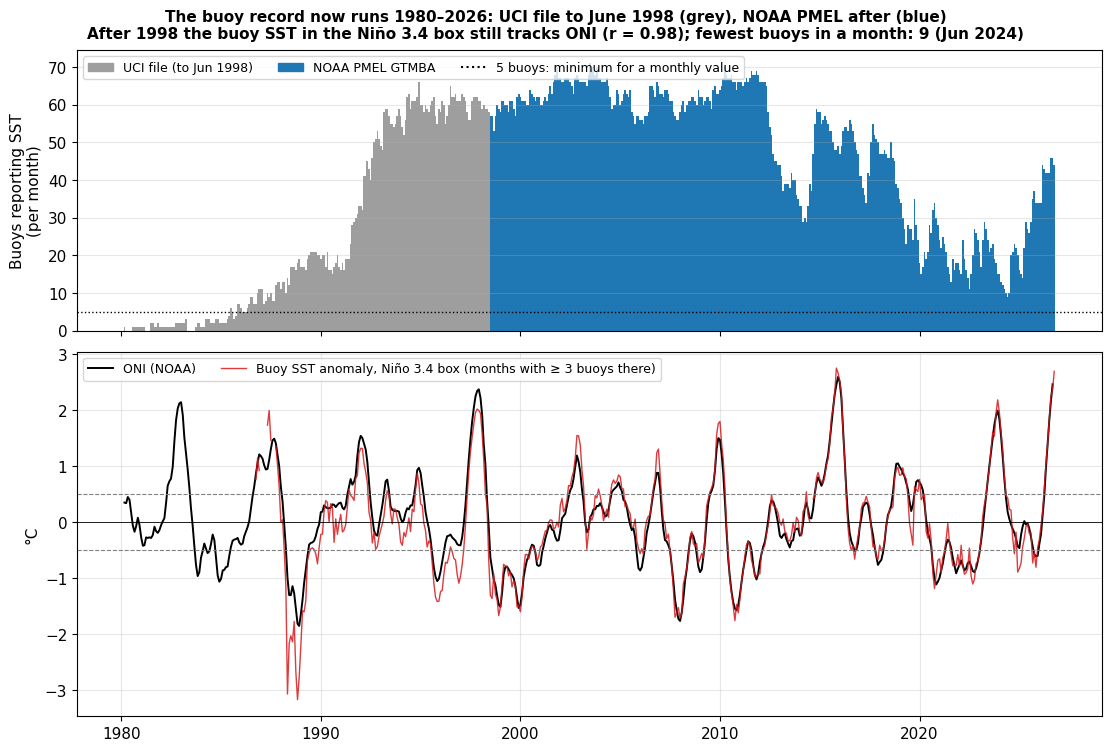

In [ ]:
# Chart 21: how many buoys report, 1980-2026, and does the buoy SST still track ONI after 1998?
box = ext[ext["in_nino34"] & ext["sst_anom"].notna()].groupby("ym")
n34 = box["sst_anom"].mean().reindex(EXT_CAL).where(box["site"].nunique().reindex(EXT_CAL) >= 3)   # >= 3 buoys in the box
oni_m = oni.set_index("ym")["oni"].reindex(EXT_CAL)
new_era = EXT_CAL >= "1998-07-01"
r_new = n34[new_era].corr(oni_m[new_era])

fig, axes = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, layout="constrained", height_ratios=[1, 1.3])
axes[0].bar(EXT_CAL, sst_sites.to_numpy(), width=31, color=np.where(new_era, "#1f77b4", "#9e9e9e"))
axes[0].axhline(5, color="black", ls=":", lw=1)
axes[0].set_ylabel("Buoys reporting SST\n(per month)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#9e9e9e"), plt.Rectangle((0, 0), 1, 1, color="#1f77b4"),
                        plt.Line2D([], [], color="black", ls=":")],
               labels=["UCI file (to Jun 1998)", "NOAA PMEL GTMBA", "5 buoys: minimum for a monthly value"],
               loc="upper left", fontsize=9, ncol=3)
axes[0].grid(axis="y", alpha=.3)
axes[1].plot(EXT_CAL, oni_m, color="black", lw=1.4, label="ONI (NOAA)")
axes[1].plot(EXT_CAL, n34, color="#d7191c", lw=1, alpha=.85, label="Buoy SST anomaly, Niño 3.4 box (months with ≥ 3 buoys there)")
for y in (0.5, -0.5):
    axes[1].axhline(y, color="gray", ls="--", lw=.8)
axes[1].axhline(0, color="black", lw=.6)
axes[1].set_ylabel("°C")
axes[1].legend(loc="upper left", fontsize=9, ncol=2)
axes[1].grid(alpha=.3)
fig.suptitle(f"The buoy record now runs {EXT_CAL[0]:%Y}–{LAST_FULL_MONTH:%Y}: UCI file to June 1998 (grey), NOAA PMEL after (blue)\n"
             f"After 1998 the buoy SST in the Niño 3.4 box still tracks ONI (r = {r_new:.2f}); "
             f"fewest buoys in a month: {after98.min()} ({after98.idxmin():%b %Y})", fontsize=11, fontweight="bold")
save(fig, "21_ext_coverage_and_signal.png")

saved charts/22_ext_q1_replication.png


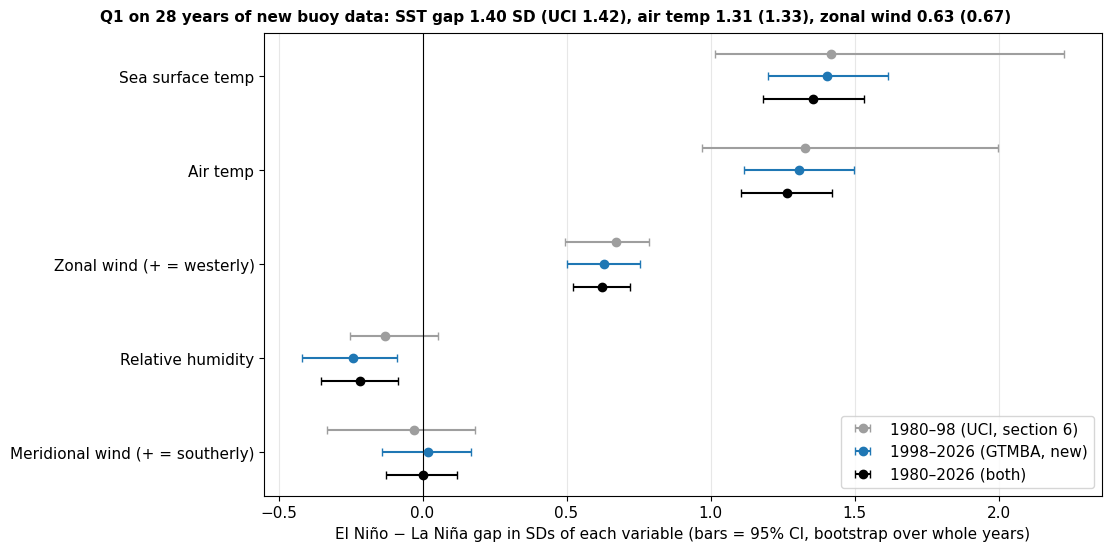

In [ ]:
# Chart 22: Q1 on the new years vs the UCI years
fig, ax = plt.subplots(figsize=(11, 5.4), layout="constrained")
order = q1.index[::-1]
ypos = np.arange(len(order))
for key, dy, color in [("uci_1980_98", 0.24, "#9e9e9e"), ("gtmba_1998_on", 0, "#1f77b4"), ("all", -0.24, "black")]:
    t = q1_rep.loc[key].loc[order].astype(float)
    ax.errorbar(t["gap_sd"], ypos + dy, xerr=[t["gap_sd"] - t["lo"], t["hi"] - t["gap_sd"]], fmt="o", ms=6, capsize=3,
                color=color, label=Q1_PERIODS[key])
ax.axvline(0, color="black", lw=.8)
ax.set_yticks(ypos, [Q1_LABELS[v] for v in order])
ax.set_xlabel("El Niño − La Niña gap in SDs of each variable (bars = 95% CI, bootstrap over whole years)")
ax.grid(axis="x", alpha=.3)
ax.legend(loc="lower right")
g_old, g_new = q1_rep.loc["uci_1980_98"].astype(float), q1_rep.loc["gtmba_1998_on"].astype(float)
fig.suptitle(f"Q1 on {LAST_DAY.year - 1998} years of new buoy data: SST gap {g_new.loc['sst_anom', 'gap_sd']:.2f} SD "
             f"(UCI {g_old.loc['sst_anom', 'gap_sd']:.2f}), air temp {g_new.loc['air_temp_anom', 'gap_sd']:.2f} "
             f"({g_old.loc['air_temp_anom', 'gap_sd']:.2f}), zonal wind {g_new.loc['zon_wind_anom', 'gap_sd']:.2f} "
             f"({g_old.loc['zon_wind_anom', 'gap_sd']:.2f})", fontsize=11, fontweight="bold")
save(fig, "22_ext_q1_replication.png")

In [ ]:
# 9.5 Q2 out of sample, 1999-2026. Each test year is forecast by models fitted on the 30 years before it, with the
# anomalies measured against those same 30 years: only past data is used, and the long-term warming trend does not
# pile up in the anomalies. Same features, models, persistence baseline and scoring as section 7.
CLIM_YEARS = 30
EXT_YEARS = range(1999, LAST_FULL_MONTH.year + 1)
EXT_K = [0, 1, 3, 6]
ext_feats = {yr: monthly_features(pd.Timestamp(f"{yr - 1}-12-31"), data=ext, calendar=EXT_CAL, window=CLIM_YEARS)
             for yr in EXT_YEARS}
ext_final = {}   # the last test year's fitted models and inputs, reused for the 2026-27 outlook in 9.6


def ext_walk_forward(k, models):
    """Predictions for every issue month in 1999-now, each year from models fitted on the 30 years before it."""
    parts = []
    for yr in EXT_YEARS:
        end = pd.Timestamp(f"{yr - 1}-12-31")
        train, test = split_rows(build_rows(ext_feats[yr], k), end, test_year=yr)
        train = train[train.index > end - pd.DateOffset(years=CLIM_YEARS)]
        out = test[["target", "target_month", "phase_lag1"]].copy()
        for name, (make, cols) in models.items():
            model = make().fit(train[cols], train["target"])
            out[name] = model.predict(test[cols])
            if yr == EXT_YEARS[-1]:
                ext_final[(k, name)] = (model, test[cols])
        parts.append(out)
    return pd.concat(parts)


ext_preds = {k: ext_walk_forward(k, MODELS) for k in EXT_K}
ext_res = []
for k, p in ext_preds.items():
    p = p[p["target"].notna()]                      # the newest target months are not published yet
    ext_res.append({"k": k, "model": PERSIST, **scores(p["target"], p["phase_lag1"], p["phase_lag1"])})
    ext_res += [{"k": k, "model": name, **scores(p["target"], p[name], p["phase_lag1"])} for name in MODELS]
ext_res = pd.DataFrame(ext_res)

p3 = ext_preds[3][ext_preds[3]["target"].notna()]
halves = np.where(p3.index.year <= 2012, "1999–2012", f"2013–{LAST_FULL_MONTH.year}")
ext_halves = pd.DataFrame({h: {m: balanced_accuracy_score(g["target"], g["phase_lag1" if m == PERSIST else m])
                               for m in [PERSIST, *MODELS]} for h, g in p3.groupby(halves)})
print("test months per horizon:", ext_res.groupby("k")["months"].first().to_dict())
print("balanced accuracy at k=3 by half:\n", ext_halves.round(2))
ext_res.assign(changes=ext_res["changes_caught"].astype(str) + "/" + ext_res["phase_changes"].astype(str)).pivot(
    index="model", columns="k", values=["balanced_accuracy", "changes"]).reindex([PERSIST, *MODELS]).round(2)

test months per horizon: {0: 333, 1: 332, 3: 330, 6: 327}
balanced accuracy at k=3 by half:
                                    1999–2012  2013–2026
Persistence (latest ONI)                0.54       0.59
Logistic, buoys only                    0.68       0.75
Logistic, buoys + latest ONI            0.68       0.74
Random forest, buoys + latest ONI       0.67       0.71


balanced_accuracy                      \
k                                                 0         1         3   
model                                                                     
Persistence (latest ONI)                   0.882152  0.769138  0.576374   
Logistic, buoys only                       0.894076  0.858523  0.714321   
Logistic, buoys + latest ONI                0.91488  0.871734  0.706091   
Random forest, buoys + latest ONI          0.926733   0.86719  0.687811   

                                            changes                         
k                                         6       0      1       3       6  
model                                                                       
Persistence (latest ONI)           0.451014    0/40   0/78   0/141   0/175  
Logistic, buoys only               0.574331   25/40  52/78  75/141  74/175  
Logistic, buoys + latest ONI        0.55684   25/40  52/78  73/141  76/175  
Random forest, buoys + latest ONI  0.492392   27/40  46/78  77/141  83/175

In [ ]:
# 9.5b Which single reading carries the signal on the new years? One-feature logistic models, same walk-forward
ext_single = {}
for k in [0, 3]:
    sp = ext_walk_forward(k, SINGLE)
    sp = sp[sp["target"].notna()]
    for lab_, _ in SINGLE.items():
        ext_single.setdefault(lab_, {})[f"k={k}"] = balanced_accuracy_score(sp["target"], sp[lab_])
ext_single = pd.DataFrame(ext_single).T.sort_values("k=3", ascending=False)
ext_persist = ext_res[ext_res["model"] == PERSIST].set_index("k")["balanced_accuracy"]
ext_single.round(2)

,k=0,k=3
"Air temp anom, all buoys",0.84,0.66
"SST anom, all buoys",0.83,0.66
"SST anom, Niño 3.4 box",0.90,0.64
"Zonal wind anom, west Pacific (≤180°)",0.70,0.64
Latest official ONI (month t−1),0.89,0.61
"Zonal wind anom, all buoys",0.67,0.60
"1-month change: SST, Niño 3.4 box",0.37,0.46
"1-month change: zonal wind, west Pacific",0.36,0.38
"Meridional wind anom, all buoys",0.32,0.33


saved charts/23_ext_q2_walk_forward.png


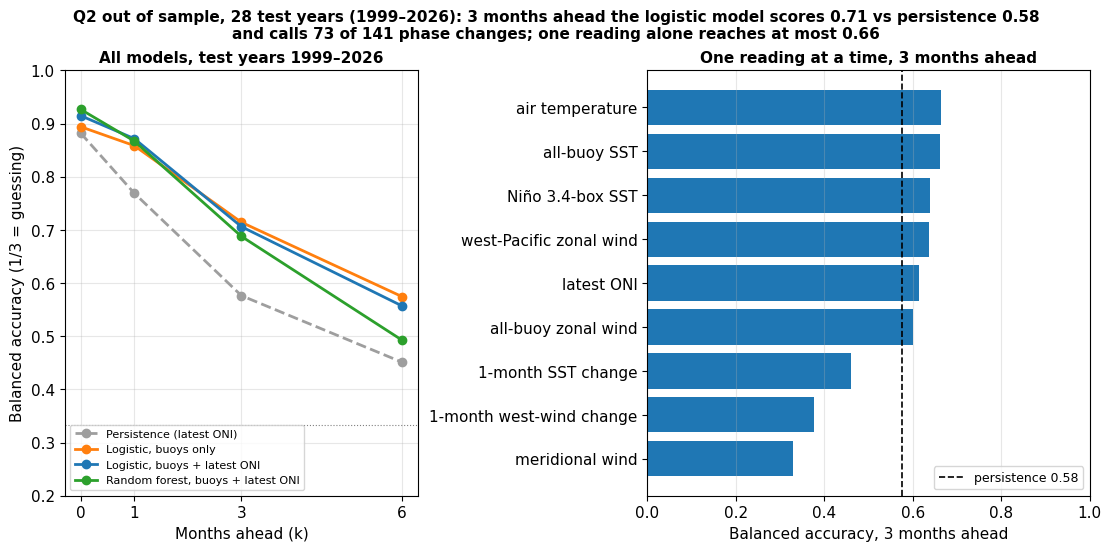

In [ ]:
# Chart 23: Q2 tested on 1999-2026
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), layout="constrained", width_ratios=[1, 1.25])
ax = axes[0]
for name in [PERSIST, *MODELS]:
    r = ext_res[ext_res["model"] == name].set_index("k")
    ax.plot(r.index, r["balanced_accuracy"], marker="o", lw=2, color=MODEL_COLORS[name], label=name,
            ls="--" if name == PERSIST else "-")
ax.set(xticks=EXT_K, xlabel="Months ahead (k)", ylabel="Balanced accuracy (1/3 = guessing)", ylim=(0.2, 1))
ax.axhline(1 / 3, color="gray", lw=.8, ls=":")
ax.grid(alpha=.3)
ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"All models, test years 1999–{LAST_FULL_MONTH.year}", fontsize=11)
ax = axes[1]
y = np.arange(len(ext_single))
ax.barh(y, ext_single["k=3"], color="#1f77b4")
ax.axvline(ext_persist[3], color="black", ls="--", lw=1.2, label=f"persistence {ext_persist[3]:.2f}")
ax.set_yticks(y, [SHORT.get(i, "latest ONI") for i in ext_single.index])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="Balanced accuracy, 3 months ahead")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=.3)
ax.set_title("One reading at a time, 3 months ahead", fontsize=11)
lr = ext_res[(ext_res["model"] == "Logistic, buoys + latest ONI")].set_index("k")
fig.suptitle(f"Q2 out of sample, {len(EXT_YEARS)} test years ({EXT_YEARS[0]}–{EXT_YEARS[-1]}): 3 months ahead the logistic model scores "
             f"{lr.loc[3, 'balanced_accuracy']:.2f} vs persistence {ext_persist[3]:.2f}\nand calls {lr.loc[3, 'changes_caught']} of "
             f"{lr.loc[3, 'phase_changes']} phase changes; one reading alone reaches at most {ext_single['k=3'].max():.2f}",
             fontsize=11, fontweight="bold")
save(fig, "23_ext_q2_walk_forward.png")

In [ ]:
# 9.6 What the buoys say about winter 2026-27: the latest full month of buoy data through the models of the last test year
issue = LAST_FULL_MONTH
now_feats = ext_feats[EXT_YEARS[-1]].loc[issue]
latest_oni = oni.iloc[-1]
print(f"issue month {issue:%Y-%m}: buoys reporting {int(now_feats['n_sites'])}, Niño 3.4-box SST anomaly {now_feats['sst_n34']:+.2f} °C, "
      f"west-Pacific zonal wind anomaly {now_feats['zw_west']:+.2f} m/s; latest ONI {latest_oni['SEAS']} {latest_oni['year']} = "
      f"{latest_oni['oni']:+.2f}")
outlook = []
for k in EXT_K:
    for name in ["Logistic, buoys + latest ONI", "Logistic, buoys only"]:
        model, X_last = ext_final[(k, name)]
        if issue not in X_last.index:
            continue
        prob = dict(zip(model.classes_, model.predict_proba(X_last.loc[[issue]])[0]))
        outlook.append({"k": k, "model": name, "target_month": f"{issue + pd.DateOffset(months=k):%Y-%m}",
                        **{f"P({p})": prob.get(p, 0.0) for p in PHASES}, "call": max(prob, key=prob.get)})
outlook = pd.DataFrame(outlook)
outlook.round(2)

issue month 2026-10: buoys reporting 46, Niño 3.4-box SST anomaly +3.14 °C, west-Pacific zonal wind anomaly +5.60 m/s; latest ONI ASO 2026 = +2.46


,k,model,target_month,P(La Niña),P(Neutral),P(El Niño),call
0,0,"Logistic, buoys + latest ONI",2026-10,0.0,0.00,1.00,El Niño
1,0,"Logistic, buoys only",2026-10,0.0,0.00,1.00,El Niño
2,1,"Logistic, buoys + latest ONI",2026-11,0.0,0.00,1.00,El Niño
3,1,"Logistic, buoys only",2026-11,0.0,0.00,1.00,El Niño
4,3,"Logistic, buoys + latest ONI",2027-01,0.0,0.00,1.00,El Niño
5,3,"Logistic, buoys only",2027-01,0.0,0.00,1.00,El Niño
6,6,"Logistic, buoys + latest ONI",2027-04,0.0,0.01,0.98,El Niño
7,6,"Logistic, buoys only",2027-04,0.0,0.03,0.97,El Niño


In [ ]:
summary["extension"] = {
    "source": "NOAA PMEL GTMBA daily files via ERDDAP (pmelTaoDySst, pmelTaoDyAirt, pmelTaoDyW, pmelTaoDyRh), TAO/TRITON array",
    "qc": "quality codes 1-3 kept (0 missing, 1 highest, 2 standard, 3 lower, 4 questionable, 5 bad); winds need speed and direction codes 1-3",
    "site_renames": {old: new for old, (new, _, _) in SITE_FIX.items()},
    "gtmba_rows_after_uci": len(gt_new), "gtmba_stations_after_uci": int(gt_new["station"].nunique()),
    "combined_rows": len(ext), "combined_sites": int(ext["site"].nunique()),
    "date_end": str(LAST_DAY.date()), "last_full_month": f"{LAST_FULL_MONTH:%Y-%m}",
    "fewest_sst_buoys_month_after_1998": {"buoys": int(after98.min()), "month": f"{after98.idxmin():%Y-%m}"},
    "months_after_1998_below_5_buoys": int((after98 < 5).sum()),
    "sst_buoys_per_year": {int(y): int(n) for y, n in yearly_sst_sites.items()},
    "overlap_1997_98": {v: {"days": int(r["days"]), "r": round(float(r["r"]), 4), "mean_diff": round(float(r["mean_diff"]), 3),
                            "mean_abs_diff": round(float(r["mean_abs_diff"]), 3)} for v, r in val.iterrows()},
    "months_by_phase": {src: {p: int(n) for p, n in row.items()} for src, row in months_by_phase.iterrows()},
    "nino34_buoy_sst_vs_oni_r_after_1998": round(float(r_new), 3),
    "q1_gap_sd": {key: {v: {"gap": round(float(r["gap_sd"]), 2), "ci95": [round(float(r["lo"]), 2), round(float(r["hi"]), 2)],
                            "gap_units": round(float(r["gap_units"]), 3)} for v, r in q1_rep.loc[key].iterrows()}
                  for key in Q1_PERIODS},
    "q1_periods": Q1_PERIODS,
    "q2_setup": f"walk-forward: each test year {EXT_YEARS[0]}-{EXT_YEARS[-1]} predicted by models fitted on issue months in the "
                f"{CLIM_YEARS} years before it (targets also inside that window), anomalies vs the same {CLIM_YEARS}-year "
                "site x calendar-month climatology; features, models and scoring as section 7",
    "q2_walk_forward": {f"k{k}": {r["model"]: {"balanced_accuracy": round(float(r["balanced_accuracy"]), 2),
                                               "accuracy": round(float(r["accuracy"]), 2),
                                               "changes_caught": int(r["changes_caught"]), "phase_changes": int(r["phase_changes"]),
                                               "months": int(r["months"])}
                                  for _, r in ext_res[ext_res["k"] == k].iterrows()} for k in EXT_K},
    "q2_k3_by_half": {h: {m: round(float(v), 2) for m, v in col.items()} for h, col in ext_halves.items()},
    "q2_single_reading": {lab_: {c: round(float(v), 2) for c, v in row.items()} for lab_, row in ext_single.iterrows()},
    "outlook_2026_27": {"issue_month": f"{issue:%Y-%m}", "buoys_reporting": int(now_feats["n_sites"]),
                        "nino34_sst_anom_c": round(float(now_feats["sst_n34"]), 2),
                        "west_pacific_zonal_wind_anom_ms": round(float(now_feats["zw_west"]), 2),
                        "latest_oni": {"season": f"{latest_oni['SEAS']} {latest_oni['year']}", "value": float(latest_oni["oni"])},
                        "calls": [{"k": int(r["k"]), "model": r["model"], "target_month": r["target_month"], "call": r["call"],
                                   **{p: round(float(r[f"P({p})"]), 2) for p in PHASES}} for _, r in outlook.iterrows()]},
}
{k: summary["extension"][k] for k in ["combined_rows", "date_end", "nino34_buoy_sst_vs_oni_r_after_1998", "q2_k3_by_half"]}

{'combined_rows': 760591,
 'date_end': '2026-11-01',
 'nino34_buoy_sst_vs_oni_r_after_1998': 0.98,
 'q2_k3_by_half': {'1999–2012': {'Persistence (latest ONI)': 0.54,
   'Logistic, buoys only': 0.68,
   'Logistic, buoys + latest ONI': 0.68,
   'Random forest, buoys + latest ONI': 0.67},
  '2013–2026': {'Persistence (latest ONI)': 0.59,
   'Logistic, buoys only': 0.75,
   'Logistic, buoys + latest ONI': 0.74,
   'Random forest, buoys + latest ONI': 0.71}}}

In [ ]:
# Reading section 9 (written from the numbers above, so it stays right when the data are refreshed)
from IPython.display import Markdown, display

e = summary["extension"]
o, gn, go, w = e["overlap_1997_98"], e["q1_gap_sd"]["gtmba_1998_on"], e["q1_gap_sd"]["uci_1980_98"], e["q2_walk_forward"]
LRO, LRB = "Logistic, buoys + latest ONI", "Logistic, buoys only"
h1, h2 = list(e["q2_k3_by_half"])
top = ext_single.drop(index=list(LATEST_ONI.values()))["k=3"].nlargest(4)
call = {c["k"]: c for c in e["outlook_2026_27"]["calls"] if c["model"] == LRO}
best_k6 = max(x["balanced_accuracy"] for m, x in w["k6"].items() if m != PERSIST)
mon = lambda ym: f"{pd.Timestamp(ym + '-01'):%B %Y}"
bal = lambda d: f"{d['balanced_accuracy']:.2f}"
display(Markdown(f"""**Reading section 9.**
* *The two sources agree.* On the shared year (July 1997 – June 1998) the same buoy on the same day gives the same reading: SST
  r = {o['sst']['r']:.4f}, mean difference {o['sst']['mean_diff']:+.3f} °C; air temperature, winds and humidity r ≥ {min(x['r'] for x in o.values()):.2f}.
  GTMBA is the same array, so the two files can be joined.
* *Q1 holds on new years.* On {e['q1_periods']['gtmba_1998_on']} alone the El Niño − La Niña gap is {gn['sst_anom']['gap']:.2f} SD for SST,
  {gn['air_temp_anom']['gap']:.2f} for air temperature and {gn['zon_wind_anom']['gap']:.2f} for zonal wind (UCI years: {go['sst_anom']['gap']:.2f},
  {go['air_temp_anom']['gap']:.2f}, {go['zon_wind_anom']['gap']:.2f}), with narrower intervals. Humidity shows a small gap,
  {gn['humidity_anom']['gap']:.2f} SD [{gn['humidity_anom']['ci95'][0]:.2f}, {gn['humidity_anom']['ci95'][1]:.2f}], that the UCI years alone
  could not tell apart from 0; the meridional wind still shows none.
* *Q2 holds out of sample.* Each of the {len(EXT_YEARS)} test years was forecast by models that had seen only the 30 years before it.
  Three months ahead the logistic model scores {bal(w['k3'][LRO])} against {bal(w['k3'][PERSIST])} for persistence and calls
  {w['k3'][LRO]['changes_caught']} of {w['k3'][LRO]['phase_changes']} phase changes. The edge is similar in {h1}
  ({e['q2_k3_by_half'][h1][LRO]:.2f} vs {e['q2_k3_by_half'][h1][PERSIST]:.2f}) and {h2} ({e['q2_k3_by_half'][h2][LRO]:.2f} vs
  {e['q2_k3_by_half'][h2][PERSIST]:.2f}), so it survives the thinning of the array after 2012. With up to 30 years of training data the
  models also beat persistence one month ahead ({bal(w['k1'][LRO])} vs {bal(w['k1'][PERSIST])}), which they could not clearly do on the
  short UCI tests in section 7. Six months ahead every model is weak (best {best_k6:.2f}).
* *No single reading carries it.* Three months ahead the best single readings ({', '.join(f'{SHORT[i]} {v:.2f}' for i, v in top.items())})
  each beat persistence a little. Together they score {bal(w['k3'][LRB])} without the ONI and {bal(w['k3'][LRO])} with it, so the latest
  ONI adds almost nothing once the buoys are in.
* *Winter 2026–27.* In {mon(e['outlook_2026_27']['issue_month'])} the Niño 3.4-box buoys read {e['outlook_2026_27']['nino34_sst_anom_c']:+.1f} °C
  against their 1996–2025 average, and the west-Pacific zonal wind anomaly was {e['outlook_2026_27']['west_pacific_zonal_wind_anom_ms']:+.1f} m/s
  (much weaker trade winds). The model calls {call[3]['call']} for {mon(call[3]['target_month'])} (P = {call[3]['El Niño']:.2f}) and
  {call[6]['call']} for {mon(call[6]['target_month'])} (P = {call[6]['El Niño']:.2f}). Probabilities this close to 1 mean "far from any
  phase boundary", not certainty: readings this extreme are rare in the training years. This backs the Q3 outlook; it does not change
  its odds, which come from the rain record.
* *Limits.* The array thinned after 2012 (as few as {e['fewest_sst_buoys_month_after_1998']['buoys']} SST buoys in
  {mon(e['fewest_sst_buoys_month_after_1998']['month'])}), NOAA posts the newest buoy days a few weeks late, and the ONI labels use NOAA's
  moving 30-year base, so the latest months can still be revised."""))

**Reading section 9.**
* *The two sources agree.* On the shared year (July 1997 – June 1998) the same buoy on the same day gives the same reading: SST
  r = 0.9999, mean difference +0.000 °C; air temperature, winds and humidity r ≥ 0.99.
  GTMBA is the same array, so the two files can be joined.
* *Q1 holds on new years.* On 1998–2026 (GTMBA, new) alone the El Niño − La Niña gap is 1.40 SD for SST,
  1.31 for air temperature and 0.63 for zonal wind (UCI years: 1.42,
  1.33, 0.67), with narrower intervals. Humidity shows a small gap,
  -0.24 SD [-0.42, -0.09], that the UCI years alone
  could not tell apart from 0; the meridional wind still shows none.
* *Q2 holds out of sample.* Each of the 28 test years was forecast by models that had seen only the 30 years before it.
  Three months ahead the logistic model scores 0.71 against 0.58 for persistence and calls
  73 of 141 phase changes. The edge is similar in 1999–2012
  (0.68 vs 0.54) and 2013–2026 (0.74 vs
  0.59), so it survives the thinning of the array after 2012. With up to 30 years of training data the
  models also beat persistence one month ahead (0.87 vs 0.77), which they could not clearly do on the
  short UCI tests in section 7. Six months ahead every model is weak (best 0.57).
* *No single reading carries it.* Three months ahead the best single readings (air temperature 0.66, all-buoy SST 0.66, Niño 3.4-box SST 0.64, west-Pacific zonal wind 0.64)
  each beat persistence a little. Together they score 0.71 without the ONI and 0.71 with it, so the latest
  ONI adds almost nothing once the buoys are in.
* *Winter 2026–27.* In October 2026 the Niño 3.4-box buoys read +3.1 °C
  against their 1996–2025 average, and the west-Pacific zonal wind anomaly was +5.6 m/s
  (much weaker trade winds). The model calls El Niño for January 2027 (P = 1.00) and
  El Niño for April 2027 (P = 0.98). Probabilities this close to 1 mean "far from any
  phase boundary", not certainty: readings this extreme are rare in the training years. This backs the Q3 outlook; it does not change
  its odds, which come from the rain record.
* *Limits.* The array thinned after 2012 (as few as 9 SST buoys in
  June 2024), NOAA posts the newest buoy days a few weeks late, and the ONI labels use NOAA's
  moving 30-year base, so the latest months can still be revised.

## 10. Save `summary.json`

In [ ]:
def to_builtin(o):
    if isinstance(o, dict):
        return {str(k): to_builtin(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_builtin(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


s = summary
summary["top_findings"] = [
    f"{s['dataset']['rows']:,} daily rows from {s['dataset']['buoy_sites']} buoy sites, {s['dataset']['date_start']} to {s['dataset']['date_end']}; "
    f"1980-84 hold only {s['coverage']['rows_1980_84_pct']}% of rows.",
    f"Humidity is {s['missing_pct_by_variable']['humidity']}% missing overall ({s['missing_pct_humidity_before_1990']}% before 1990).",
    f"Monthly buoy SST anomaly in the Nino 3.4 box correlates r={s['corr_with_oni_monthly']['SST anom (Niño3.4 box)']} with ONI; "
    f"zonal wind anomaly r={s['corr_with_oni_monthly']['Zonal wind anom']}.",
    f"Zonal wind anomaly only slightly leads ONI: peak r={s['lead_lag']['Zonal wind anom (all buoys)']['best_r']} at "
    f"{s['lead_lag']['Zonal wind anom (all buoys)']['best_lag_months']:+d} month vs r={s['lead_lag']['Zonal wind anom (all buoys)']['r_lag0']} at lag 0.",
    f"Daily SST autocorrelation: lag1 {s['autocorr_daily_sst']['lag_1d']}, lag7 {s['autocorr_daily_sst']['lag_7d']}, lag30 {s['autocorr_daily_sst']['lag_30d']}.",
    f"Time split train<= {CUT} / test>={CUT + 1} keeps all phases; random split leaves "
    f"{s['time_split']['test_days_with_neighbour_in_train_pct']['Random split']}% of test days with a neighbouring day in train.",
    f"Phase separation (standardized El Nino minus La Nina gap): SST {s['phase_daily']['standardized_gap_elnino_minus_lanina']['sst_anom']}, "
    f"air temp {s['phase_daily']['standardized_gap_elnino_minus_lanina']['air_temp_anom']}, zonal wind {s['phase_daily']['standardized_gap_elnino_minus_lanina']['zon_wind_anom']}.",
    f"1997-98: equatorial SST anomaly peaked at +{s['case_1997_98']['peak_sst_anom_c']} C at {s['case_1997_98']['peak_lon']} in {s['case_1997_98']['peak_month']} (ONI peak {s['case_1997_98']['oni_peak_1997_98']}).",
    f"Circularity: ONI is Nino 3.4 SST, so same-month buoy SST ~ the label. Persistence baseline r with ONI(t+3): ONI(t) "
    f"{s['persistence_vs_buoy']['k3']['oni_persistence_r']}, buoy SST {s['persistence_vs_buoy']['k3']['buoy_sst_nino34_r']}, "
    f"zonal wind {s['persistence_vs_buoy']['k3']['zonal_wind_r']} -> monthly buoy averages add little beyond persistence.",
    f"LA Downtown rain (seasons {s['la_rain']['seasons_first']}-{s['la_rain']['seasons_last']}): after an El Nino fall {s['la_rain']['by_phase']['El Niño']['wet_share']} of winters were wetter than median vs {s['la_rain']['by_phase']['La Niña']['wet_share']} after La Nina; heavy days/season {s['la_rain']['by_phase']['El Niño']['heavy_mean']} vs {s['la_rain']['by_phase']['La Niña']['heavy_mean']}.",
    f"Q1: El Nino minus La Nina daily-anomaly gap in SD units (95% year-bootstrap CI): SST {s['q1']['gap_elnino_minus_lanina_sd']['sst_anom']['gap']} "
    f"{s['q1']['gap_elnino_minus_lanina_sd']['sst_anom']['ci95']}, air temp {s['q1']['gap_elnino_minus_lanina_sd']['air_temp_anom']['gap']}, "
    f"zonal wind {s['q1']['gap_elnino_minus_lanina_sd']['zon_wind_anom']['gap']}; humidity {s['q1']['gap_elnino_minus_lanina_sd']['humidity_anom']['gap']} "
    f"and meridional wind {s['q1']['gap_elnino_minus_lanina_sd']['mer_wind_anom']['gap']} (CIs include 0).",
    f"Q2: 3 months ahead, logistic regression on buoys + latest ONI scores balanced accuracy "
    f"{s['q2']['main_split']['k3']['Logistic, buoys + latest ONI']['balanced_accuracy']} vs persistence "
    f"{s['q2']['main_split']['k3']['Persistence (latest ONI)']['balanced_accuracy']} on 1995-98 and calls "
    f"{s['q2']['main_split']['k3']['Logistic, buoys + latest ONI']['changes_caught']}/{s['q2']['main_split']['k3']['Logistic, buoys + latest ONI']['phase_changes']} "
    f"phase changes (walk-forward 1990-98: {s['q2']['walk_forward_1990_1998']['k3']['Logistic, buoys + latest ONI']['balanced_accuracy']} vs "
    f"{s['q2']['walk_forward_1990_1998']['k3']['Persistence (latest ONI)']['balanced_accuracy']}); nowcast: persistence "
    f"{s['q2']['main_split']['k0']['Persistence (latest ONI)']['balanced_accuracy']} vs model {s['q2']['main_split']['k0']['Logistic, buoys + latest ONI']['balanced_accuracy']}.",
    f"Q2: best single buoy reading for the current phase: {s['q2']['best_single_reading']['nowcast']}; for 3 months ahead: "
    f"{s['q2']['best_single_reading']['three_months_ahead']}.",
    f"Q3: after an El Nino fall {s['q3']['elnino_vs_other']['wet_elnino']} LA winters were wet vs {s['q3']['elnino_vs_other']['wet_other']} after other falls "
    f"(risk ratio {s['q3']['elnino_vs_other']['risk_ratio']}, Fisher p {s['q3']['elnino_vs_other']['fisher_one_sided_p']}); heavy days/season "
    f"{s['q3']['elnino_vs_other']['heavy_mean_elnino']} vs {s['q3']['elnino_vs_other']['heavy_mean_other']} (permutation p {s['q3']['elnino_vs_other']['heavy_permutation_p']}).",
    f"Q3: strong falls (ONI or RONI >= 1.5): {sum(f['wet'] for f in s['q3']['strong_falls'])} of {len(s['q3']['strong_falls'])} wet. "
    f"ASO 2026: ONI {s['q3']['winter_2026_27']['aso_oni']} (#{s['q3']['winter_2026_27']['aso_oni_rank_since_1950']} since 1950), "
    f"RONI {s['q3']['winter_2026_27']['aso_roni']} (#{s['q3']['winter_2026_27']['aso_roni_rank_since_1950']}); season to date "
    f"{s['q3']['winter_2026_27']['season_to_date_in']} in through {s['q3']['winter_2026_27']['through']}.",
    f"Extension: NOAA PMEL GTMBA continues the same TAO/TRITON array; {s['extension']['combined_rows']:,} buoy-days "
    f"1980-{s['extension']['date_end'][:4]}. On the shared year 1997-98 the two sources agree (SST r={s['extension']['overlap_1997_98']['sst']['r']}, "
    f"mean difference {s['extension']['overlap_1997_98']['sst']['mean_diff']} C).",
    f"Extension Q1 on {s['extension']['q1_periods']['gtmba_1998_on']}: SST gap {s['extension']['q1_gap_sd']['gtmba_1998_on']['sst_anom']['gap']} SD "
    f"{s['extension']['q1_gap_sd']['gtmba_1998_on']['sst_anom']['ci95']}, air temp {s['extension']['q1_gap_sd']['gtmba_1998_on']['air_temp_anom']['gap']}, "
    f"zonal wind {s['extension']['q1_gap_sd']['gtmba_1998_on']['zon_wind_anom']['gap']} (UCI years: SST {s['extension']['q1_gap_sd']['uci_1980_98']['sst_anom']['gap']}, "
    f"air {s['extension']['q1_gap_sd']['uci_1980_98']['air_temp_anom']['gap']}, wind {s['extension']['q1_gap_sd']['uci_1980_98']['zon_wind_anom']['gap']}).",
    f"Extension Q2, walk-forward 1999-{s['extension']['last_full_month'][:4]}: 3 months ahead, logistic buoys + latest ONI "
    f"{s['extension']['q2_walk_forward']['k3']['Logistic, buoys + latest ONI']['balanced_accuracy']} vs persistence "
    f"{s['extension']['q2_walk_forward']['k3']['Persistence (latest ONI)']['balanced_accuracy']}, phase changes called "
    f"{s['extension']['q2_walk_forward']['k3']['Logistic, buoys + latest ONI']['changes_caught']}/"
    f"{s['extension']['q2_walk_forward']['k3']['Logistic, buoys + latest ONI']['phase_changes']}.",
]
Path("summary.json").write_text(json.dumps(to_builtin(summary), indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(to_builtin(summary), indent=2, ensure_ascii=False)[:3000])

{
  "oni_file": {
    "first_month": "1950-01-01",
    "last_month": "2026-09-01",
    "latest_season": "ASO 2026",
    "latest_oni": 2.46,
    "note": "CPC updates this file monthly; values for recent seasons depend on the download date"
  },
  "dataset": {
    "rows": 178080,
    "raw_columns": 12,
    "variables": [
      "sst",
      "air_temp",
      "zon_wind",
      "mer_wind",
      "humidity"
    ],
    "date_start": "1980-03-07",
    "date_end": "1998-06-23",
    "years_covered": 19,
    "buoy_sites": 84,
    "deployment_records": 127,
    "exact_duplicates_dropped": 0,
    "site_day_conflicts": 0,
    "plausibility_violations": {
      "humidity outside 0-100 %": 0,
      "sst outside 15-35 °C": 0,
      "air_temp outside 15-35 °C": 0,
      "|wind| > 30 m/s": 0
    },
    "rows_more_than_1deg_from_site_pct": 0.84,
    "max_lon_offset_deg": 5.05,
    "max_lat_offset_deg": 1.42,
    "oni_unmatched_daily_rows": 0,
    "months_total": 220,
    "months_with_5plus_buoys": 157,
  

## 11. Hyperparameter tuning
Sections 7 and 9 use fixed settings: logistic regression with C = 1, and a random forest with 500 trees, no depth limit and at least
3 months per leaf. This section asks whether tuning those settings on training-period data alone changes the held-out results.
Sections 11 and 12 only add new outputs (chart 24 and the `app_export/` folder); they do not change `summary.json` or any
result above.

**Grids** (same pipelines as section 7, `class_weight="balanced"`, `random_state=212`; the fixed settings are in both grids):
* logistic regression: C ∈ {0.01, 0.03, 0.1, 0.3, 1, 3, 10} (smaller C = coefficients shrunk harder towards 0);
* random forest: n_estimators ∈ {200, 500} × max_depth ∈ {None, 4, 8} × min_samples_leaf ∈ {1, 3, 5, 10}, 24 settings.

**Time-based cross-validation, training data only.** Expanding-window folds by year, the real-time recipe of section 7.3: for
validation year *v* each setting is fitted on the issue months up to December of *v − 1* (their targets too, and the anomaly
climatology rebuilt from those years) and scored on the issue months of year *v*. Validation targets must lie inside the training
period, so no test month is ever used. The score is balanced accuracy over all validation months pooled across the folds, because a
single year often holds only one or two phases. Ties go to the simpler setting: smaller C; fewer, shallower trees with larger leaves.

| Tuning run | Training period | Validation years (7 folds) | Used for |
|---|---|---|---|
| Main split | issue months Jun 1985 – Dec 1994 | 1988–1994 (1988 brings the 1988–89 La Niña into validation) | test 1995–98 |
| Walk-forward | the first window, Jun 1985 – Dec 1998 | 1992–1998 | all 28 test years 1999–2026 |
| Latest window | Jan 1996 – latest published ONI | 2019–2025 | a check of how the choice shifts in recent years |

The walk-forward settings are **tuned once, on the first window**, and kept for every later test year (each year is still refitted on
its own 30 years). Tuning inside each of the 28 windows would take 28 × 4 horizons × 24 forest settings × 7 folds ≈ 19,000 forest
fits, too slow for a Colab session. The models saved in section 12 keep the fixed settings either way.

In [ ]:
# 11.1 Tuning set-up: grids, model factory and expanding-window folds that use training-period data only
from functools import partial
from itertools import product

LOGIT_GRID = [{"C": c} for c in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]]
FOREST_GRID = [{"n_estimators": n, "max_depth": d, "min_samples_leaf": leaf}          # simplest first, so ties go to it
               for n, d, leaf in product([200, 500], [4, 8, None], [10, 5, 3, 1])]
GRIDS = {"logistic": LOGIT_GRID, "random_forest": FOREST_GRID}
FIXED = {"logistic": {"C": 1.0}, "random_forest": {"n_estimators": 500, "max_depth": None, "min_samples_leaf": 3}}
KIND_NAMES = {"logistic": "Logistic, buoys + latest ONI", "random_forest": "Random forest, buoys + latest ONI"}
Q2_COLS = BUOY + ["oni_lag1"]


def make_model(kind, params):
    """Section 7's pipelines with the given settings; make_model(kind, FIXED[kind]) is exactly logit() / forest()."""
    if kind == "logistic":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(C=params["C"], class_weight="balanced", max_iter=5000))
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(**params, class_weight="balanced", random_state=212, n_jobs=-1))


def year_end(y):
    return pd.Timestamp(f"{y}-12-31")


def cv_folds(feats, k, val_years, last_target, window=None):
    """Expanding-window folds. For validation year v: fit on issue months <= Dec v-1 whose target is also <= Dec v-1
    (only the last `window` years when given), score on the issue months of year v whose target is published and
    not later than `last_target`. feats[v] holds the features with the anomaly climatology of the years before v."""
    folds = []
    for v in val_years:
        rows = build_rows(feats[v], k)
        train, _ = split_rows(rows, year_end(v - 1))
        if window:
            train = train[train.index > year_end(v - 1) - pd.DateOffset(years=window)]
        val = rows[(rows.index.year == v) & rows["target"].notna() & (rows["target_month"] <= last_target)]
        folds.append((train, val))
    return folds


def tune(kind, folds):
    """One row per setting: balanced accuracy over all validation months pooled across the folds."""
    y_val = pd.concat([val["target"] for _, val in folds])
    rows = []
    for params in GRIDS[kind]:
        pred = np.concatenate([make_model(kind, params).fit(tr[Q2_COLS], tr["target"]).predict(val[Q2_COLS])
                               for tr, val in folds])
        rows.append({**params, "cv_balanced_accuracy": balanced_accuracy_score(y_val, pred),
                     "cv_accuracy": accuracy_score(y_val, pred)})
    table = pd.DataFrame(rows)
    if "max_depth" in table:
        table["max_depth"] = pd.Series([p["max_depth"] for p in GRIDS[kind]], dtype=object)   # keep None, not NaN
    return table


# Three tuning runs; each validation year gets the features built the real-time way (climatology from earlier years only)
FIRST_ISSUE = build_rows(f_main, 0).index.min()                       # first month with >= 5 buoys (section 7)
TUNING_RUNS = {
    "main_split": {"label": f"Main split (issue months {FIRST_ISSUE:%b %Y} – Dec {CUT})", "val_years": range(1988, CUT + 1),
                   "last_target": TRAIN_END, "window": None, "horizons": HORIZONS},
    "walk_forward": {"label": f"Walk-forward, first window ({FIRST_ISSUE:%b %Y} – Dec {EXT_YEARS[0] - 1})",
                     "val_years": range(1992, EXT_YEARS[0]), "last_target": year_end(EXT_YEARS[0] - 1),
                     "window": CLIM_YEARS, "horizons": EXT_K},
    "latest_window": {"label": f"Latest window (Jan {EXT_YEARS[-1] - CLIM_YEARS} – {oni['ym'].max():%b %Y})",
             "val_years": range(EXT_YEARS[-1] - 7, EXT_YEARS[-1]), "last_target": oni["ym"].max(), "window": CLIM_YEARS,
             "horizons": EXT_K},
}
TUNING_RUNS["main_split"]["feats"] = {v: wf_features[v] if v in wf_features else monthly_features(year_end(v - 1))
                                      for v in TUNING_RUNS["main_split"]["val_years"]}
for run in ["walk_forward", "latest_window"]:
    TUNING_RUNS[run]["feats"] = {v: ext_feats[v] if v in ext_feats else
                                 monthly_features(year_end(v - 1), data=ext, calendar=EXT_CAL, window=CLIM_YEARS)
                                 for v in TUNING_RUNS[run]["val_years"]}
pd.DataFrame({run: {"validation years": f"{cfg['val_years'][0]}–{cfg['val_years'][-1]}",
                    "targets up to": f"{cfg['last_target']:%Y-%m}", "horizons": cfg["horizons"]}
              for run, cfg in TUNING_RUNS.items()}).T

,validation years,targets up to,horizons
main_split,1988–1994,1994-12,"[0, 1, 2, 3, 6]"
walk_forward,1992–1998,1998-12,"[0, 1, 3, 6]"
latest_window,2019–2025,2026-09,"[0, 1, 3, 6]"


In [ ]:
# 11.2 Run the grids: 3 tuning runs x 4-5 horizons x 31 settings x 7 folds (a few minutes, mostly random forests)
cv_tables, cv_info, best_params = {}, {}, {}
for run, cfg in TUNING_RUNS.items():
    for k in cfg["horizons"]:
        folds = cv_folds(cfg["feats"], k, cfg["val_years"], cfg["last_target"], cfg["window"])
        cv_info[(run, k)] = {"validation_months": int(sum(len(val) for _, val in folds)),
                             "train_months_by_fold": {int(v): len(tr) for v, (tr, _) in zip(cfg["val_years"], folds)}}
        for kind, grid in GRIDS.items():
            table = tune(kind, folds)
            cv_tables[(run, k, kind)] = table
            best_params[(run, k, kind)] = grid[int(table["cv_balanced_accuracy"].idxmax())]   # first maximum = simplest


def setting(kind, p):
    if kind == "logistic":
        return f"C = {p['C']:g}"
    return f"{p['n_estimators']} trees, depth {p['max_depth'] or 'unlimited'}, leaf ≥ {p['min_samples_leaf']}"


best_tbl = pd.DataFrame([{"run": run, "model": KIND_NAMES[kind], "k": k, "best setting": setting(kind, best_params[(run, k, kind)]),
                          "CV best": cv_tables[(run, k, kind)]["cv_balanced_accuracy"].max(),
                          "CV fixed setting": cv_tables[(run, k, kind)].loc[GRIDS[kind].index(FIXED[kind]), "cv_balanced_accuracy"],
                          "validation months": cv_info[(run, k)]["validation_months"]}
                         for run, k, kind in cv_tables])
logit_cv = pd.DataFrame({(run, f"k={k}"): cv_tables[(run, k, "logistic")].set_index("C")["cv_balanced_accuracy"]
                         for run, k, kind in cv_tables if kind == "logistic"})
print("Cross-validated balanced accuracy of the logistic model by C (columns: tuning run, horizon):")
display(logit_cv.round(2))
best_tbl.round(2)

Cross-validated balanced accuracy of the logistic model by C (columns: tuning run, horizon):


main_split                         walk_forward                    \
             k=0   k=1   k=2   k=3   k=6          k=0   k=1   k=3   k=6   
C                                                                         
0.01        0.55  0.51  0.49  0.41  0.26         0.82  0.76  0.62  0.41   
0.03        0.59  0.54  0.47  0.42  0.26         0.86  0.76  0.63  0.41   
0.10        0.65  0.59  0.48  0.39  0.24         0.90  0.79  0.65  0.46   
0.30        0.66  0.57  0.48  0.36  0.20         0.86  0.82  0.65  0.49   
1.00        0.67  0.55  0.45  0.31  0.19         0.83  0.82  0.64  0.51   
3.00        0.66  0.55  0.44  0.32  0.19         0.81  0.83  0.65  0.52   
10.00       0.71  0.55  0.45  0.29  0.22         0.80  0.84  0.62  0.52   

      latest_window                    
                k=0   k=1   k=3   k=6  
C                                      
0.01           0.85  0.87  0.67  0.41  
0.03           0.86  0.87  0.68  0.42  
0.10           0.87  0.89  0.70  0.43  
0.30           0.87  0.89  0.70  0.47  
1.00           0.87  0.88  0.69  0.54  
3.00           0.85  0.88  0.70  0.54  
10.00          0.83  0.85  0.71  0.55

,run,model,k,best setting,CV best,CV fixed setting,validation months
0,main_split,"Logistic, buoys + latest ONI",0,C = 10,0.71,0.67,84
1,main_split,"Random forest, buoys + latest ONI",0,"500 trees, depth 4, leaf ≥ 1",0.65,0.63,84
2,main_split,"Logistic, buoys + latest ONI",1,C = 0.1,0.59,0.55,83
3,main_split,"Random forest, buoys + latest ONI",1,"200 trees, depth 4, leaf ≥ 5",0.59,0.57,83
4,main_split,"Logistic, buoys + latest ONI",2,C = 0.01,0.49,0.45,82
5,main_split,"Random forest, buoys + latest ONI",2,"200 trees, depth 4, leaf ≥ 5",0.54,0.51,82
6,main_split,"Logistic, buoys + latest ONI",3,C = 0.03,0.42,0.31,81
7,main_split,"Random forest, buoys + latest ONI",3,"500 trees, depth 4, leaf ≥ 5",0.43,0.40,81
8,main_split,"Logistic, buoys + latest ONI",6,C = 0.03,0.26,0.19,78
9,main_split,"Random forest, buoys + latest ONI",6,"200 trees, depth 4, leaf ≥ 10",0.32,0.26,78


In [ ]:
# 11.3 Held-out test scores: tuned settings next to the fixed ones (sections 7 and 9) and persistence
def test_row(evaluation, k, model, setting_, params, y, pred, prev):
    return {"evaluation": evaluation, "k": k, "model": model, "setting": setting_, "params": params, **scores(y, pred, prev)}


test_rows = []
# Main split: fitted on issue months <= 1994 exactly as in section 7, scored on Jan 1995 - Jun 1998
for k in HORIZONS:
    train, test = split_rows(build_rows(f_main, k), TRAIN_END)
    test_rows.append(test_row("main_split", k, "persistence", "baseline", None, test["target"], test["phase_lag1"], test["phase_lag1"]))
    for kind in GRIDS:
        for setting_, params in [("fixed", FIXED[kind]), ("tuned", best_params[("main_split", k, kind)])]:
            pred = make_model(kind, params).fit(train[Q2_COLS], train["target"]).predict(test[Q2_COLS])
            if setting_ == "fixed":   # the fixed setting must reproduce section 7 exactly
                assert (pred == test_preds[(k, KIND_NAMES[kind])].to_numpy()).all()
            test_rows.append(test_row("main_split", k, kind, setting_, params, test["target"], pred, test["phase_lag1"]))

# Walk-forward 1999-now: the first window's settings, refitted every test year on its own 30 years (section 9.5)
for k in EXT_K:
    tuned = {kind: (partial(make_model, kind, best_params[("walk_forward", k, kind)]), Q2_COLS) for kind in GRIDS}
    p = ext_walk_forward(k, tuned)
    p, frozen = p[p["target"].notna()], ext_preds[k][ext_preds[k]["target"].notna()]
    test_rows.append(test_row("walk_forward", k, "persistence", "baseline", None, p["target"], p["phase_lag1"], p["phase_lag1"]))
    for kind in GRIDS:
        test_rows.append(test_row("walk_forward", k, kind, "fixed", FIXED[kind], frozen["target"], frozen[KIND_NAMES[kind]],
                                  frozen["phase_lag1"]))
        test_rows.append(test_row("walk_forward", k, kind, "tuned", best_params[("walk_forward", k, kind)], p["target"], p[kind],
                                  p["phase_lag1"]))
tuned_test = pd.DataFrame(test_rows)

# Check: the fixed rows are the frozen numbers of sections 7 and 9
frozen_ba = pd.concat({"main_split": results.set_index(["k", "model"])["balanced_accuracy"],
                       "walk_forward": ext_res.set_index(["k", "model"])["balanced_accuracy"]})
fixed_rows = tuned_test[tuned_test["setting"] == "fixed"]
assert np.allclose(fixed_rows["balanced_accuracy"],
                   [frozen_ba[(e, k, KIND_NAMES[m])] for e, k, m in fixed_rows[["evaluation", "k", "model"]].to_numpy()])

compare = tuned_test.assign(column=np.where(tuned_test["model"] == "persistence", "persistence",
                                            tuned_test["model"].str.replace("random_forest", "forest") + " " + tuned_test["setting"]))
compare = compare.pivot_table(index=["evaluation", "k"], columns="column", values="balanced_accuracy", sort=False)
compare = compare[["persistence", "logistic fixed", "logistic tuned", "forest fixed", "forest tuned"]]
compare["tuned C"] = [best_params[("main_split" if e == "main_split" else "walk_forward", k, "logistic")]["C"] for e, k in compare.index]
compare.round(2)

column          persistence  logistic fixed  logistic tuned  forest fixed  \
evaluation   k                                                              
main_split   0         0.88            0.90            0.84          0.82   
             1         0.74            0.69            0.69          0.68   
             2         0.62            0.75            0.68          0.61   
             3         0.52            0.79            0.63          0.58   
             6         0.29            0.62            0.53          0.63   
walk_forward 0         0.88            0.91            0.90          0.93   
             1         0.77            0.87            0.87          0.87   
             3         0.58            0.71            0.70          0.69   
             6         0.45            0.56            0.56          0.49   

column          forest tuned  tuned C  
evaluation   k                         
main_split   0          0.73    10.00  
             1          0.67     0.10  
             2          0.56     0.01  
             3          0.53     0.03  
             6          0.51     0.03  
walk_forward 0          0.92     0.10  
             1          0.86    10.00  
             3          0.74     3.00  
             6          0.51    10.00

saved charts/24_q2_tuning.png


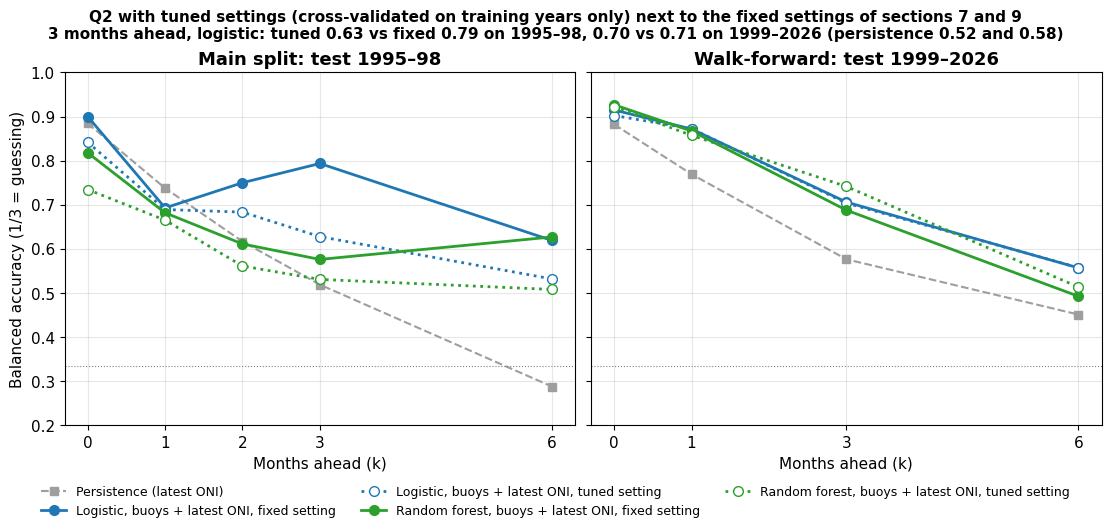

In [ ]:
# Chart 24: held-out balanced accuracy with the fixed and the tuned settings
EVALS = {"main_split": f"Main split: test {CUT + 1}–98", "walk_forward": f"Walk-forward: test {EXT_YEARS[0]}–{EXT_YEARS[-1]}"}
ba = tuned_test.set_index(["evaluation", "k", "model", "setting"])["balanced_accuracy"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True, layout="constrained")
for ax, (ev, title) in zip(axes, EVALS.items()):
    d = tuned_test[tuned_test["evaluation"] == ev]
    p = d[d["model"] == "persistence"].set_index("k")["balanced_accuracy"]
    ax.plot(p.index, p, color=MODEL_COLORS[PERSIST], ls="--", marker="s", lw=1.5, label=PERSIST)
    for kind in GRIDS:
        for setting_, ls, face in [("fixed", "-", None), ("tuned", ":", "white")]:
            s = d[(d["model"] == kind) & (d["setting"] == setting_)].set_index("k")["balanced_accuracy"]
            ax.plot(s.index, s, color=MODEL_COLORS[KIND_NAMES[kind]], ls=ls, lw=2, marker="o", ms=7, mfc=face,
                    label=f"{KIND_NAMES[kind]}, {setting_} setting")
    ax.axhline(1 / 3, color="gray", lw=.8, ls=":")
    ax.set(title=title, xticks=sorted(d["k"].unique()), xlabel="Months ahead (k)", ylim=(0.2, 1))
    ax.grid(alpha=.3)
axes[0].set_ylabel("Balanced accuracy (1/3 = guessing)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=9, frameon=False)
fig.suptitle("Q2 with tuned settings (cross-validated on training years only) next to the fixed settings of sections 7 and 9\n"
             f"3 months ahead, logistic: tuned {ba[('main_split', 3, 'logistic', 'tuned')]:.2f} vs fixed "
             f"{ba[('main_split', 3, 'logistic', 'fixed')]:.2f} on {CUT + 1}–98, {ba[('walk_forward', 3, 'logistic', 'tuned')]:.2f} vs "
             f"{ba[('walk_forward', 3, 'logistic', 'fixed')]:.2f} on {EXT_YEARS[0]}–{EXT_YEARS[-1]} (persistence "
             f"{ba[('main_split', 3, 'persistence', 'baseline')]:.2f} and {ba[('walk_forward', 3, 'persistence', 'baseline')]:.2f})",
             fontsize=11, fontweight="bold")
save(fig, "24_q2_tuning.png")

In [ ]:
# Reading section 11 (written from the numbers above)
def versus(ev, kind):
    """'k=0 0.84 vs 0.90, ...': tuned vs fixed balanced accuracy for every horizon of one test."""
    return ", ".join(f"k={k} {ba[(ev, k, kind, 'tuned')]:.2f} vs {ba[(ev, k, kind, 'fixed')]:.2f}"
                     for k in sorted(tuned_test.loc[tuned_test["evaluation"] == ev, "k"].unique()))


def tally(ev, kind):
    ks = sorted(tuned_test.loc[tuned_test["evaluation"] == ev, "k"].unique())
    diff = [round(ba[(ev, k, kind, "tuned")], 2) - round(ba[(ev, k, kind, "fixed")], 2) for k in ks]
    return (f"better at {sum(d > 0.005 for d in diff)}, equal at {sum(abs(d) <= 0.005 for d in diff)} and worse at "
            f"{sum(d < -0.005 for d in diff)} of {len(ks)} horizons")


folds_ms = cv_info[("main_split", 3)]["train_months_by_fold"]
best_c = {run: ", ".join(f"k={k}: {best_params[(run, k, 'logistic')]['C']:g}" for k in cfg["horizons"])
          for run, cfg in TUNING_RUNS.items()}
cv3 = cv_tables[("main_split", 3, "logistic")]["cv_balanced_accuracy"]
pairs = [(ev, k, kind) for ev, k in tuned_test[["evaluation", "k"]].drop_duplicates().to_numpy() for kind in GRIDS]
n_better = sum(round(ba[(ev, k, kind, "tuned")], 2) > round(ba[(ev, k, kind, "fixed")], 2) for ev, k, kind in pairs)
beat = ("did not beat the fixed settings on held-out years" if n_better == 0 else
        f"did not consistently beat the fixed settings on held-out years (tuned better in only {n_better} of {len(pairs)} "
        "model–horizon comparisons)")
display(Markdown(f"""**Reading section 11.**
* *Main split.* The training period is short: the seven folds train on {min(folds_ms.values())}–{max(folds_ms.values())} months
  (k = 3), and the earliest folds have almost no La Niña months to learn from. Cross-validated scores are therefore low and noisy
  (logistic, k = 3: {cv3.min():.2f}–{cv3.max():.2f} across C). The chosen C ({best_c['main_split']}) scores
  {tally('main_split', 'logistic')} on the 1995–98 test ({versus('main_split', 'logistic')}, tuned vs fixed); the tuned forest is
  {tally('main_split', 'random_forest')}.
* *Walk-forward.* Tuned on the first window (C: {best_c['walk_forward']}), the logistic model is {tally('walk_forward', 'logistic')}
  on {EXT_YEARS[0]}–{EXT_YEARS[-1]} ({versus('walk_forward', 'logistic')}). The tuned forest is {tally('walk_forward', 'random_forest')}
  ({versus('walk_forward', 'random_forest')}).
* *Latest window* (Jan {EXT_YEARS[-1] - CLIM_YEARS} on): C {best_c['latest_window']}.
* The cross-validated choice varied across windows and {beat}, so the final models keep the fixed settings used in the report
  (sections 7 and 9, `summary.json`); section 12 saves those."""))

**Reading section 11.**
* *Main split.* The training period is short: the seven folds train on 26–98 months
  (k = 3), and the earliest folds have almost no La Niña months to learn from. Cross-validated scores are therefore low and noisy
  (logistic, k = 3: 0.29–0.42 across C). The chosen C (k=0: 10, k=1: 0.1, k=2: 0.01, k=3: 0.03, k=6: 0.03) scores
  better at 0, equal at 1 and worse at 4 of 5 horizons on the 1995–98 test (k=0 0.84 vs 0.90, k=1 0.69 vs 0.69, k=2 0.68 vs 0.75, k=3 0.63 vs 0.79, k=6 0.53 vs 0.62, tuned vs fixed); the tuned forest is
  better at 0, equal at 0 and worse at 5 of 5 horizons.
* *Walk-forward.* Tuned on the first window (C: k=0: 0.1, k=1: 10, k=3: 3, k=6: 10), the logistic model is better at 0, equal at 2 and worse at 2 of 4 horizons
  on 1999–2026 (k=0 0.90 vs 0.91, k=1 0.87 vs 0.87, k=3 0.70 vs 0.71, k=6 0.56 vs 0.56). The tuned forest is better at 2, equal at 0 and worse at 2 of 4 horizons
  (k=0 0.92 vs 0.93, k=1 0.86 vs 0.87, k=3 0.74 vs 0.69, k=6 0.51 vs 0.49).
* *Latest window* (Jan 1996 on): C k=0: 0.1, k=1: 0.1, k=3: 10, k=6: 10.
* The cross-validated choice varied across windows and did not consistently beat the fixed settings on held-out years (tuned better in only 2 of 18 model–horizon comparisons), so the final models keep the fixed settings used in the report
  (sections 7 and 9, `summary.json`); section 12 saves those.

## 12. Export for the Streamlit app
The app only loads what this section saves; it never fits a model. Everything goes into `app_export/`, whose `models/` and `data/`
folders are copied unchanged into the app repository.

* `models/logistic_k{0,1,3,6}.joblib` and `models/random_forest_k{0,1,3,6}.joblib`: one scikit-learn pipeline per horizon with the
  **fixed settings of the report** (C = 1; 500 trees, at least 3 months per leaf), fitted exactly like the models behind the
  section 9.6 outlook: issue months in the 30 years before the last test year, anomalies against the same 30 years (1996–2025).
  The cell checks that the saved logistic models reproduce the 9.6 outlook.
* `models/metadata.json`: feature names and order, class order, horizons, training window, the tuning results of section 11
  (best settings, full cross-validation tables, held-out test scores) and the package versions used to save the models.
* `data/`: small tables for the charts (monthly model inputs, buoys reporting per month, ONI and RONI since 1950, LA rain seasons,
  test scores) and a copy of `summary.json`. No raw buoy files.

In [ ]:
# 12.1 Final models: the fixed settings of sections 7 and 9, fitted exactly like the models behind the 9.6 outlook
# (issue months in the 30 years before the last test year, targets inside that window, anomalies vs the same 30 years)
import platform
import shutil

import joblib
import scipy
import sklearn

APP = Path("app_export")
for sub in ["models", "data"]:
    (APP / sub).mkdir(parents=True, exist_ok=True)

LIVE_YEAR = EXT_YEARS[-1]
LIVE_FEATS = ext_feats[LIVE_YEAR]                        # anomalies vs the 30 years before LIVE_YEAR
LIVE_END = year_end(LIVE_YEAR - 1)
LIVE_START = LIVE_END - pd.DateOffset(years=CLIM_YEARS)
live_models, live_meta = {}, {}
for k in EXT_K:
    train, _ = split_rows(build_rows(LIVE_FEATS, k), LIVE_END)
    train = train[train.index > LIVE_START]              # the training rows of the last walk-forward year (9.5)
    live_meta[f"k{k}"] = {"train_months": len(train), "first_issue_month": f"{train.index.min():%Y-%m}",
                          "last_issue_month": f"{train.index.max():%Y-%m}", "last_target_month": f"{train['target_month'].max():%Y-%m}",
                          "months_by_phase": train["target"].value_counts().reindex(PHASES).astype(int).to_dict(), "models": {}}
    for kind in GRIDS:
        model = make_model(kind, FIXED[kind]).fit(train[Q2_COLS], train["target"])
        path = APP / "models" / f"{kind}_k{k}.joblib"
        joblib.dump(model, path, compress=3)
        live_models[(k, kind)] = model
        live_meta[f"k{k}"]["models"][kind] = {"file": f"models/{path.name}", "params": FIXED[kind]}

# The latest full month of buoy data through the saved models; the logistic ones must reproduce the 9.6 outlook exactly
latest = LIVE_FEATS.loc[[LAST_FULL_MONTH]].assign(oni_lag1=oni_by_month["oni"].get(LAST_FULL_MONTH - pd.DateOffset(months=1)))
latest_pred = {f"k{k}": {kind: {"target_month": f"{LAST_FULL_MONTH + pd.DateOffset(months=k):%Y-%m}",
                                **dict(zip(live_models[(k, kind)].classes_, live_models[(k, kind)].predict_proba(latest[Q2_COLS])[0]))}
                         for kind in GRIDS} for k in EXT_K}
for _, r in outlook[outlook["model"] == KIND_NAMES["logistic"]].iterrows():
    assert np.allclose([latest_pred[f"k{r['k']}"]["logistic"][p] for p in PHASES], [r[f"P({p})"] for p in PHASES], rtol=0, atol=1e-12)
pd.DataFrame({(k, kind): v for k, d in latest_pred.items() for kind, v in d.items()}).T.round(3)

target_month   El Niño   La Niña   Neutral
k0 logistic           2026-10       1.0       0.0       0.0
   random_forest      2026-10       1.0       0.0       0.0
k1 logistic           2026-11       1.0       0.0       0.0
   random_forest      2026-11       1.0       0.0       0.0
k3 logistic           2027-01  0.999992       0.0  0.000008
   random_forest      2027-01  0.981418       0.0  0.018582
k6 logistic           2027-04  0.984989  0.000022  0.014988
   random_forest      2027-04  0.639193  0.048946  0.311861

In [ ]:
# 12.2 Small data files for the app's charts and inputs, plus a copy of summary.json (section 10, unchanged)
# Model inputs for every issue month with >= 5 buoys, against the saved models' climatology; phase = ONI phase of that month
feat_tbl = build_rows(LIVE_FEATS, 0)[Q2_COLS + ["n_sites", "target"]].rename(columns={"target": "phase"})
feat_tbl["n_sites"] = feat_tbl["n_sites"].astype(int)
feat_tbl["in_live_window"] = feat_tbl.index > LIVE_START             # issue month inside the saved models' 30-year window
feat_tbl.index = feat_tbl.index.strftime("%Y-%m").rename("issue_month")
feat_tbl.to_csv(APP / "data" / "model_inputs_monthly.csv", float_format="%.4f")

# Buoys reporting SST per month and the Niño 3.4-box buoy SST anomaly next to ONI (chart 21)
buoy_tbl = pd.DataFrame({"source": np.where(EXT_CAL >= "1998-07-01", "NOAA PMEL GTMBA", "UCI"), "sst_buoys": sst_sites.to_numpy(),
                         "nino34_buoy_sst_anom": n34.to_numpy(), "oni": oni_m.to_numpy()}, index=EXT_CAL.strftime("%Y-%m").rename("month"))
buoy_tbl.to_csv(APP / "data" / "buoys_monthly.csv", float_format="%.3f")

# ONI and RONI by month since 1950 (centre month of each 3-month season)
oni_tbl = oni[["ym", "SEAS", "oni", "phase"]].merge(
    roni.assign(ym=pd.to_datetime(dict(year=roni["YR"], month=roni["SEAS"].map(season_center), day=1)))[["ym", "ANOM"]]
    .rename(columns={"ANOM": "roni"}), on="ym", how="left", validate="one_to_one")
oni_tbl.assign(ym=oni_tbl["ym"].dt.strftime("%Y-%m")).rename(columns={"ym": "month", "SEAS": "season"}).to_csv(
    APP / "data" / "oni_monthly.csv", index=False, float_format="%.2f")

# Los Angeles Downtown rain seasons 1950-2025 with the fall (Aug-Oct) ONI and RONI (sections 5 and 8)
seasons[["season", "aso_oni", "aso_roni", "phase", "inches", "heavy", "wet"]].to_csv(
    APP / "data" / "la_rain_seasons.csv", index=False, float_format="%.3f")

# Held-out test scores of every model and setting (11.3)
tuned_test.drop(columns="params").to_csv(APP / "data" / "q2_test_scores.csv", index=False, float_format="%.4f")
shutil.copy("summary.json", APP / "data" / "summary.json")
feat_tbl.tail(4)

,sst_n34,sst_all,air_all,zw_all,zw_west,mw_all,d_sst_n34,d_zw_west,oni_lag1,n_sites,phase,in_live_window
issue_month,,,,,,,,,,,,
2026-07,2.106370,1.692245,1.538732,2.280850,5.161788,0.511842,0.481654,0.259024,1.39,46,El Niño,True
2026-08,2.601901,2.014471,1.890628,2.348207,5.093256,0.458298,0.495530,-0.068532,1.80,47,El Niño,True
2026-09,2.747290,2.052859,2.006044,3.240653,6.105886,0.092662,0.145389,1.012630,2.16,47,El Niño,True
2026-10,3.141199,2.299309,2.181224,3.062897,5.602742,-0.026936,0.393909,-0.503143,2.46,46,NaN,True


In [ ]:
# 12.3 models/metadata.json: everything the app needs to use the saved models without refitting anything
UNITS = {"sst_n34": "°C", "sst_all": "°C", "air_all": "°C", "zw_all": "m/s", "zw_west": "m/s", "mw_all": "m/s",
         "d_sst_n34": "°C", "d_zw_west": "m/s", "oni_lag1": "°C"}
LABELS = {**FEATURES, **LATEST_ONI}
metadata = {
    "project": "BANA 212 Team 6: El Niño in the TAO buoy record, NOAA's ONI and Los Angeles winter rain",
    "notebook": "elnino_analysis_v4.ipynb, sections 11-12; sections 1-10 are the results frozen on 2026-11-22 (data/summary.json)",
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__},
    "target": "ONI phase of month t+k: El Niño if ONI >= +0.5, La Niña if ONI <= -0.5, otherwise Neutral",
    "classes": PHASES,
    "model_class_order": list(live_models[(EXT_K[0], "logistic")].classes_),
    "features": [{"name": c, "label": LABELS[c], "unit": UNITS[c]} for c in Q2_COLS],
    "horizons": EXT_K,
    "model_names": {"persistence": PERSIST, **KIND_NAMES},
    "live_models": {
        "settings": "fixed settings of sections 7 and 9 (the frozen results); the tuning in section 11 is reported only",
        "params": FIXED,
        "setup": "forecast issued at the start of month t+1 from the buoy anomalies of month t and the latest ONI (month t-1); "
                 f"anomalies vs each buoy's calendar-month mean over {LIVE_YEAR - CLIM_YEARS}-{LIVE_YEAR - 1}",
        "training_window": f"issue months {LIVE_START + pd.DateOffset(days=1):%Y-%m} to {LIVE_END:%Y-%m} with targets up to "
                           f"{LIVE_END:%Y-%m}, months with >= 5 buoys: the last walk-forward year's training data (section 9.5), "
                           "so the logistic models reproduce the section 9.6 outlook",
        "latest_issue_month": f"{LAST_FULL_MONTH:%Y-%m}",
        "latest_inputs": latest[Q2_COLS].iloc[0].to_dict(),
        "latest_prediction": latest_pred,
        "by_horizon": live_meta,
    },
    "tuning": {
        "grids": GRIDS, "fixed": FIXED,
        "scoring": "balanced accuracy over all validation months pooled across expanding-window folds by year",
        "tie_break": "first best setting in grid order: smaller C; fewer, shallower trees with larger leaves",
        "conclusion": f"The cross-validated choice varied across windows and {beat}, so the final models keep the fixed "
                      "settings used in the report.",
        "runs": {run: {"label": cfg["label"], "validation_years": list(cfg["val_years"]),
                       "last_target_month": f"{cfg['last_target']:%Y-%m}",
                       "best": {f"k{k}": {kind: best_params[(run, k, kind)] for kind in GRIDS} for k in cfg["horizons"]},
                       "folds": {f"k{k}": cv_info[(run, k)] for k in cfg["horizons"]},
                       "cv": {f"k{k}": {kind: cv_tables[(run, k, kind)].to_dict(orient="records") for kind in GRIDS}
                              for k in cfg["horizons"]}}
                 for run, cfg in TUNING_RUNS.items()},
    },
    "test_scores": {"evaluations": {"main_split": f"train issue months <= {CUT}, test Jan {CUT + 1} - Jun 1998",
                                    "walk_forward": f"each test year {EXT_YEARS[0]}-{EXT_YEARS[-1]} refitted on the {CLIM_YEARS} years "
                                                    "before it; tuned setting from the first window"},
                    "rows": tuned_test.to_dict(orient="records")},
}
(APP / "models" / "metadata.json").write_text(json.dumps(to_builtin(metadata), indent=2, ensure_ascii=False), encoding="utf-8")
pd.DataFrame([(str(p.relative_to(APP)), f"{p.stat().st_size / 1e3:,.1f} kB") for p in sorted(APP.rglob("*")) if p.is_file()],
             columns=["file", "size"])

,file,size
0,data/buoys_monthly.csv,19.3 kB
1,data/la_rain_seasons.csv,3.1 kB
2,data/model_inputs_monthly.csv,45.6 kB
3,data/oni_monthly.csv,29.1 kB
4,data/q2_test_scores.csv,3.9 kB
5,data/summary.json,49.9 kB
6,models/logistic_k0.joblib,1.6 kB
7,models/logistic_k1.joblib,1.6 kB
8,models/logistic_k3.joblib,1.7 kB
9,models/logistic_k6.joblib,1.7 kB


## <mark style="background-color:#FFC891">13. Flood risk: thresholds, warnings and storms</mark>
<mark style="background-color:#FFC891">Section 8 showed that an El Niño fall raises the odds of a wet winter in Los Angeles. Flood preparation needs more
concrete numbers: how many flood-producing storms to plan for, whether the official flood warnings that crews and residents
act on also become more frequent, and whether the rain comes harder within a single hour. This section answers four
questions:</mark>

* <mark style="background-color:#FFC891">**13.1 Thresholds and risk tiers.** After a La Niña, neutral, moderate El Niño or strong El Niño fall, how often
  does a season bring 2, 3 or 6 heavy-rain days, or a major storm? Above which fall ONI does a storm-heavy season become
  more likely than not?</mark>
* <mark style="background-color:#FFC891">**13.2 Flood warnings.** Do El Niño winters bring more National Weather Service (NWS) flood warnings for Los
  Angeles County?</mark>
* <mark style="background-color:#FFC891">**13.3 Storm intensity.** Do El Niño winters bring more hours of very intense rain?</mark>
* <mark style="background-color:#FFC891">**13.4 Winter 2026–27.** What these numbers mean for this winter.</mark>

<mark style="background-color:#FFC891">**Terms** (seasons, the fall ONI and the Wilson interval are as in sections 5 and 8):</mark>
* <mark style="background-color:#FFC891">*Heavy-rain day*: at least 1.00 in of rain at Downtown LA (USC) in one day. *Very heavy day*: at least 2.00 in.</mark>
* <mark style="background-color:#FFC891">*Storm*: a run of consecutive days that each get at least 0.10 in; its total is the rain over the whole run.
  A *major storm* totals at least 3.00 in; we also count storms of at least 2.00 in. *Max 3-day total*: the season's
  wettest three days in a row, a measure of how much water can pile up before the ground drains.</mark>
* <mark style="background-color:#FFC891">*Risk tier*: the fall (Aug–Oct) ONI group used in 8.2: La Niña (≤ −0.5), Neutral, Moderate El Niño
  (0.5 to 1.49) and Strong El Niño (≥ 1.5).</mark>
* <mark style="background-color:#FFC891">*Logistic regression*: a model for a yes/no outcome. Here it turns the fall ONI into the probability of a
  storm-heavy season along an S-shaped curve. *Season bootstrap*: we refit the model on 2,000 random redraws of the
  seasons (drawn with replacement) and keep the middle 95 % of the results as the interval.</mark>
* <mark style="background-color:#FFC891">*Flash Flood Warning*: flash flooding is happening or about to happen, usually from intense rain in a few
  hours. *Flood Warning*: slower flooding over an area or along a river. *Flood Advisory*: minor flooding, such as ponded roads
  and rising small streams. NWS codes: FF.W, FA.W (area) and FL.W (river) for the warnings, FA.Y for the advisory.</mark>
* <mark style="background-color:#FFC891">*Intense hour*: at least 0.50 in of rain in one hour. This is the usual Southern California rule of thumb
  for when slopes burned by wildfires start to send down debris flows (fast-moving mud and rock).</mark>

<mark style="background-color:#FFC891">**New data** (both from the Iowa Environmental Mesonet, IEM, which archives NWS products and weather-station
reports; cached in `data/raw/` like the other files):</mark>
* <mark style="background-color:#FFC891">every NWS warning and advisory issued for Los Angeles County (county code CAC037) since 1995, one JSON file;</mark>
* <mark style="background-color:#FFC891">the hourly reports of the Downtown USC weather station (call sign CQT, the same site as the daily record),
  one file per year. IEM refuses requests that come too fast, so the cell pauses 6 seconds between files; a fresh
  Colab run spends about 3 minutes on these downloads.</mark>

### <mark style="background-color:#FFC891">13.1 Thresholds and risk tiers (daily rain, the 76 seasons 1950–2025)</mark>
<mark style="background-color:#FFC891">The first cell builds one row per season: heavy and very heavy days, the number of storms, storms of at least 2 and
3 in, and the largest storm and 3-day totals. The second cell gives, for each fall tier, the share of seasons that reached
each level, with a 95 % Wilson interval.</mark>

<mark style="background-color:#FFC891">Three heavy-rain days is not a high bar in Los Angeles: 46 of the 76 seasons (61 %) had at least 3, whatever the
fall. There is therefore no fall ONI at which "at least 3 heavy days" tips from unlikely to likely; it is likely already.
For the threshold we use a **storm-heavy season**, one with at least 6 heavy-rain days (23 of 76 seasons, 30 %), fit the
logistic curve on the fall ONI, and read off the ONI at which the curve crosses 50 %. The curve for "at least 3" is kept as
a comparison. Finally the threshold is restated in buoy units: a straight line fitted between the Aug–Oct ONI and the
Aug–Oct mean of the Niño 3.4-box buoy SST anomaly (the section 9 series in chart 21) converts it to °C as the buoys
measure it.</mark>

In [ ]:
# 13.1 Storm measures per season from the daily record (same station, quality rule and 76 seasons as sections 5 and 8)
MM_PER_IN = 25.4
to_season = lambda dates: np.where(dates.month >= 7, dates.year, dates.year - 1)    # Jul-Jun season named by its start year

# Full calendar, so that a missing date ends a storm instead of joining two wet spells
rain_day = la.set_index("DATE")["mm"]
rain_day = rain_day.reindex(pd.date_range(rain_day.index.min(), rain_day.index.max(), freq="D"))

# Storm = run of consecutive days with >= 0.10 in; it belongs to the season of its first day
rainy = (rain_day >= 0.10 * MM_PER_IN).to_numpy()
storm_no = np.cumsum(rainy & ~np.r_[False, rainy[:-1]]) * rainy
storm_runs = (pd.DataFrame({"date": rain_day.index, "mm": rain_day.to_numpy(), "storm": storm_no})
              .query("storm > 0")
              .groupby("storm")
              .agg(start=("date", "min"), end=("date", "max"), days=("date", "size"), mm=("mm", "sum")))
storm_runs["inches"] = storm_runs["mm"] / MM_PER_IN
storm_runs["season"] = to_season(storm_runs["start"].dt)

# Wettest 3 days in a row, by the season of the window's last day (missing days count as 0)
max_3day = (rain_day.fillna(0).rolling(3, min_periods=1).sum() / MM_PER_IN).groupby(to_season(rain_day.index)).max()

flood_seasons = seasons.set_index("season")[["aso_oni", "phase", "strength_oni", "inches", "heavy"]].copy()
fs_idx = flood_seasons.index
flood_seasons["very_heavy"] = la[la["mm"] >= 2 * MM_PER_IN].groupby("season").size().reindex(fs_idx, fill_value=0)
flood_seasons["storms"] = storm_runs.groupby("season").size().reindex(fs_idx, fill_value=0)
flood_seasons["storms_2in"] = storm_runs[storm_runs["inches"] >= 2].groupby("season").size().reindex(fs_idx, fill_value=0)
flood_seasons["major_storms"] = storm_runs[storm_runs["inches"] >= 3].groupby("season").size().reindex(fs_idx, fill_value=0)
flood_seasons["max_storm_in"] = storm_runs.groupby("season")["inches"].max().reindex(fs_idx)
flood_seasons["max_3day_in"] = max_3day.reindex(fs_idx)
assert len(flood_seasons) == 76 and flood_seasons.notna().all().all()

biggest = storm_runs[storm_runs["season"].isin(fs_idx)].nlargest(3, "inches")
print(f"{len(flood_seasons)} seasons {fs_idx.min()}–{fs_idx.max()}: {int(flood_seasons['storms'].sum())} storms, "
      f"{int(flood_seasons['major_storms'].sum())} major storms (>= 3 in), {int(flood_seasons['very_heavy'].sum())} very heavy days (>= 2 in)")
print("largest storms:", "; ".join(f"{r.start:%d %b %Y}, {r.days} days, {r.inches:.2f} in" for r in biggest.itertuples()))
flood_seasons.drop(columns=["phase"]).describe().loc[["mean", "50%", "max"]].round(2)

76 seasons 1950–2025: 1019 storms, 71 major storms (>= 3 in), 77 very heavy days (>= 2 in)
largest storms: 13 Feb 1980, 9 days, 12.76 in; 03 Feb 2024, 5 days, 9.03 in; 17 Feb 2005, 7 days, 8.71 in


,aso_oni,inches,heavy,very_heavy,storms,storms_2in,major_storms,max_storm_in,max_3day_in
mean,0.02,14.46,4.26,1.01,13.41,1.92,0.93,3.76,3.36
50%,-0.14,12.41,4.00,1.00,13.00,2.00,0.50,2.96,2.88
max,2.04,37.26,14.00,5.00,27.00,6.00,4.00,12.76,8.51


In [ ]:
# 13.1 Risk tiers by the fall (Aug-Oct) ONI: share of seasons reaching each level, with 95 % Wilson intervals (wilson() from 8.1)
TIER_EVENTS = {   # key: (column, minimum, label)
    "heavy2": ("heavy", 2, "≥ 2 heavy-rain days"),
    "heavy3": ("heavy", 3, "≥ 3 heavy-rain days"),
    "heavy6": ("heavy", 6, "≥ 6 heavy-rain days (storm-heavy season)"),
    "major_storm": ("major_storms", 1, "≥ 1 major storm (≥ 3 in)"),
}


def tier_row(g):
    """Seasons, mean storm measures and the share of seasons reaching each level (with a 95 % Wilson interval)."""
    row = {"n": len(g), "heavy_mean": g["heavy"].mean(), "very_heavy_mean": g["very_heavy"].mean(),
           "storms_2in_mean": g["storms_2in"].mean(), "major_storms_mean": g["major_storms"].mean(),
           "max_3day_median_in": g["max_3day_in"].median()}
    for key, (col, k, _) in TIER_EVENTS.items():
        hits = int((g[col] >= k).sum())
        lo, hi = wilson(hits, len(g))
        row.update({f"{key}_k": hits, key: hits / len(g), f"{key}_lo": lo, f"{key}_hi": hi})
    return pd.Series(row)


tier_tbl = pd.DataFrame({t: tier_row(flood_seasons[flood_seasons["strength_oni"] == t]) for t in STRENGTHS}).T
tier_tbl.loc["All seasons"] = tier_row(flood_seasons)
assert tier_tbl.loc[STRENGTHS, "n"].sum() == len(flood_seasons)
assert np.allclose(tier_tbl.loc[STRENGTHS, "heavy_mean"].to_numpy(dtype=float),
                   odds_by_index.loc["ONI"].loc[STRENGTHS, "heavy_mean"].to_numpy(dtype=float)), "should match 8.2"

show = tier_tbl[["n", "heavy_mean", "very_heavy_mean", "major_storms_mean", "max_3day_median_in"]].astype(float).round(2)
for key, (_, _, label) in TIER_EVENTS.items():
    show[label] = [f"{int(r[f'{key}_k'])}/{int(r['n'])} = {r[key]:.0%} [{r[f'{key}_lo']:.0%}–{r[f'{key}_hi']:.0%}]"
                   for _, r in tier_tbl.iterrows()]
show

,n,heavy_mean,very_heavy_mean,major_storms_mean,max_3day_median_in,≥ 2 heavy-rain days,≥ 3 heavy-rain days,≥ 6 heavy-rain days (storm-heavy season),≥ 1 major storm (≥ 3 in)
La Niña,18.0,3.11,0.78,0.83,3.59,13/18 = 72% [49%–88%],10/18 = 56% [34%–75%],1/18 = 6% [1%–26%],11/18 = 61% [39%–80%]
Neutral,38.0,4.05,0.95,0.92,2.71,29/38 = 76% [61%–87%],21/38 = 55% [40%–70%],12/38 = 32% [19%–47%],16/38 = 42% [28%–58%]
Moderate El Niño (0.5–1.49),16.0,5.44,1.19,0.94,2.83,14/16 = 88% [64%–97%],12/16 = 75% [51%–90%],7/16 = 44% [23%–67%],8/16 = 50% [28%–72%]
Strong El Niño (≥ 1.5),4.0,6.75,2.00,1.50,4.16,4/4 = 100% [51%–100%],3/4 = 75% [30%–95%],3/4 = 75% [30%–95%],3/4 = 75% [30%–95%]
All seasons,76.0,4.26,1.01,0.93,2.88,60/76 = 79% [69%–87%],46/76 = 61% [49%–71%],23/76 = 30% [21%–41%],38/76 = 50% [39%–61%]


In [ ]:
# 13.1 Threshold: logistic regression of "storm-heavy season" (>= 6 heavy-rain days) on the fall ONI, with a season bootstrap.
# The same curve for ">= 3 heavy-rain days" is kept as a comparison.
from sklearn.linear_model import LogisticRegression

STORMY_K = 6
ONI_NOW = round(float(aso_2026["aso_oni"]), 2)
ONI_POINTS = [0.0, 1.0, 1.5, 2.0, ONI_NOW]
ONI_GRID = np.linspace(-2.0, 3.0, 201)
N_BOOT = 2000
x_oni = flood_seasons[["aso_oni"]].to_numpy()
logistic = lambda a, b, x: 1 / (1 + np.exp(-(a + b * np.asarray(x))))


def logit_curve(k, seed=212):
    """Fit P(heavy days >= k) on the fall ONI, then refit on N_BOOT season resamples.

    The threshold is the ONI where the rising curve crosses 0.5. A resample whose slope is <= 0 has no such ONI
    (the curve never rises through 0.5); it is kept as +inf, so a large share of them makes the upper limit unbounded."""
    y = (flood_seasons["heavy"] >= k).astype(int).to_numpy()
    fit = lambda rows: LogisticRegression(penalty=None, max_iter=1000).fit(x_oni[rows], y[rows])
    m = fit(np.arange(len(y)))
    a, b = float(m.intercept_[0]), float(m.coef_[0, 0])
    rng = np.random.default_rng(seed)
    thr, slope, p_pts, p_grid = [], [], [], []
    while len(thr) < N_BOOT:
        rows = rng.integers(0, len(y), len(y))
        if y[rows].min() == y[rows].max():           # one class only: cannot fit, draw again
            continue
        mb = fit(rows)
        ab, bb = float(mb.intercept_[0]), float(mb.coef_[0, 0])
        slope.append(bb)
        thr.append(-ab / bb if bb > 0 else np.inf)
        p_pts.append(logistic(ab, bb, ONI_POINTS))
        p_grid.append(logistic(ab, bb, ONI_GRID))
    thr, p_pts, p_grid = np.array(thr), np.array(p_pts), np.array(p_grid)
    lo, hi = np.percentile(thr, [2.5, 97.5], method="inverted_cdf")
    return {"k": k, "seasons": len(y), "hits": int(y.sum()), "base_rate": y.mean(), "intercept": a, "slope": b,
            "oni_p50": -a / b if b > 0 else np.inf, "oni_p50_ci95": (lo, hi),
            "slope_not_positive_share": float(np.mean(np.array(slope) <= 0)),
            "p_at": {x: (float(logistic(a, b, x)), *np.percentile(p_pts[:, j], [2.5, 97.5])) for j, x in enumerate(ONI_POINTS)},
            "band": (np.percentile(p_grid, 2.5, axis=0), np.percentile(p_grid, 97.5, axis=0)), "y": y}


curve6, curve3 = logit_curve(STORMY_K), logit_curve(3)
fmt_oni = lambda v: f"{v:+.2f}" if np.isfinite(v) else ("not bounded" if v > 0 else "not bounded below")
for c in (curve6, curve3):
    print(f">= {c['k']} heavy days: {c['hits']}/{c['seasons']} seasons ({c['base_rate']:.0%}); slope {c['slope']:.2f} per °C; "
          f"P = 0.5 at ONI {fmt_oni(c['oni_p50'])} [95 % CI {fmt_oni(c['oni_p50_ci95'][0])} to {fmt_oni(c['oni_p50_ci95'][1])}]; "
          f"bootstrap slopes <= 0: {c['slope_not_positive_share']:.1%}")
    print("   P at ONI " + ", ".join(f"{x:+.2f}: {p:.2f} [{lo:.2f}–{hi:.2f}]" for x, (p, lo, hi) in c["p_at"].items()))

# Buoy equivalent: Aug-Oct mean of the monthly Niño 3.4-box buoy SST anomaly (n34, section 9, months with >= 3 box buoys)
buoy_aso = (n34.rename("buoy").to_frame().assign(year=EXT_CAL.year, month=EXT_CAL.month)
            .query("month in [8, 9, 10]").groupby("year")["buoy"].agg(["mean", "count"]))
buoy_aso = (buoy_aso[buoy_aso["count"] == 3].rename(columns={"mean": "buoy_aso"})
            .join(aso.set_index("season")["aso_oni"], how="inner"))
b_slope, b_icept = np.polyfit(buoy_aso["buoy_aso"], buoy_aso["aso_oni"], 1)       # ONI = b_icept + b_slope * buoy
b_r = buoy_aso["buoy_aso"].corr(buoy_aso["aso_oni"])
b_resid_sd = float(np.std(buoy_aso["aso_oni"] - (b_icept + b_slope * buoy_aso["buoy_aso"]), ddof=2))
to_buoy = lambda v: (v - b_icept) / b_slope if np.isfinite(v) else v
thr_buoy = to_buoy(curve6["oni_p50"])
thr_buoy_ci = tuple(to_buoy(v) for v in curve6["oni_p50_ci95"])
missing_years = sorted(set(range(buoy_aso.index.min(), buoy_aso.index.max() + 1)) - set(buoy_aso.index))
print(f"\nbuoy fit: {len(buoy_aso)} years {buoy_aso.index.min()}–{buoy_aso.index.max()} (no full Aug–Oct in {missing_years}); "
      f"ASO ONI = {b_icept:+.2f} + {b_slope:.2f} × buoy anomaly, r = {b_r:.3f}, residual SD {b_resid_sd:.2f} °C")
print(f"storm-heavy threshold ONI {curve6['oni_p50']:+.2f} ≈ buoy Aug–Oct anomaly {thr_buoy:+.2f} °C "
      f"[{fmt_oni(thr_buoy_ci[0])} to {fmt_oni(thr_buoy_ci[1])} °C]; Aug–Oct 2026 buoys: {buoy_aso['buoy_aso'].get(2026, np.nan):+.2f} °C")

>= 6 heavy days: 23/76 seasons (30%); slope 1.15 per °C; P = 0.5 at ONI +0.86 [95 % CI +0.35 to +2.00]; bootstrap slopes <= 0: 0.0%
   P at ONI +0.00: 0.27 [0.16–0.39], +1.00: 0.54 [0.35–0.75], +1.50: 0.68 [0.43–0.89], +2.00: 0.79 [0.50–0.96], +2.46: 0.86 [0.56–0.98]
>= 3 heavy days: 46/76 seasons (61%); slope 0.29 per °C; P = 0.5 at ONI -1.49 [95 % CI -17.34 to not bounded]; bootstrap slopes <= 0: 16.4%
   P at ONI +0.00: 0.61 [0.50–0.72], +1.00: 0.67 [0.50–0.82], +1.50: 0.70 [0.47–0.88], +2.00: 0.73 [0.44–0.92], +2.46: 0.76 [0.41–0.94]

buoy fit: 38 years 1988–2026 (no full Aug–Oct in [2014]); ASO ONI = +0.09 + 0.91 × buoy anomaly, r = 0.983, residual SD 0.17 °C
storm-heavy threshold ONI +0.86 ≈ buoy Aug–Oct anomaly +0.83 °C [+0.29 to +2.09 °C]; Aug–Oct 2026 buoys: +2.44 °C


saved charts/25_flood_tiers.png


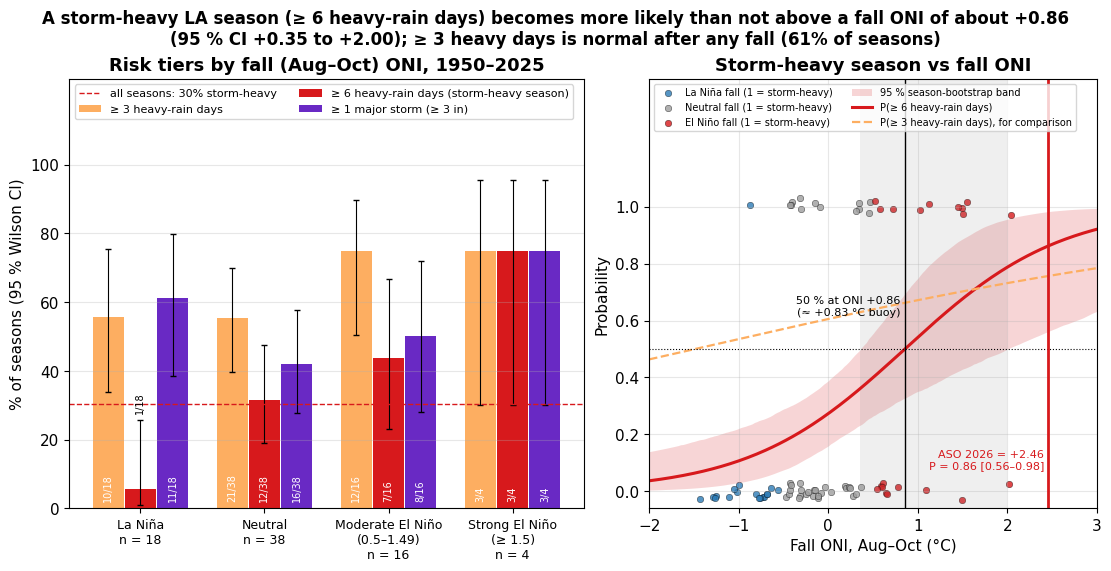

In [ ]:
# Chart 25: risk tiers (share of seasons reaching each level) and the storm-heavy threshold curve
TIER_COLORS = {"heavy3": "#fdae61", "heavy6": "#d7191c", "major_storm": "#6929c4"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
xs = np.arange(len(STRENGTHS))
for j, key in enumerate(["heavy3", "heavy6", "major_storm"]):
    t = tier_tbl.loc[STRENGTHS]
    x_ = xs + (j - 1) * 0.26
    ax.bar(x_, t[key] * 100, width=0.25, color=TIER_COLORS[key], label=TIER_EVENTS[key][2])
    ax.errorbar(x_, t[key] * 100, yerr=[(t[key] - t[f"{key}_lo"]) * 100, (t[f"{key}_hi"] - t[key]) * 100],
                fmt="none", ecolor="black", elinewidth=.8, capsize=2)
    for xi, (_, r) in zip(x_, t.iterrows()):
        inside = r[key] >= 0.15
        ax.text(xi, 2 if inside else r[f"{key}_hi"] * 100 + 2, f"{int(r[f'{key}_k'])}/{int(r['n'])}", ha="center", va="bottom",
                fontsize=7, rotation=90, color="white" if inside else "black")
ax.axhline(tier_tbl.loc["All seasons", "heavy6"] * 100, color=TIER_COLORS["heavy6"], ls="--", lw=1,
           label=f"all seasons: {tier_tbl.loc['All seasons', 'heavy6']:.0%} storm-heavy")
ax.set_xticks(xs, [f"{s.replace(' (', chr(10) + '(')}\nn = {int(tier_tbl.loc[s, 'n'])}" for s in STRENGTHS], fontsize=9)
ax.set(ylim=(0, 125), yticks=range(0, 101, 20), ylabel="% of seasons (95 % Wilson CI)", title="Risk tiers by fall (Aug–Oct) ONI, 1950–2025")
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(axis="y", alpha=.3)

ax = axes[1]
jitter = np.random.default_rng(212).uniform(-0.03, 0.03, len(flood_seasons))
for p in PHASES:
    m = (flood_seasons["phase"] == p).to_numpy()
    ax.scatter(flood_seasons["aso_oni"][m], curve6["y"][m] + jitter[m], color=PHASE_COLORS[p], s=22, edgecolor="black",
               linewidth=.3, alpha=.8, label=f"{p} fall (1 = storm-heavy)")
ax.fill_between(ONI_GRID, *curve6["band"], color=TIER_COLORS["heavy6"], alpha=.18, lw=0, label="95 % season-bootstrap band")
ax.plot(ONI_GRID, logistic(curve6["intercept"], curve6["slope"], ONI_GRID), color=TIER_COLORS["heavy6"], lw=2.2,
        label="P(≥ 6 heavy-rain days)")
ax.plot(ONI_GRID, logistic(curve3["intercept"], curve3["slope"], ONI_GRID), color=TIER_COLORS["heavy3"], lw=1.6, ls="--",
        label="P(≥ 3 heavy-rain days), for comparison")
ax.axhline(0.5, color="black", lw=.8, ls=":")
lo_, hi_ = curve6["oni_p50_ci95"]
ax.axvspan(max(lo_, ONI_GRID[0]), min(hi_, ONI_GRID[-1]), color="gray", alpha=.12, lw=0)
ax.axvline(curve6["oni_p50"], color="black", lw=1)
ax.text(curve6["oni_p50"] - 0.05, 0.62, f"50 % at ONI {curve6['oni_p50']:+.2f}\n(≈ {thr_buoy:+.2f} °C buoy)", ha="right", fontsize=8)
p_now = curve6["p_at"][ONI_NOW]
ax.axvline(ONI_NOW, color="#d7191c", lw=2)
ax.text(ONI_NOW - 0.05, 0.08, f"ASO 2026 = {ONI_NOW:+.2f}\nP = {p_now[0]:.2f} [{p_now[1]:.2f}–{p_now[2]:.2f}]", ha="right",
        fontsize=8, color="#d7191c")
ax.set(xlim=(ONI_GRID[0], ONI_GRID[-1]), ylim=(-0.06, 1.45), yticks=np.arange(0, 1.01, 0.2), xlabel="Fall ONI, Aug–Oct (°C)",
       ylabel="Probability", title="Storm-heavy season vs fall ONI")
ax.legend(loc="upper left", fontsize=7, ncol=2)
ax.grid(alpha=.3)
fig.suptitle(f"A storm-heavy LA season (≥ 6 heavy-rain days) becomes more likely than not above a fall ONI of about "
             f"{curve6['oni_p50']:+.2f}\n(95 % CI {fmt_oni(lo_)} to {fmt_oni(hi_)}); ≥ 3 heavy days is normal after any fall "
             f"({curve3['base_rate']:.0%} of seasons)", fontsize=12, fontweight="bold")
save(fig, "25_flood_tiers.png")

### <mark style="background-color:#FFC891">13.2 NWS flood warnings for Los Angeles County</mark>
<mark style="background-color:#FFC891">Rain at one gauge is not the same as flooding across the county, so we also count the flood warnings the NWS
Los Angeles/Oxnard office actually issued. A *flood-warning day* is a local calendar date (Pacific time) on which at least
one Flash Flood Warning or Flood Warning (FF.W, FA.W or FL.W) was in effect for Los Angeles County, from issue to expiry.
We also count Flash Flood Warnings (each warning once) and *advisory days* (days with a Flood Advisory in effect; the first
Flood Advisory for the county in the archive is from October 2009).</mark>

<mark style="background-color:#FFC891">**Which days count.** The headline count uses Oct–Apr, the months when Pacific storms arrive (the same window as
the coverage rule in 5.1). Over a full Jul–Jun season more than a third of the county's warning days fall in May–Sep,
mostly summer thunderstorms over the mountains and deserts or tropical storm remnants such as Hilary in August 2023; these have
little to do with El Niño, and most of them come before the Aug–Oct ONI is published. The full-season count is kept as a
second column.</mark>

<mark style="background-color:#FFC891">**Which seasons count.** IEM's archive of Flash Flood Warnings is complete only from about 2002. The headline
comparison therefore uses the 24 seasons 2002–03 to 2025–26; 1995–96 to 2001–02 stay in the table, flagged as a partial
archive, and enter only a sensitivity check.</mark>

<mark style="background-color:#FFC891">**What else drives the counts.** Warnings depend on more than rain:</mark>
* <mark style="background-color:#FFC891">*Burn scars*: after a large wildfire the NWS warns for much smaller storms, because burned slopes shed water
  and debris fast. Flagged seasons: 2009–10 (Station Fire, Aug 2009), 2020–21 (Bobcat Fire, Sep 2020), 2024–25 and 2025–26
  (Palisades and Eaton fires, Jan 2025).</mark>
* <mark style="background-color:#FFC891">*Warning practice*: the NWS moved from whole-county warnings to storm-based polygons in late 2007, and Flood
  Advisories exist only from 2009, so some minor events that used to get a warning now get an advisory.</mark>

In [ ]:
# 13.2 Download (or read from the cache) every NWS warning and advisory for Los Angeles County (CAC037) since 1995
import datetime as dt
import time
import urllib.error

IEM = "https://mesonet.agron.iastate.edu"
IEM_PAUSE_S = 6                                    # IEM answers "Too many requests" when calls come faster than this
TZ_LA = "America/Los_Angeles"


def iem_get(url, tries=6):
    """One IEM request with a pause before it and longer pauses between retries."""
    last = None
    for attempt in range(tries):
        time.sleep(IEM_PAUSE_S + 10 * attempt)
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "BANA212-elnino/1.0"})
            with urllib.request.urlopen(req, timeout=180) as resp:
                body = resp.read()
            if b"Too many requests" in body[:300]:
                raise ValueError("Too many requests")
            return body
        except (urllib.error.URLError, TimeoutError, ConnectionError, ValueError, OSError) as err:
            last = err
            print(f"  retry {attempt + 1}/{tries}: {err}")
    raise RuntimeError(f"IEM download failed after {tries} tries: {url}\n{last}")


VTEC_FILE = RAW / "iem_vtec_events_CAC037.json"
if not os.path.exists(VTEC_FILE):
    vtec_url = f"{IEM}/json/vtec_events_byugc.php?ugc=CAC037&sdate=1995-01-01&edate={dt.date.today():%Y-%m-%d}"
    print("downloading", vtec_url)
    body = iem_get(vtec_url)
    json.loads(body)["events"]                       # fail here, not later, if the answer is not the expected JSON
    VTEC_FILE.write_bytes(body)
vtec = json.loads(VTEC_FILE.read_text(encoding="utf-8"))
vtec_through = pd.Timestamp(vtec["generated_at"]).tz_convert(TZ_LA).tz_localize(None)

warn_ev = pd.DataFrame(vtec["events"]).drop_duplicates("url")      # url = office + year + code + event number
warn_ev["code"] = warn_ev["phenomena"] + "." + warn_ev["significance"]
for c in ["issue", "expire"]:
    warn_ev[c] = pd.to_datetime(warn_ev[c], utc=True).dt.tz_convert(TZ_LA).dt.tz_localize(None)   # local clock time
print(f"{len(warn_ev)} events for Los Angeles County, {warn_ev['issue'].min():%Y-%m-%d} to {warn_ev['issue'].max():%Y-%m-%d} "
      f"(file made {vtec_through:%Y-%m-%d %H:%M} Pacific time), offices {sorted(warn_ev['wfo'].unique())}")
print(warn_ev.groupby(["code", "name"]).agg(events=("url", "size"), first=("issue", "min"), last=("issue", "max"))
      .assign(first=lambda t: t["first"].dt.date, last=lambda t: t["last"].dt.date).to_string())

1004 events for Los Angeles County, 1995-01-07 to 2026-11-19 (file made 2026-11-23 12:39 Pacific time), offices ['LOX']
                                  events       first        last
code name                                                       
FA.W Flood Warning                     4  2023-01-09  2025-12-24
FA.Y Flood Advisory                  452  2009-10-13  2026-11-19
FF.W Flash Flood Warning             388  1995-01-07  2026-11-19
SV.A Severe Thunderstorm Watch         2  2008-01-27  2025-10-13
SV.W Severe Thunderstorm Warning     137  1995-02-10  2026-11-19
TO.W Tornado Warning                  21  1997-07-21  2025-12-24


In [ ]:
# 13.2 Flood-warning days per season, and El Niño falls vs other falls
from scipy.stats import spearmanr

WARN_CODES = ["FF.W", "FA.W", "FL.W"]
OCT_APR = [10, 11, 12, 1, 2, 3, 4]
BURN_SCAR = {2009: "Station Fire (Aug 2009)", 2020: "Bobcat Fire (Sep 2020)",
             2024: "Palisades and Eaton fires (Jan 2025)", 2025: "Palisades and Eaton burn scars, 2nd winter"}
FULL_ARCHIVE_FROM = 2002                            # IEM: Flash Flood Warning archive complete from about 2002


def days_in_effect(ev):
    """Local calendar dates on which at least one of the events was in effect (issue to expiry)."""
    days = set()
    for start, end in zip(ev["issue"], ev["expire"]):
        days.update(pd.date_range(start.normalize(), max(start, end - pd.Timedelta(seconds=1)).normalize(), freq="D"))
    return pd.DatetimeIndex(sorted(days))


def per_season(dates, index):
    return pd.Series(to_season(dates), dtype=int).value_counts().reindex(index, fill_value=0)


warn_days = days_in_effect(warn_ev[warn_ev["code"].isin(WARN_CODES)])
adv_days = days_in_effect(warn_ev[warn_ev["code"] == "FA.Y"])
first_adv_season = int(to_season(pd.DatetimeIndex([warn_ev.loc[warn_ev["code"] == "FA.Y", "issue"].min()]))[0])
now_season = int(to_season(pd.DatetimeIndex([vtec_through]))[0])
W_SEASONS = pd.Index(range(1995, now_season + 1), name="season")

warn_tbl = pd.DataFrame(index=W_SEASONS)
warn_tbl["winter"] = [f"{s}–{str(s + 1)[-2:]}" for s in W_SEASONS]
warn_tbl["aso_oni"] = aso.set_index("season")["aso_oni"].reindex(W_SEASONS)
warn_tbl["el_nino_fall"] = warn_tbl["aso_oni"] >= 0.5
warn_tbl["heavy"] = flood_seasons["heavy"].reindex(W_SEASONS)                       # NaN for the season in progress
warn_tbl["warn_days_oct_apr"] = per_season(warn_days[warn_days.month.isin(OCT_APR)], W_SEASONS)
warn_tbl["warn_days_jul_jun"] = per_season(warn_days, W_SEASONS)
warn_tbl["flash_flood_warnings"] = per_season(pd.DatetimeIndex(warn_ev.loc[warn_ev["code"] == "FF.W", "issue"]), W_SEASONS)
warn_tbl["advisory_days"] = per_season(adv_days, W_SEASONS).astype(float).where(W_SEASONS >= first_adv_season)
warn_tbl["burn_scar"] = warn_tbl.index.map(BURN_SCAR)
warn_tbl["partial_archive"] = warn_tbl.index < FULL_ARCHIVE_FROM
warn_tbl["in_progress"] = warn_tbl.index == now_season
done = warn_tbl[~warn_tbl["in_progress"]]
summer_share = 1 - done["warn_days_oct_apr"].sum() / done["warn_days_jul_jun"].sum()
print(f"warning days 1995–{now_season - 1}: {int(done['warn_days_jul_jun'].sum())} over Jul–Jun, "
      f"{int(done['warn_days_oct_apr'].sum())} in Oct–Apr ({summer_share:.0%} fall in May–Sep)")


def compare(t, col):
    """El Niño falls vs other falls: mean days and the share of seasons with >= 2 days (95 % Wilson CI)."""
    out = {}
    for key, g in [("el_nino", t[t["el_nino_fall"]]), ("other", t[~t["el_nino_fall"]])]:
        k = int((g[col] >= 2).sum())
        lo, hi = wilson(k, len(g))
        out[key] = {"n": len(g), "mean_days": g[col].mean(), "ge2_k": k, "ge2_share": k / len(g), "ge2_ci95": (lo, hi)}
    out["ratio_of_means"] = out["el_nino"]["mean_days"] / out["other"]["mean_days"]
    rho, p = spearmanr(t["heavy"], t[col])
    out["spearman_heavy"] = {"r": rho, "p": p, "n": len(t)}
    return out


main_set = done[~done["partial_archive"]]                       # 2002-03 to 2025-26
warn_cmp = {
    "headline_oct_apr": compare(main_set, "warn_days_oct_apr"),
    "jul_jun": compare(main_set, "warn_days_jul_jun"),
    "sensitivity_1995_on_oct_apr": compare(done, "warn_days_oct_apr"),
    "sensitivity_no_burn_scar_oct_apr": compare(main_set[main_set["burn_scar"].isna()], "warn_days_oct_apr"),
}
adv_set = main_set[main_set["advisory_days"].notna()]
adv_cmp = {k: {"n": len(g), "mean_days": g["advisory_days"].mean()}
           for k, g in [("el_nino", adv_set[adv_set["el_nino_fall"]]), ("other", adv_set[~adv_set["el_nino_fall"]])]}
for name, c in warn_cmp.items():
    e_, o_ = c["el_nino"], c["other"]
    print(f"{name:34s} El Niño falls {e_['mean_days']:.1f} days/season (n = {e_['n']}), ≥ 2 days {e_['ge2_k']}/{e_['n']} "
          f"[{e_['ge2_ci95'][0]:.0%}–{e_['ge2_ci95'][1]:.0%}] | other falls {o_['mean_days']:.1f} (n = {o_['n']}), ≥ 2 days "
          f"{o_['ge2_k']}/{o_['n']} [{o_['ge2_ci95'][0]:.0%}–{o_['ge2_ci95'][1]:.0%}] | ×{c['ratio_of_means']:.1f} | Spearman r with "
          f"heavy days {c['spearman_heavy']['r']:.2f} (p = {c['spearman_heavy']['p']:.3f})")
print(f"advisory days {adv_set.index.min()}–{adv_set.index.max()}: El Niño falls {adv_cmp['el_nino']['mean_days']:.1f}, "
      f"other falls {adv_cmp['other']['mean_days']:.1f} per season")
warn_tbl.drop(columns=["in_progress"]).round(2)

warning days 1995–2025: 197 over Jul–Jun, 123 in Oct–Apr (38% fall in May–Sep)
headline_oct_apr                   El Niño falls 6.4 days/season (n = 7), ≥ 2 days 6/7 [49%–97%] | other falls 3.8 (n = 17), ≥ 2 days 11/17 [41%–83%] | ×1.7 | Spearman r with heavy days 0.49 (p = 0.016)
jul_jun                            El Niño falls 8.7 days/season (n = 7), ≥ 2 days 6/7 [49%–97%] | other falls 6.5 (n = 17), ≥ 2 days 15/17 [66%–97%] | ×1.3 | Spearman r with heavy days 0.27 (p = 0.209)
sensitivity_1995_on_oct_apr        El Niño falls 6.5 days/season (n = 8), ≥ 2 days 7/8 [53%–98%] | other falls 3.1 (n = 23), ≥ 2 days 13/23 [37%–74%] | ×2.1 | Spearman r with heavy days 0.48 (p = 0.006)
sensitivity_no_burn_scar_oct_apr   El Niño falls 6.0 days/season (n = 6), ≥ 2 days 5/6 [44%–97%] | other falls 3.6 (n = 14), ≥ 2 days 9/14 [39%–84%] | ×1.6 | Spearman r with heavy days 0.39 (p = 0.093)
advisory days 2009–2025: El Niño falls 22.2, other falls 13.1 per season


,winter,aso_oni,el_nino_fall,heavy,warn_days_oct_apr,warn_days_jul_jun,flash_flood_warnings,advisory_days,burn_scar,partial_archive
season,,,,,,,,,,
1995,1995–96,-0.81,False,3.0,0,0,0,NaN,NaN,True
1996,1996–97,-0.30,False,5.0,0,0,0,NaN,NaN,True
1997,1997–98,2.04,True,11.0,7,11,25,NaN,NaN,True
1998,1998–99,-1.02,False,1.0,0,5,8,NaN,NaN,True
1999,1999–00,-1.00,False,4.0,3,6,14,NaN,NaN,True
2000,2000–01,-0.42,False,5.0,3,3,3,NaN,NaN,True
2001,2001–02,-0.15,False,0.0,0,1,2,NaN,NaN,True
2002,2002–03,0.78,True,4.0,0,0,0,NaN,NaN,False
2003,2003–04,0.23,False,1.0,4,7,15,NaN,NaN,False


saved charts/26_flood_warnings.png


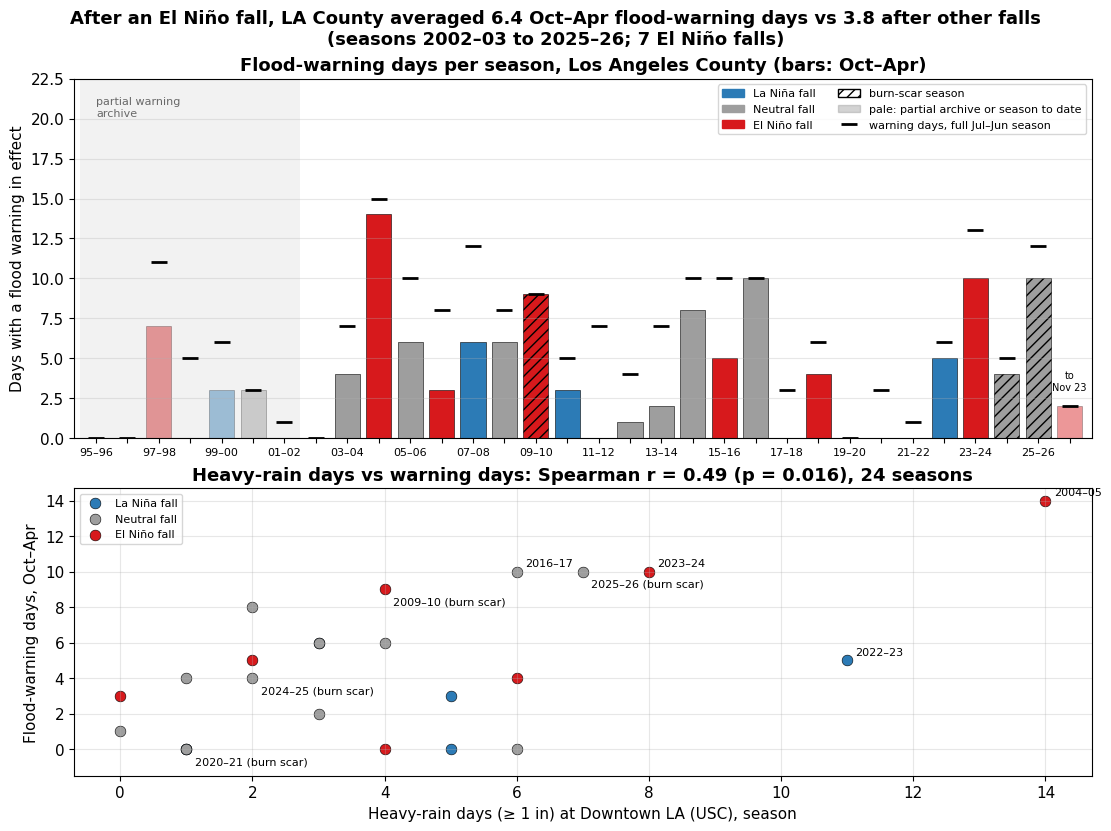

In [ ]:
# Chart 26: flood-warning days per season (Oct-Apr) by fall phase, and their link with heavy-rain days at USC
fig, axes = plt.subplots(2, 1, figsize=(11, 8.2), layout="constrained", height_ratios=[1.25, 1])
ax = axes[0]
phase_of = lambda oni_: "El Niño" if oni_ >= 0.5 else ("La Niña" if oni_ <= -0.5 else "Neutral")
xs = np.arange(len(warn_tbl))
for x_, (s, r) in zip(xs, warn_tbl.iterrows()):
    style = dict(color=PHASE_COLORS[phase_of(r["aso_oni"])], edgecolor="black", lw=.4)
    if r["partial_archive"] or r["in_progress"]:
        style.update(alpha=.45)
    ax.bar(x_, r["warn_days_oct_apr"], hatch="///" if isinstance(r["burn_scar"], str) else None, **style)
    ax.plot(x_, r["warn_days_jul_jun"], marker="_", ms=11, mew=2, color="black")
ax.set_ylim(0, warn_tbl["warn_days_jul_jun"].max() * 1.5)          # room for the legend above the bars
ax.axvspan(-0.5, (warn_tbl.index < FULL_ARCHIVE_FROM).sum() - 0.5, color="gray", alpha=.1, lw=0)
ax.text(0, ax.get_ylim()[1] * 0.95, "partial warning\narchive", fontsize=8, color="dimgray", va="top")
ax.text(xs[-1], warn_tbl["warn_days_oct_apr"].iloc[-1] + 1, f"to\n{vtec_through:%b %d}", ha="center", fontsize=7)
ax.set_xticks(xs, [w[2:] if i % 2 == 0 else "" for i, w in enumerate(warn_tbl["winter"])], fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=PHASE_COLORS[p], label=f"{p} fall") for p in PHASES]
handles += [plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", hatch="///", label="burn-scar season"),
            plt.Rectangle((0, 0), 1, 1, color="#9e9e9e", alpha=.45, label="pale: partial archive or season to date"),
            plt.Line2D([], [], marker="_", ms=11, mew=2, color="black", ls="none", label="warning days, full Jul–Jun season")]
ax.legend(handles=handles, loc="upper right", fontsize=8, ncol=2)
ax.set(ylabel="Days with a flood warning in effect", xlim=(-0.7, len(xs) - 0.3),
       title="Flood-warning days per season, Los Angeles County (bars: Oct–Apr)")
ax.grid(axis="y", alpha=.3)

ax = axes[1]
h = warn_cmp["headline_oct_apr"]
for p in PHASES:
    d = main_set[[phase_of(v) == p for v in main_set["aso_oni"]]]
    ax.scatter(d["heavy"], d["warn_days_oct_apr"], color=PHASE_COLORS[p], s=60, edgecolor="black", lw=.4, label=f"{p} fall")
for s, r in main_set.iterrows():
    burn = isinstance(r["burn_scar"], str)
    if r["warn_days_oct_apr"] >= 9 or r["heavy"] >= 9 or burn:
        ax.annotate(r["winter"] + (" (burn scar)" if burn else ""), (r["heavy"], r["warn_days_oct_apr"]),
                    textcoords="offset points", xytext=(6, -11 if burn else 4), fontsize=8)
ax.set_ylim(bottom=-1.5)
ax.set(xlabel="Heavy-rain days (≥ 1 in) at Downtown LA (USC), season", ylabel="Flood-warning days, Oct–Apr",
       title=f"Heavy-rain days vs warning days: Spearman r = {h['spearman_heavy']['r']:.2f} (p = {h['spearman_heavy']['p']:.3f}), "
             f"{h['spearman_heavy']['n']} seasons")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=.3)
fig.suptitle(f"After an El Niño fall, LA County averaged {h['el_nino']['mean_days']:.1f} Oct–Apr flood-warning days vs "
             f"{h['other']['mean_days']:.1f} after other falls\n(seasons {main_set['winter'].iloc[0]} to "
             f"{main_set['winter'].iloc[-1]}; {h['el_nino']['n']} El Niño falls)", fontsize=13, fontweight="bold")
save(fig, "26_flood_warnings.png")

### <mark style="background-color:#FFC891">13.3 Storm intensity: hours with at least 0.5 in of rain (Downtown USC, hourly reports)</mark>
<mark style="background-color:#FFC891">Daily totals hide how fast the rain falls, and flash floods and debris flows follow the fast part. The Downtown USC
weather station (CQT) sends a routine report every hour with the rain since the previous report. We keep only these routine
reports, put each one in its clock hour (Pacific standard time, UTC−8, so that every day has 24 hours), and count the
*intense hours* (≥ 0.50 in) in Oct–Apr of each season, the hours the coverage rule below checks and the window of the
13.2 headline. The full Jul–Jun count is kept as a second column.</mark>

<mark style="background-color:#FFC891">**Coverage rule.** A season is used only if at least 90 % of its Oct–Apr hours have a routine report. Before 2012 the
archive leaves the rain field blank in reports without rain (the report then has no rain group), so a blank counts as no
rain when the report itself exists. As a check, the hourly amounts are summed over Oct–Apr and compared with the daily
record of the same station. IEM's archive for this station ends on 20 May 2024 (IEM lists it as offline since then), so
the hourly part covers seasons up to 2023–24 only.</mark>

In [ ]:
# 13.3 Download (or read from the cache) the routine hourly reports of Downtown USC (CQT), one file per calendar year.
# IEM's archive of routine reports for CQT starts in July 1999; years after the last report come back as a header only.
CQT_DIR = RAW / "iem_asos_cqt"
CQT_DIR.mkdir(exist_ok=True)
CQT_HEADER = b"station,valid,p01i"
CQT_YEARS = range(1999, dt.date.today().year + 1)


def cqt_url(year):
    return (f"{IEM}/cgi-bin/request/asos.py?station=CQT&data=p01i&year1={year}&month1=1&day1=1&year2={year + 1}&month2=1"
            "&day2=1&tz=Etc/UTC&format=onlycomma&latlon=no&missing=M&trace=T&direct=no&report_type=3")   # 3 = routine reports


t0, n_new = time.time(), 0
for year in CQT_YEARS:
    path = CQT_DIR / f"CQT_p01i_{year}.csv"
    if os.path.exists(path):
        continue
    body = iem_get(cqt_url(year))
    if not body.startswith(CQT_HEADER):
        raise ValueError(f"unexpected answer for {year}: {body[:200]!r}")
    path.write_bytes(body)
    n_new += 1
print(f"hourly files {CQT_YEARS[0]}–{CQT_YEARS[-1]}: {n_new} downloaded ({time.time() - t0:.0f} s), "
      f"{len(CQT_YEARS) - n_new} read from the cache")

cqt = pd.concat([pd.read_csv(CQT_DIR / f"CQT_p01i_{y}.csv", dtype=str, keep_default_na=False) for y in CQT_YEARS],
                ignore_index=True)
cqt["lst"] = pd.to_datetime(cqt["valid"]) - pd.Timedelta(hours=8)        # UTC -> Pacific standard time
cqt["inch"] = pd.to_numeric(cqt["p01i"].replace({"T": "0", "M": ""}), errors="coerce")   # T = trace (< 0.01 in)
cqt["hour"] = cqt["lst"].dt.floor("h")
multi = int(cqt["hour"].duplicated().sum())
hourly = cqt.groupby("hour")["inch"].max().fillna(0)         # a report without a rain group = no rain; 2 reports in 1 hour: larger
last_report = cqt["lst"].max()
print(f"{len(cqt):,} routine reports, {cqt['lst'].min():%Y-%m-%d} to {last_report:%Y-%m-%d %H:%M} (PST); "
      f"clock hours with 2 reports: {multi}; blank rain field: {(cqt['p01i'] == 'M').mean():.0%} of reports")

# Counts use Oct-Apr, the window whose hours the coverage rule checks (and the window of the 13.2 headline); the Jul-Jun
# count, which adds summer thunderstorms and tropical remnants, is kept as a second column.
INTENSE_IN = 0.50
hr_season = pd.Series(to_season(hourly.index), index=hourly.index)
hr_octapr = hourly.index.month.isin(OCT_APR)
daily_octapr_in = la[la["month"].isin(OCT_APR)].groupby("season")["mm"].sum() / MM_PER_IN
first_report = cqt["lst"].min()
first_s = first_report.year if first_report < pd.Timestamp(f"{first_report.year}-10-01") else first_report.year + 1
cqt_rows = []
for s in range(first_s, int(to_season(pd.DatetimeIndex([last_report]))[0]) + 1):
    expected = len(pd.date_range(f"{s}-10-01", f"{s + 1}-05-01", freq="h", inclusive="left"))
    in_s = (hr_season == s).to_numpy()
    oa = hourly[in_s & hr_octapr]
    cqt_rows.append({"season": s, "winter": f"{s}–{str(s + 1)[-2:]}", "oct_apr_hours": len(oa), "oct_apr_expected": expected,
                     "coverage": len(oa) / expected, "intense_hours": int((oa >= INTENSE_IN).sum()),
                     "intense_hours_jul_jun": int((hourly[in_s] >= INTENSE_IN).sum()), "max_1h_in": oa.max(),
                     "hourly_oct_apr_in": oa.sum(), "daily_oct_apr_in": daily_octapr_in.get(s, np.nan)})
cqt_tbl = pd.DataFrame(cqt_rows).set_index("season")
cqt_tbl["hourly_vs_daily"] = cqt_tbl["hourly_oct_apr_in"] / cqt_tbl["daily_oct_apr_in"]
cqt_tbl["aso_oni"] = aso.set_index("season")["aso_oni"].reindex(cqt_tbl.index)
cqt_tbl["el_nino_fall"] = cqt_tbl["aso_oni"] >= 0.5
cqt_tbl["used"] = cqt_tbl["coverage"] >= 0.90
cqt_used = cqt_tbl[cqt_tbl["used"]]

cqt_cmp = {}
for key, g in [("el_nino", cqt_used[cqt_used["el_nino_fall"]]), ("other", cqt_used[~cqt_used["el_nino_fall"]])]:
    k = int((g["intense_hours"] >= 1).sum())
    lo, hi = wilson(k, len(g))
    cqt_cmp[key] = {"n": len(g), "seasons": g["winter"].tolist(), "mean_intense_hours": g["intense_hours"].mean(),
                    "total_intense_hours": int(g["intense_hours"].sum()), "ge1_k": k, "ge1_share": k / len(g), "ge1_ci95": (lo, hi),
                    "median_max_1h_in": g["max_1h_in"].median(), "mean_intense_hours_jul_jun": g["intense_hours_jul_jun"].mean()}
cqt_cmp["ratio_of_means"] = cqt_cmp["el_nino"]["mean_intense_hours"] / cqt_cmp["other"]["mean_intense_hours"]
print(f"seasons used (≥ 90 % of Oct–Apr hours): {len(cqt_used)} of {len(cqt_tbl)}; left out: "
      f"{', '.join(f'{w} ({c:.0%})' for w, c in cqt_tbl.loc[~cqt_tbl['used'], ['winter', 'coverage']].itertuples(index=False))}")
print(f"hourly vs daily Oct–Apr totals in the seasons used: median ratio {cqt_used['hourly_vs_daily'].median():.2f} "
      f"(range {cqt_used['hourly_vs_daily'].min():.2f}–{cqt_used['hourly_vs_daily'].max():.2f}); intense hours outside Oct–Apr "
      f"(not counted): {int((cqt_used['intense_hours_jul_jun'] - cqt_used['intense_hours']).sum())}")
for key in ["el_nino", "other"]:
    c = cqt_cmp[key]
    print(f"{key:8s} n = {c['n']:2d}: {c['mean_intense_hours']:.2f} intense Oct–Apr hours per season ({c['total_intense_hours']} in all; "
          f"Jul–Jun {c['mean_intense_hours_jul_jun']:.2f}), ≥ 1 intense hour in {c['ge1_k']}/{c['n']} "
          f"[{c['ge1_ci95'][0]:.0%}–{c['ge1_ci95'][1]:.0%}], median wettest Oct–Apr hour {c['median_max_1h_in']:.2f} in")
cqt_tbl.drop(columns=["oct_apr_expected", "el_nino_fall"]).round(2)

hourly files 1999–2026: 0 downloaded (0 s), 28 read from the cache


216,126 routine reports, 1999-06-30 to 2024-05-20 06:47 (PST); clock hours with 2 reports: 155; blank rain field: 48% of reports
seasons used (≥ 90 % of Oct–Apr hours): 24 of 25; left out: 2021–22 (81%)
hourly vs daily Oct–Apr totals in the seasons used: median ratio 1.00 (range 0.94–1.29); intense hours outside Oct–Apr (not counted): 8
el_nino  n =  7: 2.71 intense Oct–Apr hours per season (19 in all; Jul–Jun 3.29), ≥ 1 intense hour in 6/7 [49%–97%], median wettest Oct–Apr hour 0.87 in
other    n = 17: 0.71 intense Oct–Apr hours per season (12 in all; Jul–Jun 0.94), ≥ 1 intense hour in 9/17 [31%–74%], median wettest Oct–Apr hour 0.50 in


,winter,oct_apr_hours,coverage,intense_hours,intense_hours_jul_jun,max_1h_in,hourly_oct_apr_in,daily_oct_apr_in,hourly_vs_daily,aso_oni,used
season,,,,,,,,,,,
1999,1999–00,4918,0.96,0,0,0.47,10.84,11.57,0.94,-1.00,True
2000,2000–01,5069,1.00,2,2,0.60,17.60,17.72,0.99,-0.42,True
2001,2001–02,5081,1.00,1,1,0.51,4.25,4.36,0.97,-0.15,True
2002,2002–03,5060,0.99,4,4,0.87,15.54,15.48,1.00,0.78,True
2003,2003–04,5099,1.00,1,1,0.59,9.22,9.26,1.00,0.23,True
2004,2004–05,4992,0.98,6,6,1.29,36.92,37.07,1.00,0.58,True
2005,2005–06,5066,1.00,0,1,0.46,12.05,12.05,1.00,-0.11,True
2006,2006–07,5087,1.00,1,1,0.95,4.16,3.22,1.29,0.54,True
2007,2007–08,5088,1.00,1,1,0.51,12.70,12.91,0.98,-1.05,True


saved charts/27_storm_intensity.png


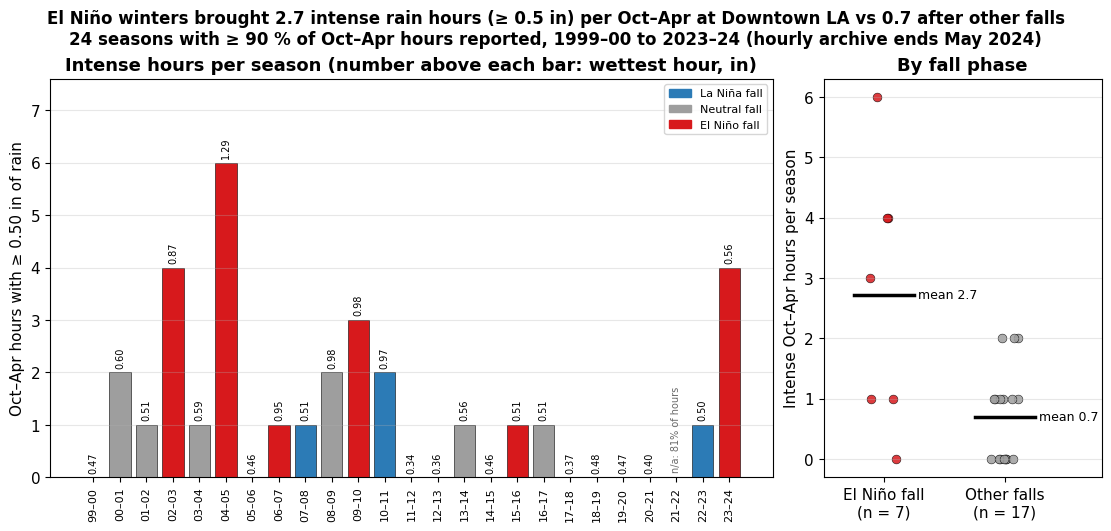

In [ ]:
# Chart 27: intense hours (>= 0.5 in in one hour) per season at Downtown USC, by fall phase
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), layout="constrained", gridspec_kw={"width_ratios": [2.6, 1]})
ax = axes[0]
xs = np.arange(len(cqt_tbl))
for x_, (s, r) in zip(xs, cqt_tbl.iterrows()):
    if not r["used"]:
        ax.text(x_, 0.1, f"n/a: {r['coverage']:.0%} of hours", ha="center", va="bottom", rotation=90, fontsize=7, color="dimgray")
        continue
    ax.bar(x_, r["intense_hours"], color=PHASE_COLORS[phase_of(r["aso_oni"])], edgecolor="black", lw=.4)
    ax.text(x_, r["intense_hours"] + 0.08, f"{r['max_1h_in']:.2f}", ha="center", fontsize=7, rotation=90, va="bottom")
ax.set_xticks(xs, [w[2:] for w in cqt_tbl["winter"]], rotation=90, fontsize=8)
ax.set(ylabel=f"Oct–Apr hours with ≥ {INTENSE_IN:.2f} in of rain", ylim=(0, cqt_tbl["intense_hours"].max() + 1.6),
       title="Intense hours per season (number above each bar: wettest hour, in)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PHASE_COLORS[p], label=f"{p} fall") for p in PHASES], loc="upper right", fontsize=8)
ax.grid(axis="y", alpha=.3)

ax = axes[1]
for j, (key, label, color) in enumerate([("el_nino", "El Niño fall", PHASE_COLORS["El Niño"]), ("other", "Other falls", "#9e9e9e")]):
    g = cqt_used[cqt_used["el_nino_fall"] == (key == "el_nino")]
    ax.scatter(j + np.random.default_rng(j).uniform(-0.12, 0.12, len(g)), g["intense_hours"], color=color, s=40,
               edgecolor="black", lw=.4, alpha=.85)
    m = cqt_cmp[key]["mean_intense_hours"]
    ax.plot([j - 0.25, j + 0.25], [m, m], color="black", lw=2.5)
    ax.text(j + 0.28, m, f"mean {m:.1f}", va="center", fontsize=9)
ax.set_xticks([0, 1], [f"El Niño fall\n(n = {cqt_cmp['el_nino']['n']})", f"Other falls\n(n = {cqt_cmp['other']['n']})"])
ax.set(xlim=(-0.5, 1.8), ylabel="Intense Oct–Apr hours per season", title="By fall phase")
ax.grid(axis="y", alpha=.3)
fig.suptitle(f"El Niño winters brought {cqt_cmp['el_nino']['mean_intense_hours']:.1f} intense rain hours (≥ 0.5 in) per Oct–Apr at "
             f"Downtown LA vs {cqt_cmp['other']['mean_intense_hours']:.1f} after other falls\n{len(cqt_used)} seasons with ≥ 90 % "
             f"of Oct–Apr hours reported, {cqt_used['winter'].iloc[0]} to {cqt_used['winter'].iloc[-1]} (hourly archive ends "
             f"{last_report:%b %Y})", fontsize=12, fontweight="bold")
save(fig, "27_storm_intensity.png")

### <mark style="background-color:#FFC891">13.4 Winter 2026–27</mark>
<mark style="background-color:#FFC891">This fall's ONI puts 2026–27 in the Strong El Niño tier. The cell below collects what 13.1–13.3 imply for this
winter and what has happened so far. The strong tier holds only 4 past seasons, so its shares have wide intervals; the
logistic curve uses all 76 seasons and is the steadier number. Both describe odds, not a forecast of particular storms.</mark>

In [ ]:
# 13.4 Winter 2026-27: tier odds, the logistic probabilities at this fall's ONI, and the season so far
now_tier = STRENGTHS[3] if ONI_NOW >= 1.5 else STRENGTHS[2] if ONI_NOW >= 0.5 else STRENGTHS[0] if ONI_NOW <= -0.5 else STRENGTHS[1]
tier_now = tier_tbl.loc[now_tier]
tier_seasons = flood_seasons[flood_seasons["strength_oni"] == now_tier]
so_far = la[(la["season"] == 2026) & la["mm"].notna()]
storms_so_far = storm_runs[storm_runs["season"] == 2026]
w_now = warn_tbl.loc[now_season]                     # 2026-27 to date
prev_winter = warn_tbl.loc[now_season - 1]

winter_block = {
    "aso_oni": ONI_NOW, "tier": now_tier,
    "tier_seasons": {f"{s}–{str(s + 1)[-2:]}": int(h) for s, h in tier_seasons["heavy"].items()},
    "tier_odds": {key: {"k": int(tier_now[f"{key}_k"]), "n": int(tier_now["n"]), "share": float(tier_now[key]),
                        "ci95": [float(tier_now[f"{key}_lo"]), float(tier_now[f"{key}_hi"])]} for key in TIER_EVENTS},
    "logistic_p_storm_heavy": dict(zip(["p", "lo", "hi"], curve6["p_at"][ONI_NOW])),
    "logistic_p_heavy3": dict(zip(["p", "lo", "hi"], curve3["p_at"][ONI_NOW])),
    "expected_heavy_days_tier_mean": float(tier_now["heavy_mean"]),
    "heavy_days_range_in_tier": [int(tier_seasons["heavy"].min()), int(tier_seasons["heavy"].max())],
    "expected_heavy_days_all_el_nino_falls": float(flood_seasons.loc[flood_seasons["phase"] == "El Niño", "heavy"].mean()),
    "so_far_rain": {"through": str(so_far["DATE"].max().date()), "inches": float(so_far["mm"].sum() / MM_PER_IN),
                    "heavy_days": int(so_far["heavy_day"].sum()), "storms": len(storms_so_far),
                    "major_storms": int((storms_so_far["inches"] >= 3).sum())},
    "so_far_warnings": {"through": str(vtec_through.date()), "warning_days_oct_apr": int(w_now["warn_days_oct_apr"]),
                        "warning_days_jul_jun": int(w_now["warn_days_jul_jun"]),
                        "flash_flood_warnings": int(w_now["flash_flood_warnings"]), "advisory_days": int(w_now["advisory_days"])},
    "burn_scar_note": ("2026–27 is the second full winter after the January 2025 Palisades and Eaton fires. In 2025–26 the county "
                       f"had {int(prev_winter['warn_days_oct_apr'])} Oct–Apr flood-warning days and {int(prev_winter['flash_flood_warnings'])} "
                       f"Flash Flood Warnings with {int(prev_winter['heavy'])} heavy-rain days at USC; burned slopes still need less rain "
                       "to flood, so warning counts this winter can run above what the rain alone would suggest."),
}
wb = winter_block
print(f"ASO 2026 ONI {ONI_NOW:+.2f} -> tier: {now_tier} (past seasons and their heavy-rain days: {wb['tier_seasons']})")
for key, (_, _, label) in TIER_EVENTS.items():
    o = wb["tier_odds"][key]
    print(f"  {label:42s} {o['k']}/{o['n']} = {o['share']:.0%} [{o['ci95'][0]:.0%}–{o['ci95'][1]:.0%}]")
print(f"logistic curve at ONI {ONI_NOW:+.2f}: P(storm-heavy, ≥ 6 heavy days) = {wb['logistic_p_storm_heavy']['p']:.2f} "
      f"[{wb['logistic_p_storm_heavy']['lo']:.2f}–{wb['logistic_p_storm_heavy']['hi']:.2f}], P(≥ 3) = {wb['logistic_p_heavy3']['p']:.2f} "
      f"[{wb['logistic_p_heavy3']['lo']:.2f}–{wb['logistic_p_heavy3']['hi']:.2f}]")
print(f"expected heavy-rain days: {wb['expected_heavy_days_tier_mean']:.2f} (strong-tier mean, range {wb['heavy_days_range_in_tier'][0]}–"
      f"{wb['heavy_days_range_in_tier'][1]}); all El Niño falls {wb['expected_heavy_days_all_el_nino_falls']:.2f}")
r_, w_ = wb["so_far_rain"], wb["so_far_warnings"]
print(f"so far: {r_['inches']:.2f} in, {r_['heavy_days']} heavy-rain days, {r_['storms']} storms ({r_['major_storms']} major) through "
      f"{r_['through']}; flood-warning days {w_['warning_days_oct_apr']} (Oct–Apr) / {w_['warning_days_jul_jun']} (Jul–Jun), "
      f"{w_['flash_flood_warnings']} Flash Flood Warnings, {w_['advisory_days']} advisory days through {w_['through']}")
print(wb["burn_scar_note"])

ASO 2026 ONI +2.46 -> tier: Strong El Niño (≥ 1.5) (past seasons and their heavy-rain days: {'1965–66': 6, '1997–98': 11, '2015–16': 2, '2023–24': 8})
  ≥ 2 heavy-rain days                        4/4 = 100% [51%–100%]
  ≥ 3 heavy-rain days                        3/4 = 75% [30%–95%]
  ≥ 6 heavy-rain days (storm-heavy season)   3/4 = 75% [30%–95%]
  ≥ 1 major storm (≥ 3 in)                   3/4 = 75% [30%–95%]
logistic curve at ONI +2.46: P(storm-heavy, ≥ 6 heavy days) = 0.86 [0.56–0.98], P(≥ 3) = 0.76 [0.41–0.94]
expected heavy-rain days: 6.75 (strong-tier mean, range 2–11); all El Niño falls 5.70
so far: 2.44 in, 0 heavy-rain days, 4 storms (0 major) through 2026-11-13; flood-warning days 2 (Oct–Apr) / 2 (Jul–Jun), 4 Flash Flood Warnings, 8 advisory days through 2026-11-23
2026–27 is the second full winter after the January 2025 Palisades and Eaton fires. In 2025–26 the county had 10 Oct–Apr flood-warning days and 35 Flash Flood Warnings with 7 heavy-rain days at USC; burned slopes st

### <mark style="background-color:#FFC891">13.5 Add the numbers to `summary.json`</mark>
<mark style="background-color:#FFC891">The cell below reads `summary.json` as section 10 wrote it, adds one key, `flood_risk`, with every number quoted
in this section (tiers, threshold, warnings with one row per season, storms, winter 2026–27, definitions and sources), and
checks that no other key changed.</mark>

In [ ]:
# 13.5 Add the section 13 numbers to summary.json as one new key, "flood_risk"; every other key stays exactly as section 10 wrote it
def rnd(v, n=2):
    """Rounded float for JSON; None when missing or unbounded."""
    return None if v is None or not np.isfinite(float(v)) else round(float(v), n)


def share_block(k, n, lo, hi):
    return {"k": int(k), "n": int(n), "share": rnd(k / n), "ci95": [rnd(lo), rnd(hi)]}


def curve_block(c):
    return {"outcome": f">= {c['k']} heavy-rain days in the season", "seasons": c["seasons"], "hits": c["hits"],
            "base_rate": rnd(c["base_rate"], 3), "logit": {"intercept": rnd(c["intercept"], 3), "slope_per_degc": rnd(c["slope"], 3)},
            "oni_p50": rnd(c["oni_p50"]), "oni_p50_ci95": [rnd(v) for v in c["oni_p50_ci95"]],
            "slope_not_positive_share": rnd(c["slope_not_positive_share"], 3),
            "p_at_oni": {f"{x:.2f}": {"p": rnd(p), "ci95": [rnd(lo), rnd(hi)]} for x, (p, lo, hi) in c["p_at"].items()}}


def cmp_block(c):
    return {**{k: {"n": c[k]["n"], "mean_days": rnd(c[k]["mean_days"]),
                   "ge2_days": share_block(c[k]["ge2_k"], c[k]["n"], *c[k]["ge2_ci95"])} for k in ["el_nino", "other"]},
            "ratio_of_means": rnd(c["ratio_of_means"]),
            "spearman_heavy_days": {"r": rnd(c["spearman_heavy"]["r"]), "p": rnd(c["spearman_heavy"]["p"], 4),
                                    "n": c["spearman_heavy"]["n"]}}


flood_risk = {
    "definitions": {
        "season": "Jul 1 - Jun 30, named by its start year; tier = Aug-Oct (ASO) ONI of the start year",
        "heavy_day": ">= 1.00 in (25.4 mm) at Los Angeles Downtown (USC), GHCN-Daily USW00093134",
        "very_heavy_day": ">= 2.00 in", "storm": "run of consecutive days each >= 0.10 in; total over the run; season of its first day",
        "major_storm": "storm total >= 3.00 in (storms >= 2.00 in also counted)", "max_3day": "largest 3-day rolling total in the season",
        "tiers": "La Nina <= -0.5; Neutral; Moderate El Nino 0.5-1.49; Strong El Nino >= 1.5 (ASO ONI)",
        "storm_heavy_season": f">= {STORMY_K} heavy-rain days",
        "threshold": f"logistic regression of 1{{heavy days >= {STORMY_K}}} on ASO ONI; ONI where P = 0.5; 95 % CI from "
                     f"{N_BOOT} season-bootstrap resamples (percentiles; resamples with slope <= 0 have no threshold and count as +inf)",
        "flood_warning_day": "local (America/Los_Angeles) date with >= 1 NWS FF.W, FA.W or FL.W in effect for Los Angeles County "
                             "(CAC037), issue to expiry; headline count Oct-Apr, second count Jul-Jun",
        "advisory_day": "local date with >= 1 Flood Advisory (FA.Y) in effect",
        "intense_hour": f">= {INTENSE_IN:.2f} in in one routine hourly report at Downtown USC (CQT); clock hour in PST (UTC-8); "
                        "counted in Oct-Apr (Jul-Jun count kept as a second field)",
        "hourly_season_rule": "season used if >= 90 % of its Oct-Apr hours have a routine report; blank rain field in an "
                              "existing report = no rain",
    },
    "sources": {
        "daily_rain": LA_URL,
        "warnings": {"url": f"{IEM}/json/vtec_events_byugc.php?ugc=CAC037&sdate=1995-01-01&edate=<download date>",
                     "file": f"data/raw/{VTEC_FILE.name}", "generated_at": vtec["generated_at"],
                     "archive_note": "IEM: Flash Flood Warning archive complete from about 2002; most other warning types "
                                     "from 2005-2008 (mesonet.agron.iastate.edu/info/datasets/vtec.html)"},
        "hourly": {"url": f"{IEM}/cgi-bin/request/asos.py?station=CQT&data=p01i&report_type=3 (one calendar year per request)",
                   "files": f"data/raw/{CQT_DIR.name}/CQT_p01i_<year>.csv", "first_report_pst": f"{cqt['lst'].min():%Y-%m-%d %H:%M}",
                   "last_report_pst": f"{last_report:%Y-%m-%d %H:%M}"},
        "buoys": "Nino 3.4-box monthly buoy SST anomaly from section 9 (UCI to Jun 1998, NOAA PMEL GTMBA after)",
    },
    "season_measures_mean": {c: rnd(flood_seasons[c].mean()) for c in
                             ["heavy", "very_heavy", "storms", "storms_2in", "major_storms", "max_storm_in", "max_3day_in"]},
    "tiers": {t: {"n": int(r["n"]), "heavy_mean": rnd(r["heavy_mean"]), "very_heavy_mean": rnd(r["very_heavy_mean"]),
                  "storms_2in_mean": rnd(r["storms_2in_mean"]), "major_storms_mean": rnd(r["major_storms_mean"]),
                  "max_3day_median_in": rnd(r["max_3day_median_in"]),
                  **{f"p_{key}": share_block(r[f"{key}_k"], r["n"], r[f"{key}_lo"], r[f"{key}_hi"]) for key in TIER_EVENTS}}
              for t, r in tier_tbl.iterrows()},
    "threshold": {
        **curve_block(curve6),
        "buoy_equivalent": {"years": len(buoy_aso), "first_year": int(buoy_aso.index.min()), "last_year": int(buoy_aso.index.max()),
                            "years_missing": missing_years, "r": rnd(b_r, 3),
                            "fit": {"aso_oni_intercept": rnd(b_icept, 3), "slope": rnd(b_slope, 3), "residual_sd_c": rnd(b_resid_sd)},
                            "oni_p50_as_buoy_anom_c": rnd(thr_buoy), "ci95_c": [rnd(v) for v in thr_buoy_ci],
                            "aso_2026_buoy_anom_c": rnd(buoy_aso["buoy_aso"].get(2026, np.nan))},
        "secondary_heavy3": {**curve_block(curve3),
                             "note": "a season with >= 3 heavy-rain days is already the norm (base rate above 0.5), so there "
                                     "is no ONI tipping point for this outcome"},
    },
    "warnings": {
        "headline_seasons": f"{main_set['winter'].iloc[0]} to {main_set['winter'].iloc[-1]}",
        "may_sep_share_of_warning_days": rnd(summer_share, 3),
        "comparison_oct_apr": cmp_block(warn_cmp["headline_oct_apr"]),
        "comparison_jul_jun": cmp_block(warn_cmp["jul_jun"]),
        "sensitivity_1995_on_oct_apr": cmp_block(warn_cmp["sensitivity_1995_on_oct_apr"]),
        "sensitivity_no_burn_scar_oct_apr": cmp_block(warn_cmp["sensitivity_no_burn_scar_oct_apr"]),
        "advisory_days_mean": {"seasons": f"{adv_set['winter'].iloc[0]} to {adv_set['winter'].iloc[-1]}",
                               **{k: {"n": v["n"], "mean_days": rnd(v["mean_days"])} for k, v in adv_cmp.items()}},
        "burn_scar_seasons": {warn_tbl.loc[s, "winter"]: v for s, v in BURN_SCAR.items()},
        "caveats": ["warning counts also depend on burn scars and on warning practice (storm-based polygons from late 2007, "
                    "Flood Advisories from 2009)",
                    "IEM's Flash Flood Warning archive is complete from about 2002; 1995-96 to 2001-02 are flagged partial_archive",
                    "summer thunderstorms and tropical remnants (e.g. Hilary, Aug 2023) fall outside Oct-Apr"],
        "season_rows": [{"season": int(s), "winter": r["winter"], "aso_oni": rnd(r["aso_oni"]), "el_nino_fall": bool(r["el_nino_fall"]),
                         "heavy_days": None if pd.isna(r["heavy"]) else int(r["heavy"]),
                         "warning_days_oct_apr": int(r["warn_days_oct_apr"]), "warning_days_jul_jun": int(r["warn_days_jul_jun"]),
                         "flash_flood_warnings": int(r["flash_flood_warnings"]),
                         "advisory_days": None if pd.isna(r["advisory_days"]) else int(r["advisory_days"]),
                         "burn_scar": r["burn_scar"] if isinstance(r["burn_scar"], str) else None,
                         "partial_archive": bool(r["partial_archive"]), "in_progress": bool(r["in_progress"])}
                        for s, r in warn_tbl.iterrows()],
    },
    "storms": {
        "daily_largest": [{"start": f"{r.start:%Y-%m-%d}", "days": int(r.days), "inches": rnd(r.inches)} for r in biggest.itertuples()],
        "hourly": {"station": "CQT (Los Angeles Downtown/USC)", "seasons_used": cqt_used["winter"].tolist(),
                   "seasons_left_out": {w: rnd(c) for w, c in cqt_tbl.loc[~cqt_tbl["used"], ["winter", "coverage"]].itertuples(index=False)},
                   "hourly_vs_daily_oct_apr_ratio_median": rnd(cqt_used["hourly_vs_daily"].median(), 3),
                   **{k: {"n": v["n"], "seasons": v["seasons"], "mean_intense_hours": rnd(v["mean_intense_hours"]),
                          "total_intense_hours": v["total_intense_hours"], "ge1_intense_hour": share_block(v["ge1_k"], v["n"], *v["ge1_ci95"]),
                          "median_max_1h_in": rnd(v["median_max_1h_in"]), "mean_intense_hours_jul_jun": rnd(v["mean_intense_hours_jul_jun"])}
                      for k, v in cqt_cmp.items() if k != "ratio_of_means"},
                   "ratio_of_means": rnd(cqt_cmp["ratio_of_means"]),
                   "season_rows": [{"season": int(s), "winter": r["winter"], "aso_oni": rnd(r["aso_oni"]), "used": bool(r["used"]),
                                    "oct_apr_coverage": rnd(r["coverage"], 3), "intense_hours_oct_apr": int(r["intense_hours"]),
                                    "intense_hours_jul_jun": int(r["intense_hours_jul_jun"]), "max_1h_oct_apr_in": rnd(r["max_1h_in"]),
                                    "hourly_vs_daily_oct_apr": rnd(r["hourly_vs_daily"], 3)}
                                   for s, r in cqt_tbl.iterrows()]},
    },
    "winter_2026_27": {**{k: v for k, v in winter_block.items() if k not in ("tier_odds", "logistic_p_storm_heavy", "logistic_p_heavy3")},
                       "expected_heavy_days_tier_mean": rnd(winter_block["expected_heavy_days_tier_mean"]),
                       "expected_heavy_days_all_el_nino_falls": rnd(winter_block["expected_heavy_days_all_el_nino_falls"]),
                       "tier_odds": {k: {**v, "share": rnd(v["share"]), "ci95": [rnd(x) for x in v["ci95"]]}
                                     for k, v in winter_block["tier_odds"].items()},
                       "logistic_p_storm_heavy": {"p": rnd(winter_block["logistic_p_storm_heavy"]["p"]),
                                                  "ci95": [rnd(winter_block["logistic_p_storm_heavy"][x]) for x in ("lo", "hi")]},
                       "logistic_p_heavy3": {"p": rnd(winter_block["logistic_p_heavy3"]["p"]),
                                             "ci95": [rnd(winter_block["logistic_p_heavy3"][x]) for x in ("lo", "hi")]}},
}
flood_risk["winter_2026_27"]["so_far_rain"]["inches"] = rnd(winter_block["so_far_rain"]["inches"])

saved = json.loads(Path("summary.json").read_text(encoding="utf-8"))
before = {k: v for k, v in saved.items() if k != "flood_risk"}
saved["flood_risk"] = to_builtin(flood_risk)
Path("summary.json").write_text(json.dumps(saved, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
check = json.loads(Path("summary.json").read_text(encoding="utf-8"))
assert {k: v for k, v in check.items() if k != "flood_risk"} == before, "only flood_risk may change"
print(f"summary.json: {len(check)} keys, added 'flood_risk' with {list(check['flood_risk'])}")

summary.json: 25 keys, added 'flood_risk' with ['definitions', 'sources', 'season_measures_mean', 'tiers', 'threshold', 'warnings', 'storms', 'winter_2026_27']


In [ ]:
# Reading section 13 (written from the numbers above, so it stays right when the data are refreshed)
from IPython.display import Markdown, display

MARK = '<mark style="background-color:#FFC891">{}</mark>'
T = tier_tbl
NAMES = {STRENGTHS[0]: "La Niña", STRENGTHS[1]: "neutral", STRENGTHS[2]: "moderate El Niño", STRENGTHS[3]: "strong El Niño"}
share_k = lambda t, key: f"{NAMES[t]} {int(T.loc[t, f'{key}_k'])}/{int(T.loc[t, 'n'])}"
c6, c3 = curve6, curve3
p6, p3 = {x: v[0] for x, v in c6["p_at"].items()}, {x: v[0] for x, v in c3["p_at"].items()}
lo6, hi6 = c6["oni_p50_ci95"]
flat = ("none of the bootstrap resamples gave a flat or falling curve" if c6["slope_not_positive_share"] == 0 else
        f"{c6['slope_not_positive_share']:.1%} of the bootstrap resamples gave a flat or falling curve")
major = T.loc[STRENGTHS, "major_storm"]

h, jj = warn_cmp["headline_oct_apr"], warn_cmp["jul_jun"]
s95, nbs = warn_cmp["sensitivity_1995_on_oct_apr"], warn_cmp["sensitivity_no_burn_scar_oct_apr"]
w97 = warn_tbl.loc[1997]
ffw_rank97 = int((done["flash_flood_warnings"] > w97["flash_flood_warnings"]).sum()) + 1
adv_dir = "the same direction" if adv_cmp["el_nino"]["mean_days"] > adv_cmp["other"]["mean_days"] else "no such gap"
ci_txt = lambda c: f"{c[0]:.0%}–{c[1]:.0%}"

ce, co = cqt_cmp["el_nino"], cqt_cmp["other"]
en_hours = cqt_used.loc[cqt_used["el_nino_fall"], "intense_hours"]
top_en = cqt_used.loc[en_hours.idxmax(), "winter"]
left_out = ", ".join(cqt_tbl.loc[~cqt_tbl["used"], "winter"]) or "none"

wb = winter_block
prev = warn_tbl.loc[2025]
ffw_max_note = (", the most in the record" if prev["flash_flood_warnings"] == done["flash_flood_warnings"].max() else "")

bullets = [
    f"*Thresholds.* At least 3 heavy-rain days is the norm in Los Angeles ({c3['hits']} of {c3['seasons']} seasons): the fitted "
    f"chance is already {p3[0.0]:.2f} at a fall ONI of 0 and only reaches {p3[ONI_NOW]:.2f} at {ONI_NOW:+.2f}, so there is no ONI at "
    f"which it tips. A storm-heavy season (≥ {STORMY_K} heavy-rain days, {c6['hits']} of {c6['seasons']} seasons) behaves differently: "
    f"its chance climbs from {p6[0.0]:.2f} at ONI 0 to {p6[1.0]:.2f} at +1.0, {p6[1.5]:.2f} at +1.5 and {p6[2.0]:.2f} at +2.0, and "
    f"crosses 50 % at a fall ONI of **{c6['oni_p50']:+.2f}** (95 % season-bootstrap CI {fmt_oni(lo6)} to {fmt_oni(hi6)}; {flat}). "
    f"The upper end is loose because only {int(T.loc[STRENGTHS[3], 'n'])} of the {c6['seasons']} falls reached +1.5. On the Niño 3.4-box buoys "
    f"the threshold is an Aug–Oct anomaly of about **{thr_buoy:+.2f} °C** ({fmt_oni(thr_buoy_ci[0])} to {fmt_oni(thr_buoy_ci[1])} °C), "
    f"from a line that tracks the ONI closely (r = {b_r:.2f} over {len(buoy_aso)} years).",

    f"*Risk tiers.* Storm-heavy seasons: {', '.join(share_k(t, 'heavy6') for t in STRENGTHS)}. Heavy-rain days rise with each tier "
    f"(mean {T.loc[STRENGTHS[0], 'heavy_mean']:.1f}, {T.loc[STRENGTHS[1], 'heavy_mean']:.1f}, {T.loc[STRENGTHS[2], 'heavy_mean']:.1f} and "
    f"{T.loc[STRENGTHS[3], 'heavy_mean']:.1f} per season), and at least 2 of them come in {T.loc['All seasons', 'heavy2']:.0%} of all "
    f"seasons. One major storm (≥ 3 in over consecutive days) is common after every kind of fall ({major.min():.0%}–{major.max():.0%} of "
    f"seasons; La Niña {major.iloc[0]:.0%}), so El Niño shows up in the number of heavy-rain days more than in whether one big storm arrives.",

    f"*Flood warnings.* In the {h['el_nino']['n'] + h['other']['n']} seasons {main_set['winter'].iloc[0]} to {main_set['winter'].iloc[-1]}, "
    f"Los Angeles County had **{h['el_nino']['mean_days']:.1f}** Oct–Apr flood-warning days per season after an El Niño fall against "
    f"**{h['other']['mean_days']:.1f}** after other falls (×{h['ratio_of_means']:.1f}); at least 2 warning days came in "
    f"{h['el_nino']['ge2_k']}/{h['el_nino']['n']} El Niño winters ({ci_txt(h['el_nino']['ge2_ci95'])}) and {h['other']['ge2_k']}/"
    f"{h['other']['n']} others ({ci_txt(h['other']['ge2_ci95'])}). Winters with more heavy-rain days at USC had more warning days "
    f"(Spearman r = {h['spearman_heavy']['r']:.2f}, p = {h['spearman_heavy']['p']:.3f}). Over the full Jul–Jun season the gap is smaller "
    f"({jj['el_nino']['mean_days']:.1f} vs {jj['other']['mean_days']:.1f}; r = {jj['spearman_heavy']['r']:.2f}) because "
    f"{summer_share:.0%} of all warning days fall in May–Sep. Checks: from 1995–96 on the Oct–Apr means are {s95['el_nino']['mean_days']:.1f} "
    f"vs {s95['other']['mean_days']:.1f}, and even the partial archive shows 1997–98 as a busy warning season "
    f"({int(w97['warn_days_oct_apr'])} Oct–Apr warning days; {int(w97['flash_flood_warnings'])} Flash Flood Warnings, rank {ffw_rank97} "
    f"of {len(done)} seasons); without the burn-scar seasons they are {nbs['el_nino']['mean_days']:.1f} vs {nbs['other']['mean_days']:.1f}. "
    f"Flood Advisories ({adv_set['winter'].iloc[0]} on) show {adv_dir} ({adv_cmp['el_nino']['mean_days']:.1f} vs "
    f"{adv_cmp['other']['mean_days']:.1f} advisory days).",

    f"*Storm intensity.* In the {len(cqt_used)} seasons with hourly data ({cqt_used['winter'].iloc[0]} to {cqt_used['winter'].iloc[-1]}; "
    f"left out: {left_out}), Downtown LA had **{ce['mean_intense_hours']:.1f}** intense hours (≥ {INTENSE_IN:.1f} in) per Oct–Apr after "
    f"an El Niño fall against **{co['mean_intense_hours']:.1f}** after other falls, and at least one in {ce['ge1_k']}/{ce['n']} El Niño "
    f"winters ({ci_txt(ce['ge1_ci95'])}) against {co['ge1_k']}/{co['n']} others ({ci_txt(co['ge1_ci95'])}). The wettest hour of an "
    f"El Niño winter was typically {ce['median_max_1h_in']:.2f} in, against {co['median_max_1h_in']:.2f} in. With {ce['n']} El Niño "
    f"winters this is suggestive, not proof; {top_en} alone holds {int(en_hours.max())} of their {ce['total_intense_hours']} intense hours.",

    f"*Winter 2026–27.* This fall (ONI {ONI_NOW:+.2f}) is in the strong tier, whose {len(wb['tier_seasons'])} past winters had "
    f"{', '.join(f'{v} ({k})' for k, v in wb['tier_seasons'].items())} heavy-rain days, {wb['expected_heavy_days_tier_mean']:.2f} on "
    f"average. The logistic curve gives **{wb['logistic_p_storm_heavy']['p']:.0%}** for a storm-heavy season "
    f"({wb['logistic_p_storm_heavy']['lo']:.0%}–{wb['logistic_p_storm_heavy']['hi']:.0%}), against {c6['base_rate']:.0%} in an average "
    f"year. So far USC has had {wb['so_far_rain']['inches']:.2f} in and {wb['so_far_rain']['heavy_days']} heavy-rain days (to "
    f"{wb['so_far_rain']['through']}), and the county {wb['so_far_warnings']['warning_days_oct_apr']} flood-warning days, "
    f"{wb['so_far_warnings']['flash_flood_warnings']} Flash Flood Warnings and {wb['so_far_warnings']['advisory_days']} advisory days "
    f"(to {wb['so_far_warnings']['through']}). It is the second full winter after the Palisades and Eaton fires: 2025–26 "
    f"({phase_of(prev['aso_oni'])} fall, {int(prev['heavy'])} heavy-rain days) brought {int(prev['warn_days_oct_apr'])} Oct–Apr warning days and "
    f"{int(prev['flash_flood_warnings'])} Flash Flood Warnings{ffw_max_note}, so this winter's warning counts can run above what the "
    f"rain alone would suggest.",

    f"*Limits.* One rain gauge stands in for a large county; warning counts also follow fires and NWS practice; the El Niño groups "
    f"are small ({h['el_nino']['n']} winters in the warning comparison, {ce['n']} in the hourly one, {int(T.loc[STRENGTHS[3], 'n'])} strong "
    f"falls); and the hourly archive ends in {last_report:%B %Y}. These are odds for planning, not a forecast of particular storms.",
]
display(Markdown(MARK.format("**Reading section 13.**") + "\n" + "\n".join("* " + MARK.format(b) for b in bullets)))

<mark style="background-color:#FFC891">**Reading section 13.**</mark>
* <mark style="background-color:#FFC891">*Thresholds.* At least 3 heavy-rain days is the norm in Los Angeles (46 of 76 seasons): the fitted chance is already 0.61 at a fall ONI of 0 and only reaches 0.76 at +2.46, so there is no ONI at which it tips. A storm-heavy season (≥ 6 heavy-rain days, 23 of 76 seasons) behaves differently: its chance climbs from 0.27 at ONI 0 to 0.54 at +1.0, 0.68 at +1.5 and 0.79 at +2.0, and crosses 50 % at a fall ONI of **+0.86** (95 % season-bootstrap CI +0.35 to +2.00; none of the bootstrap resamples gave a flat or falling curve). The upper end is loose because only 4 of the 76 falls reached +1.5. On the Niño 3.4-box buoys the threshold is an Aug–Oct anomaly of about **+0.83 °C** (+0.29 to +2.09 °C), from a line that tracks the ONI closely (r = 0.98 over 38 years).</mark>
* <mark style="background-color:#FFC891">*Risk tiers.* Storm-heavy seasons: La Niña 1/18, neutral 12/38, moderate El Niño 7/16, strong El Niño 3/4. Heavy-rain days rise with each tier (mean 3.1, 4.1, 5.4 and 6.8 per season), and at least 2 of them come in 79% of all seasons. One major storm (≥ 3 in over consecutive days) is common after every kind of fall (42%–75% of seasons; La Niña 61%), so El Niño shows up in the number of heavy-rain days more than in whether one big storm arrives.</mark>
* <mark style="background-color:#FFC891">*Flood warnings.* In the 24 seasons 2002–03 to 2025–26, Los Angeles County had **6.4** Oct–Apr flood-warning days per season after an El Niño fall against **3.8** after other falls (×1.7); at least 2 warning days came in 6/7 El Niño winters (49%–97%) and 11/17 others (41%–83%). Winters with more heavy-rain days at USC had more warning days (Spearman r = 0.49, p = 0.016). Over the full Jul–Jun season the gap is smaller (8.7 vs 6.5; r = 0.27) because 38% of all warning days fall in May–Sep. Checks: from 1995–96 on the Oct–Apr means are 6.5 vs 3.1, and even the partial archive shows 1997–98 as a busy warning season (7 Oct–Apr warning days; 25 Flash Flood Warnings, rank 4 of 31 seasons); without the burn-scar seasons they are 6.0 vs 3.6. Flood Advisories (2009–10 on) show the same direction (22.2 vs 13.1 advisory days).</mark>
* <mark style="background-color:#FFC891">*Storm intensity.* In the 24 seasons with hourly data (1999–00 to 2023–24; left out: 2021–22), Downtown LA had **2.7** intense hours (≥ 0.5 in) per Oct–Apr after an El Niño fall against **0.7** after other falls, and at least one in 6/7 El Niño winters (49%–97%) against 9/17 others (31%–74%). The wettest hour of an El Niño winter was typically 0.87 in, against 0.50 in. With 7 El Niño winters this is suggestive, not proof; 2004–05 alone holds 6 of their 19 intense hours.</mark>
* <mark style="background-color:#FFC891">*Winter 2026–27.* This fall (ONI +2.46) is in the strong tier, whose 4 past winters had 6 (1965–66), 11 (1997–98), 2 (2015–16), 8 (2023–24) heavy-rain days, 6.75 on average. The logistic curve gives **86%** for a storm-heavy season (56%–98%), against 30% in an average year. So far USC has had 2.44 in and 0 heavy-rain days (to 2026-11-13), and the county 2 flood-warning days, 4 Flash Flood Warnings and 8 advisory days (to 2026-11-23). It is the second full winter after the Palisades and Eaton fires: 2025–26 (Neutral fall, 7 heavy-rain days) brought 10 Oct–Apr warning days and 35 Flash Flood Warnings, the most in the record, so this winter's warning counts can run above what the rain alone would suggest.</mark>
* <mark style="background-color:#FFC891">*Limits.* One rain gauge stands in for a large county; warning counts also follow fires and NWS practice; the El Niño groups are small (7 winters in the warning comparison, 7 in the hourly one, 4 strong falls); and the hourly archive ends in May 2024. These are odds for planning, not a forecast of particular storms.</mark>